In [1]:
import pandas as pd
import numpy as np
modis_ready=pd.read_csv("/content/drive/MyDrive/nasa-cairo-26/Clean Data/MODIS_PREPARED_Australia_2020.csv")
viirs_unified=pd.read_csv("/content/drive/MyDrive/nasa-cairo-26/Clean Data/VIIRS_UNIFIED_Australia_2020.csv")

# **Spatial Candidate Generation & Sensitivity Test**

In [2]:
datasets_spatial = {
    "MODIS": modis_ready,
    "VIIRS": viirs_unified
}

for name, df in datasets_spatial.items():

    print(f"\n===== {name} =====")

    required = [
        "detection_id",
        "latitude",
        "longitude",
        "scan",
        "track",
        "acquisition_datetime_utc"
    ]

    assert set(required).issubset(df.columns)
    assert df["detection_id"].is_unique
    assert df["latitude"].between(-90, 90).all()
    assert df["longitude"].between(-180, 180).all()
    assert df["scan"].gt(0).all()
    assert df["track"].gt(0).all()

    pixel_area = df["scan"] * df["track"]

    print("Records:", len(df))
    print("Scan range:", df["scan"].min(),
          "-", df["scan"].max(), "km")
    print("Track range:", df["track"].min(),
          "-", df["track"].max(), "km")

    print("\nApproximate pixel area (km²):")
    print(pixel_area.describe().round(3))


===== MODIS =====
Records: 155524
Scan range: 1.0 - 4.8 km
Track range: 1.0 - 2.0 km

Approximate pixel area (km²):
count    155524.000
mean          2.091
std           1.665
min           1.000
25%           1.000
50%           1.320
75%           2.340
max           9.600
dtype: float64

===== VIIRS =====
Records: 1677524
Scan range: 0.32 - 0.8 km
Track range: 0.36 - 0.78 km

Approximate pixel area (km²):
count    1677524.000
mean           0.228
std            0.093
min            0.137
25%            0.163
50%            0.202
75%            0.256
max            0.624
dtype: float64


In [3]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

EARTH_RADIUS_KM = 6371.0088

# 1. Fix datetime columns
modis_ready = modis_ready.copy()
viirs_unified = viirs_unified.copy()

modis_ready["acquisition_datetime_utc"] = pd.to_datetime(
    modis_ready["acquisition_datetime_utc"],
    errors="coerce",
    utc=True
)

viirs_unified["acquisition_datetime_utc"] = pd.to_datetime(
    viirs_unified["acquisition_datetime_utc"],
    errors="coerce",
    utc=True
)

# 2. Select a representative day automatically
m_counts = (
    modis_ready["acquisition_datetime_utc"]
    .dt.floor("D")
    .value_counts()
)

v_counts = (
    viirs_unified["acquisition_datetime_utc"]
    .dt.floor("D")
    .value_counts()
)

daily = pd.concat(
    [
        m_counts.rename("modis"),
        v_counts.rename("viirs")
    ],
    axis=1
).fillna(0)

eligible = daily[
    (daily["modis"] >= 20) &
    (daily["viirs"] >= 20)
].copy()

assert not eligible.empty, "No suitable test day found"

eligible["total"] = eligible["modis"] + eligible["viirs"]

test_day = (
    (eligible["total"] - eligible["total"].median())
    .abs()
    .idxmin()
)

# 3. Filter detections for selected day
m = modis_ready[
    modis_ready["acquisition_datetime_utc"]
    .dt.floor("D").eq(test_day)
].head(300).copy().reset_index(drop=True)

v = viirs_unified[
    viirs_unified["acquisition_datetime_utc"]
    .dt.floor("D").eq(test_day)
].copy().reset_index(drop=True)

# 4. Approximate pixel half-diagonal in km
m["pixel_radius_km"] = np.hypot(
    m["scan"], m["track"]
) / 2

v["pixel_radius_km"] = np.hypot(
    v["scan"], v["track"]
) / 2

# 5. Geographic coordinates in radians
m_coords = np.radians(
    m[["latitude", "longitude"]].to_numpy()
)

v_coords = np.radians(
    v[["latitude", "longitude"]].to_numpy()
)

# 6. Build BallTree
tree = BallTree(v_coords, metric="haversine")

# Experimental uncertainty margin: 250 metres
margin_km = 0.25

# 7. Retrieve nearby candidates
query_radii = (
    m["pixel_radius_km"].to_numpy()
    + v["pixel_radius_km"].max()
    + margin_km
) / EARTH_RADIUS_KM

indices, distances = tree.query_radius(
    m_coords,
    r=query_radii,
    return_distance=True,
    sort_results=True
)

# 8. Filter using actual scan/track
pairs = []

for i, (nearby, angular_dist) in enumerate(
    zip(indices, distances)
):
    for j, angular in zip(nearby, angular_dist):

        distance_km = angular * EARTH_RADIUS_KM

        limit_km = (
            m.at[i, "pixel_radius_km"]
            + v.at[j, "pixel_radius_km"]
            + margin_km
        )

        if distance_km <= limit_km:
            pairs.append({
                "modis_id": m.at[i, "detection_id"],
                "viirs_id": v.at[j, "detection_id"],
                "viirs_satellite": v.at[j, "satellite_name"],
                "distance_km": distance_km,
                "candidate_limit_km": limit_km,
                "status": "spatial_candidate"
            })

# 9. Create results DataFrame
spatial_candidates = pd.DataFrame(
    pairs,
    columns=[
        "modis_id",
        "viirs_id",
        "viirs_satellite",
        "distance_km",
        "candidate_limit_km",
        "status"
    ]
)

# 10. Results
print("Test day:", test_day.date())
print("MODIS tested:", len(m))
print("VIIRS indexed:", len(v))
print("Spatial candidate pairs:", len(spatial_candidates))

if not spatial_candidates.empty:

    assert not spatial_candidates.duplicated(
        ["modis_id", "viirs_id"]
    ).any()

    assert (
        spatial_candidates["distance_km"]
        <= spatial_candidates["candidate_limit_km"] + 1e-9
    ).all()

    display(spatial_candidates.head(10))

    print("\nDistance statistics (km):")
    print(
        spatial_candidates["distance_km"]
        .describe().round(3)
    )

Test day: 2020-09-29
MODIS tested: 300
VIIRS indexed: 3499
Spatial candidate pairs: 5299


,modis_id,viirs_id,viirs_satellite,distance_km,candidate_limit_km,status
0,AU2020_MODIS_115210,AU2020_SNPP_621680,Suomi NPP,0.491652,1.293001,spatial_candidate
1,AU2020_MODIS_115210,AU2020_JPSS1_610101,NOAA-20,0.694250,1.293001,spatial_candidate
2,AU2020_MODIS_115210,AU2020_SNPP_621679,Suomi NPP,0.835255,1.293001,spatial_candidate
3,AU2020_MODIS_115210,AU2020_SNPP_621678,Suomi NPP,0.905464,1.293001,spatial_candidate
4,AU2020_MODIS_115210,AU2020_JPSS1_610100,NOAA-20,1.101504,1.293001,spatial_candidate
5,AU2020_MODIS_115211,AU2020_SNPP_620642,Suomi NPP,0.049479,1.424365,spatial_candidate
6,AU2020_MODIS_115211,AU2020_JPSS1_609346,NOAA-20,0.218912,1.373830,spatial_candidate
7,AU2020_MODIS_115211,AU2020_JPSS1_610166,NOAA-20,0.236214,1.344085,spatial_candidate
8,AU2020_MODIS_115211,AU2020_SNPP_620606,Suomi NPP,0.244974,1.424365,spatial_candidate
9,AU2020_MODIS_115211,AU2020_SNPP_620611,Suomi NPP,0.319341,1.424365,spatial_candidate



Distance statistics (km):
count    5299.000
mean        1.101
std         0.566
min         0.009
25%         0.679
50%         1.048
75%         1.421
max         3.044
Name: distance_km, dtype: float64


In [4]:
margins_km = [0.0, 0.1, 0.25, 0.5]
max_margin = max(margins_km)

# Query once using the largest experimental margin
query_radii = (
    m["pixel_radius_km"].to_numpy()
    + v["pixel_radius_km"].max()
    + max_margin
) / EARTH_RADIUS_KM

indices, distances = tree.query_radius(
    m_coords,
    r=query_radii,
    return_distance=True,
    sort_results=True
)

records = []

for i, (nearby, angular_distances) in enumerate(
    zip(indices, distances)
):
    for j, angular in zip(nearby, angular_distances):

        records.append({
            "modis_id": m.at[i, "detection_id"],
            "viirs_id": v.at[j, "detection_id"],
            "distance_km": angular * EARTH_RADIUS_KM,
            "base_limit_km": (
                m.at[i, "pixel_radius_km"]
                + v.at[j, "pixel_radius_km"]
            )
        })

all_candidates = pd.DataFrame(records)

results = []

for margin in margins_km:

    selected = all_candidates[
        all_candidates["distance_km"]
        <= all_candidates["base_limit_km"] + margin
    ]

    matched_modis = selected["modis_id"].nunique()

    results.append({
        "Margin_m": int(margin * 1000),
        "Candidate_Pairs": len(selected),
        "MODIS_With_Candidates": matched_modis,
        "VIIRS_With_Candidates": selected["viirs_id"].nunique(),
        "MODIS_Coverage_%": round(
            matched_modis / len(m) * 100, 2
        )
    })

sensitivity_report = pd.DataFrame(results)

display(sensitivity_report)

# Validate monotonicity
assert sensitivity_report["Candidate_Pairs"].is_monotonic_increasing

print(
    "Original 250m candidate count:",
    len(spatial_candidates)
)

print(
    "Recomputed 250m candidate count:",
    sensitivity_report.loc[
        sensitivity_report["Margin_m"] == 250,
        "Candidate_Pairs"
    ].iloc[0]
)

,Margin_m,Candidate_Pairs,MODIS_With_Candidates,VIIRS_With_Candidates,MODIS_Coverage_%
0,0,4259,286,1771,95.33
1,100,4683,292,1829,97.33
2,250,5299,293,1916,97.67
3,500,6385,293,2019,97.67


Original 250m candidate count: 5299
Recomputed 250m candidate count: 5299


# **Temporal Matching**

In [5]:
# Start from 250m spatial candidates
pairs = spatial_candidates.copy()

# Get timestamps using unique detection IDs
modis_times = m.set_index(
    "detection_id"
)["acquisition_datetime_utc"]

viirs_times = v.set_index(
    "detection_id"
)["acquisition_datetime_utc"]

pairs["modis_time_utc"] = (
    pairs["modis_id"].map(modis_times)
)

pairs["viirs_time_utc"] = (
    pairs["viirs_id"].map(viirs_times)
)

# Validate timestamps
assert pairs["modis_time_utc"].notna().all()
assert pairs["viirs_time_utc"].notna().all()
assert len(pairs) == len(spatial_candidates)

# Calculate absolute time difference in minutes
pairs["time_diff_minutes"] = (
    (
        pairs["viirs_time_utc"]
        - pairs["modis_time_utc"]
    )
    .dt.total_seconds()
    .abs() / 60
)

# Compare experimental temporal windows
time_windows = [15, 30, 60, 120, 180]

results = []

for window in time_windows:

    selected = pairs[
        pairs["time_diff_minutes"] <= window
    ]

    matched_modis = selected["modis_id"].nunique()

    results.append({
        "Window_min": window,
        "Candidate_Pairs": len(selected),
        "MODIS_With_Candidates": matched_modis,
        "VIIRS_With_Candidates":
            selected["viirs_id"].nunique(),
        "MODIS_Coverage_%": round(
            matched_modis / len(m) * 100, 2
        )
    })

temporal_report = pd.DataFrame(results)

display(temporal_report)

# Validation
assert temporal_report[
    "Candidate_Pairs"
].is_monotonic_increasing

assert (
    temporal_report["Candidate_Pairs"]
    <= len(spatial_candidates)
).all()

print("\nOriginal Spatial Candidates:", len(pairs))

print("\nTime Difference Statistics:")
print(
    pairs["time_diff_minutes"]
    .describe().round(2)
)

print("\nSample:")
display(
    pairs[
        [
            "modis_id",
            "viirs_id",
            "viirs_satellite",
            "distance_km",
            "time_diff_minutes"
        ]
    ].head(10)
)

,Window_min,Candidate_Pairs,MODIS_With_Candidates,VIIRS_With_Candidates,MODIS_Coverage_%
0,15,649,61,341,20.33
1,30,1316,117,492,39.00
2,60,1928,130,710,43.33
3,120,2500,147,985,49.00
4,180,3209,244,1255,81.33



Original Spatial Candidates: 5299

Time Difference Statistics:
count    5299.00
mean      227.99
std       275.62
min        14.00
25%        32.00
50%       136.00
75%       203.00
max       921.00
Name: time_diff_minutes, dtype: float64

Sample:


,modis_id,viirs_id,viirs_satellite,distance_km,time_diff_minutes
0,AU2020_MODIS_115210,AU2020_SNPP_621680,Suomi NPP,0.491652,921.0
1,AU2020_MODIS_115210,AU2020_JPSS1_610101,NOAA-20,0.694250,870.0
2,AU2020_MODIS_115210,AU2020_SNPP_621679,Suomi NPP,0.835255,921.0
3,AU2020_MODIS_115210,AU2020_SNPP_621678,Suomi NPP,0.905464,921.0
4,AU2020_MODIS_115210,AU2020_JPSS1_610100,NOAA-20,1.101504,870.0
5,AU2020_MODIS_115211,AU2020_SNPP_620642,Suomi NPP,0.049479,152.0
6,AU2020_MODIS_115211,AU2020_JPSS1_609346,NOAA-20,0.218912,201.0
7,AU2020_MODIS_115211,AU2020_JPSS1_610166,NOAA-20,0.236214,870.0
8,AU2020_MODIS_115211,AU2020_SNPP_620606,Suomi NPP,0.244974,152.0
9,AU2020_MODIS_115211,AU2020_SNPP_620611,Suomi NPP,0.319341,152.0


In [6]:
# Add original satellite information
m_info = m.set_index("detection_id")
v_info = v.set_index("detection_id")

pairs["modis_satellite"] = pairs["modis_id"].map(
    m_info["satellite_name"]
)

pairs["modis_daynight"] = pairs["modis_id"].map(
    m_info["daynight"]
)

pairs["viirs_daynight"] = pairs["viirs_id"].map(
    v_info["daynight"]
)

# Signed time difference
pairs["signed_time_diff_min"] = (
    pairs["viirs_time_utc"] - pairs["modis_time_utc"]
).dt.total_seconds() / 60

# Time difference categories
bins = [0, 15, 30, 60, 120, 180, np.inf]

labels = [
    "0-15", "15-30", "30-60",
    "60-120", "120-180", ">180"
]

pairs["time_band"] = pd.cut(
    pairs["time_diff_minutes"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("Time Bands by Satellite Pair:")

display(
    pd.crosstab(
        [
            pairs["modis_satellite"],
            pairs["viirs_satellite"]
        ],
        pairs["time_band"]
    )
)

print("\nDay/Night Comparison:")

display(
    pd.crosstab(
        [
            pairs["modis_daynight"],
            pairs["viirs_daynight"]
        ],
        pairs["time_band"]
    )
)

print("\nSigned Time Differences by Satellite Pair:")

display(
    pairs.groupby(
        ["modis_satellite", "viirs_satellite"]
    )["signed_time_diff_min"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

Time Bands by Satellite Pair:


time_band                        0-15  15-30  30-60  60-120  120-180  >180
modis_satellite viirs_satellite                                           
Aqua            NOAA-20             0      0    612     434        0   294
                Suomi NPP         649    667      0       0        0   336
Terra           NOAA-20             0      0      0      60      302   751
                Suomi NPP           0      0      0      78      407   709


Day/Night Comparison:


time_band                      0-15  15-30  30-60  60-120  120-180  >180
modis_daynight viirs_daynight                                           
D              D                649    667    612     494      407   666
               N                  0      0      0       0        0   929
N              D                  0      0      0       0        0   201
               N                  0      0      0      78      302   294


Signed Time Differences by Satellite Pair:


count  median    min    max
modis_satellite viirs_satellite                             
Aqua            NOAA-20           1340    32.0  -66.0  712.0
                Suomi NPP         1652   -14.0  -17.0  758.0
Terra           NOAA-20           1113   200.0 -533.0  870.0
                Suomi NPP         1194   187.0 -582.0  921.0

# **Cross-Sensor Matching**

## **Spatial Matching**

In [7]:
# Use existing spatial + temporal candidate pairs
cross_sensor_review = pairs.copy()

# 1. Classify temporal proximity
cross_sensor_review["matching_tier"] = pd.cut(
    cross_sensor_review["time_diff_minutes"],
    bins=[-np.inf, 30, 60, 180, np.inf],
    labels=[
        "close_30m",
        "extended_30_60m",
        "event_candidate_60_180m",
        "outside_180m"
    ]
)

# 2. Normalized spatial proximity
cross_sensor_review["distance_ratio"] = (
    cross_sensor_review["distance_km"]
    / cross_sensor_review["candidate_limit_km"]
)

# 3. Preserve original detection classifications
m_types = m.set_index("detection_id")["type"]
v_types = v.set_index("detection_id")["type"]

cross_sensor_review["modis_type"] = (
    cross_sensor_review["modis_id"].map(m_types)
)

cross_sensor_review["viirs_type"] = (
    cross_sensor_review["viirs_id"].map(v_types)
)

cross_sensor_review["both_type_zero"] = (
    cross_sensor_review["modis_type"].eq(0)
    & cross_sensor_review["viirs_type"].eq(0)
)

# 4. Create separate experimental candidate sets
short_window_candidates = cross_sensor_review[
    cross_sensor_review["time_diff_minutes"] <= 60
].copy()

event_association_candidates = cross_sensor_review[
    cross_sensor_review["time_diff_minutes"].between(
        60, 180, inclusive="right"
    )
].copy()

# 5. Validation
assert len(cross_sensor_review) == len(spatial_candidates)
assert not cross_sensor_review.duplicated(
    ["modis_id", "viirs_id"]
).any()

assert cross_sensor_review["distance_ratio"].le(
    1 + 1e-9
).all()

assert (
    len(short_window_candidates)
    + len(event_association_candidates)
    + (cross_sensor_review["time_diff_minutes"] > 180).sum()
    == len(cross_sensor_review)
)

# 6. Reports
print("Matching Tiers:")
display(
    cross_sensor_review["matching_tier"]
    .value_counts(sort=False)
)

print("\nCandidates by Satellite Pair:")
display(
    pd.crosstab(
        [
            cross_sensor_review["modis_satellite"],
            cross_sensor_review["viirs_satellite"]
        ],
        cross_sensor_review["matching_tier"]
    )
)

print("\nShort-window candidates:", len(short_window_candidates))

print("MODIS detections represented:",
      short_window_candidates["modis_id"].nunique())

print("VIIRS detections represented:",
      short_window_candidates["viirs_id"].nunique())

print("\nBoth Type 0:")
display(
    pd.crosstab(
        cross_sensor_review["matching_tier"],
        cross_sensor_review["both_type_zero"]
    )
)

print("\nClosest short-window examples:")
display(
    short_window_candidates.sort_values(
        ["time_diff_minutes", "distance_km"]
    )[
        [
            "modis_id",
            "viirs_id",
            "modis_satellite",
            "viirs_satellite",
            "distance_km",
            "time_diff_minutes",
            "distance_ratio",
            "matching_tier"
        ]
    ].head(10)
)

Matching Tiers:


,count
matching_tier,
close_30m,1316
extended_30_60m,612
event_candidate_60_180m,1281
outside_180m,2090



Candidates by Satellite Pair:


matching_tier                    close_30m  extended_30_60m  \
modis_satellite viirs_satellite                               
Aqua            NOAA-20                  0              612   
                Suomi NPP             1316                0   
Terra           NOAA-20                  0                0   
                Suomi NPP                0                0   

matching_tier                    event_candidate_60_180m  outside_180m  
modis_satellite viirs_satellite                                         
Aqua            NOAA-20                              434           294  
                Suomi NPP                              0           336  
Terra           NOAA-20                              362           751  
                Suomi NPP                            485           709


Short-window candidates: 1928
MODIS detections represented: 130
VIIRS detections represented: 710

Both Type 0:


both_type_zero,False,True
matching_tier,,
close_30m,6,1310
extended_30_60m,3,609
event_candidate_60_180m,3,1278
outside_180m,27,2063



Closest short-window examples:


,modis_id,viirs_id,modis_satellite,viirs_satellite,distance_km,time_diff_minutes,distance_ratio,matching_tier
4297,AU2020_MODIS_115443,AU2020_SNPP_621322,Aqua,Suomi NPP,0.121793,14.0,0.059906,close_30m
3323,AU2020_MODIS_115401,AU2020_SNPP_620880,Aqua,Suomi NPP,0.130033,14.0,0.047835,close_30m
3990,AU2020_MODIS_115428,AU2020_SNPP_621136,Aqua,Suomi NPP,0.140696,14.0,0.082845,close_30m
4272,AU2020_MODIS_115442,AU2020_SNPP_621332,Aqua,Suomi NPP,0.164687,14.0,0.081004,close_30m
3119,AU2020_MODIS_115390,AU2020_SNPP_620762,Aqua,Suomi NPP,0.167433,14.0,0.116876,close_30m
4072,AU2020_MODIS_115432,AU2020_SNPP_621198,Aqua,Suomi NPP,0.182616,14.0,0.145085,close_30m
3839,AU2020_MODIS_115415,AU2020_SNPP_621211,Aqua,Suomi NPP,0.185376,14.0,0.147278,close_30m
3157,AU2020_MODIS_115393,AU2020_SNPP_620757,Aqua,Suomi NPP,0.187735,14.0,0.119970,close_30m
4073,AU2020_MODIS_115432,AU2020_SNPP_621202,Aqua,Suomi NPP,0.209904,14.0,0.166765,close_30m
4047,AU2020_MODIS_115431,AU2020_SNPP_621191,Aqua,Suomi NPP,0.210613,14.0,0.167328,close_30m


## **Temporal Matching**

In [8]:
# Keep all pairs within 60 minutes for investigation
pilot_matches = cross_sensor_review[
    cross_sensor_review["time_diff_minutes"] <= 60
].copy()

# Number of candidate VIIRS detections per MODIS detection
modis_connections = (
    pilot_matches.groupby("modis_id")["viirs_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Number of candidate MODIS detections per VIIRS detection
viirs_connections = (
    pilot_matches.groupby("viirs_id")["modis_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("===== MATCHING SUMMARY =====")
print("Candidate pairs:", len(pilot_matches))
print("Unique MODIS:", pilot_matches["modis_id"].nunique())
print("Unique VIIRS:", pilot_matches["viirs_id"].nunique())

print("\n===== MODIS CONNECTIONS =====")
print(modis_connections.describe().round(2))

print("\nTop 10 MODIS detections by candidate count:")
display(modis_connections.head(10).rename("VIIRS_Candidates"))

print("\n===== VIIRS CONNECTIONS =====")
print(viirs_connections.describe().round(2))

print("\n===== DISTANCE STATISTICS =====")
print(pilot_matches["distance_km"].describe().round(3))

print("\n===== TIME DIFFERENCE STATISTICS =====")
print(pilot_matches["time_diff_minutes"].describe().round(2))

print("\n===== TYPE REVIEW =====")
type_review = pilot_matches[
    ~pilot_matches["both_type_zero"]
].copy()

print("Pairs requiring type review:", len(type_review))

display(type_review[
    [
        "modis_id", "viirs_id",
        "modis_type", "viirs_type",
        "distance_km", "time_diff_minutes"
    ]
])

# Validate original candidate counts
assert len(pilot_matches) == 1928
assert pilot_matches["modis_id"].nunique() == 130
assert pilot_matches["viirs_id"].nunique() == 710

print("\nDiagnostic checks passed!")

===== MATCHING SUMMARY =====
Candidate pairs: 1928
Unique MODIS: 130
Unique VIIRS: 710

===== MODIS CONNECTIONS =====
count    130.00
mean      14.83
std       13.80
min        1.00
25%        5.00
50%       10.00
75%       21.75
max       60.00
Name: viirs_id, dtype: float64

Top 10 MODIS detections by candidate count:


,VIIRS_Candidates
modis_id,
AU2020_MODIS_115375,60
AU2020_MODIS_115351,60
AU2020_MODIS_115373,56
AU2020_MODIS_115352,55
AU2020_MODIS_115354,46
AU2020_MODIS_115401,43
AU2020_MODIS_115402,42
AU2020_MODIS_115363,42
AU2020_MODIS_115376,42



===== VIIRS CONNECTIONS =====
count    710.00
mean       2.72
std        2.05
min        1.00
25%        1.00
50%        2.00
75%        4.00
max       10.00
Name: modis_id, dtype: float64

===== DISTANCE STATISTICS =====
count    1928.000
mean        1.213
std         0.582
min         0.034
25%         0.780
50%         1.184
75%         1.608
max         2.835
Name: distance_km, dtype: float64

===== TIME DIFFERENCE STATISTICS =====
count    1928.00
mean       21.10
std         8.29
min        14.00
25%        14.00
50%        17.00
75%        32.00
max        35.00
Name: time_diff_minutes, dtype: float64

===== TYPE REVIEW =====
Pairs requiring type review: 9


,modis_id,viirs_id,modis_type,viirs_type,distance_km,time_diff_minutes
1432,AU2020_MODIS_115316,AU2020_JPSS1_608917,2,2,0.538464,33.0
1433,AU2020_MODIS_115316,AU2020_SNPP_620393,2,2,0.551025,17.0
1437,AU2020_MODIS_115316,AU2020_SNPP_620394,2,2,0.817037,17.0
1438,AU2020_MODIS_115316,AU2020_JPSS1_608933,2,2,0.956167,33.0
1439,AU2020_MODIS_115316,AU2020_SNPP_620397,2,2,0.986780,17.0
1440,AU2020_MODIS_115316,AU2020_SNPP_620395,2,2,1.002404,17.0
1443,AU2020_MODIS_115316,AU2020_SNPP_620392,2,3,1.184547,17.0
1448,AU2020_MODIS_115316,AU2020_JPSS1_608919,2,2,1.376102,33.0
1450,AU2020_MODIS_115316,AU2020_SNPP_620391,2,2,1.496714,17.0



Diagnostic checks passed!


## **Cluster Sensitivity**

In [9]:
import networkx as nx
from sklearn.metrics.pairwise import haversine_distances

# Use only provisional vegetation-fire pairs
vegetation_pairs = pilot_matches[
    pilot_matches["both_type_zero"]
][["modis_id", "viirs_id"]].drop_duplicates()

assert len(vegetation_pairs) == 1919

# Build a graph of candidate relationships
G = nx.Graph()

G.add_edges_from(
    vegetation_pairs.itertuples(index=False, name=None)
)

# Metadata for all tested detections
columns = [
    "detection_id",
    "latitude",
    "longitude",
    "acquisition_datetime_utc",
    "source_dataset"
]

metadata = pd.concat(
    [m[columns], v[columns]],
    ignore_index=True
).set_index("detection_id")

results = []

for group_id, nodes in enumerate(
    nx.connected_components(G), start=1
):
    node_list = list(nodes)
    group = metadata.loc[node_list]

    # Approximate distance from group centroid
    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    center = np.radians([[
        group["latitude"].mean(),
        group["longitude"].mean()
    ]])

    max_radius = (
        haversine_distances(coords, center).max()
        * 6371.0088
    )

    time_span = (
        group["acquisition_datetime_utc"].max()
        - group["acquisition_datetime_utc"].min()
    ).total_seconds() / 60

    source_counts = group["source_dataset"].value_counts()

    results.append({
        "group_id": group_id,
        "detections": len(group),
        "connections": G.subgraph(nodes).number_of_edges(),
        "modis_count": source_counts.get("MODIS", 0),
        "snpp_count": source_counts.get("VIIRS_SNPP", 0),
        "jpss1_count": source_counts.get("VIIRS_JPSS1", 0),
        "time_span_min": round(time_span, 2),
        "max_center_distance_km": round(max_radius, 3)
    })

component_report = pd.DataFrame(results)

component_report = component_report.sort_values(
    "detections", ascending=False
).reset_index(drop=True)

print("Candidate pairs:", len(vegetation_pairs))
print("Connected groups:", len(component_report))

print("\nLargest connected groups:")
display(component_report.head(10))

print("\nGroup size statistics:")
display(component_report["detections"].describe())

Candidate pairs: 1919
Connected groups: 51

Largest connected groups:


,group_id,detections,connections,modis_count,snpp_count,jpss1_count,time_span_min,max_center_distance_km
0,19,166,852,24,91,51,49.0,4.739
1,29,121,291,10,111,0,14.0,6.664
2,31,54,140,11,23,20,49.0,3.670
3,32,32,51,3,14,15,49.0,1.763
4,26,30,80,8,6,16,49.0,2.190
5,48,30,29,1,29,0,15.0,2.371
6,28,28,50,3,25,0,14.0,4.510
7,33,21,25,2,10,9,49.0,1.689
8,34,18,17,1,17,0,15.0,1.880
9,23,18,47,4,5,9,49.0,1.538



Group size statistics:


,detections
count,51.000000
mean,16.274510
std,28.002913
min,2.000000
25%,5.500000
50%,8.000000
75%,13.500000
max,166.000000


In [10]:
import folium
import networkx as nx

from sklearn.metrics.pairwise import haversine_distances
from IPython.display import display

EARTH_RADIUS_KM = 6371.0088

# Sort groups by detection count
components = sorted(
    nx.connected_components(G),
    key=len,
    reverse=True
)

colors = {
    "MODIS": "red",
    "VIIRS_SNPP": "blue",
    "VIIRS_JPSS1": "green"
}

for rank, nodes in enumerate(components[:2], start=1):

    group = metadata.loc[list(nodes)].copy()

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    # Maximum distance between any two detections
    distance_matrix = (
        haversine_distances(coords) * EARTH_RADIUS_KM
    )

    max_distance = distance_matrix.max()

    time_span = (
        group["acquisition_datetime_utc"].max()
        - group["acquisition_datetime_utc"].min()
    ).total_seconds() / 60

    print(f"\n===== GROUP RANK {rank} =====")
    print("Detections:", len(group))
    print("Maximum pairwise distance (km):",
          round(max_distance, 3))
    print("Time span (min):", round(time_span, 2))
    print("\nSatellite distribution:")
    print(group["source_dataset"].value_counts())

    # Interactive map
    center = [
        group["latitude"].mean(),
        group["longitude"].mean()
    ]

    fire_map = folium.Map(
        location=center,
        zoom_start=9,
        tiles="CartoDB positron"
    )

    for detection_id, row in group.iterrows():

        folium.CircleMarker(
            location=[
                row["latitude"],
                row["longitude"]
            ],
            radius=4,
            color=colors.get(
                row["source_dataset"], "gray"
            ),
            fill=True,
            fill_opacity=0.8,
            tooltip=(
                f"{detection_id} | "
                f"{row['source_dataset']}"
            )
        ).add_to(fire_map)

    fire_map.fit_bounds([
        [
            group["latitude"].min(),
            group["longitude"].min()
        ],
        [
            group["latitude"].max(),
            group["longitude"].max()
        ]
    ])

    display(fire_map)


===== GROUP RANK 1 =====
Detections: 166
Maximum pairwise distance (km): 9.356
Time span (min): 49.0

Satellite distribution:
source_dataset
VIIRS_SNPP     91
VIIRS_JPSS1    51
MODIS          24
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



===== GROUP RANK 2 =====
Detections: 121
Maximum pairwise distance (km): 11.166
Time span (min): 14.0

Satellite distribution:
source_dataset
VIIRS_SNPP    111
MODIS          10
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## **Complete-Linkage Clustering**

In [11]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import haversine_distances

EARTH_RADIUS_KM = 6371.0088

# Largest two connected components
components = sorted(
    nx.connected_components(G),
    key=len,
    reverse=True
)

thresholds_km = [2, 5, 8, 12]
results = []

for rank, nodes in enumerate(components[:2], start=1):

    group = metadata.loc[sorted(nodes)].copy()

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    # Pairwise geographic distances in kilometres
    distance_matrix = (
        haversine_distances(coords) * EARTH_RADIUS_KM
    )

    condensed = squareform(
        distance_matrix,
        checks=False
    )

    # Complete-linkage hierarchical clustering
    Z = linkage(condensed, method="complete")

    for threshold in thresholds_km:

        labels = fcluster(
            Z,
            t=threshold,
            criterion="distance"
        )

        counts = pd.Series(labels).value_counts()

        results.append({
            "Group_Rank": rank,
            "Original_Detections": len(group),
            "Threshold_km": threshold,
            "Resulting_Clusters": len(counts),
            "Largest_Cluster": counts.max(),
            "Smallest_Cluster": counts.min()
        })

cluster_sensitivity = pd.DataFrame(results)

display(cluster_sensitivity)

# Validation: all detections retained
assert cluster_sensitivity[
    "Original_Detections"
].isin([166, 121]).all()

for rank in [1, 2]:
    subset = cluster_sensitivity[
        cluster_sensitivity["Group_Rank"] == rank
    ].sort_values("Threshold_km")

    assert subset[
        "Resulting_Clusters"
    ].is_monotonic_decreasing

print("Cluster sensitivity test passed!")

,Group_Rank,Original_Detections,Threshold_km,Resulting_Clusters,Largest_Cluster,Smallest_Cluster
0,1,166,2,16,19,2
1,1,166,5,3,72,46
2,1,166,8,2,94,72
3,1,166,12,1,166,166
4,2,121,2,17,16,1
5,2,121,5,5,33,1
6,2,121,8,3,60,27
7,2,121,12,1,121,121


Cluster sensitivity test passed!


## **VIIRS–VIIRS Matching**

In [12]:
from sklearn.neighbors import BallTree

EARTH_RADIUS_KM = 6371.0088

# Split VIIRS by satellite
snpp = v[
    v["source_dataset"] == "VIIRS_SNPP"
].copy().reset_index(drop=True)

jpss1 = v[
    v["source_dataset"] == "VIIRS_JPSS1"
].copy().reset_index(drop=True)

print("SNPP detections:", len(snpp))
print("JPSS1 detections:", len(jpss1))

# Pixel radius approximation
for df in [snpp, jpss1]:
    df["pixel_radius_km"] = (
        np.hypot(df["scan"], df["track"]) / 2
    )

# Spatial candidate search
snpp_coords = np.radians(
    snpp[["latitude", "longitude"]].to_numpy()
)

jpss_coords = np.radians(
    jpss1[["latitude", "longitude"]].to_numpy()
)

margin_km = 0.25
time_window_min = 60

tree_viirs = BallTree(
    jpss_coords,
    metric="haversine"
)

query_radii = (
    snpp["pixel_radius_km"].to_numpy()
    + jpss1["pixel_radius_km"].max()
    + margin_km
) / EARTH_RADIUS_KM

indices, distances = tree_viirs.query_radius(
    snpp_coords,
    r=query_radii,
    return_distance=True
)

records = []
spatial_count = 0

for i, (neighbors, dist_list) in enumerate(
    zip(indices, distances)
):
    for j, angular_distance in zip(
        neighbors, dist_list
    ):
        distance_km = (
            angular_distance * EARTH_RADIUS_KM
        )

        limit_km = (
            snpp.at[i, "pixel_radius_km"]
            + jpss1.at[j, "pixel_radius_km"]
            + margin_km
        )

        if distance_km > limit_km:
            continue

        spatial_count += 1

        time_diff = abs(
            (
                snpp.at[i, "acquisition_datetime_utc"]
                - jpss1.at[j, "acquisition_datetime_utc"]
            ).total_seconds()
        ) / 60

        if time_diff <= time_window_min:
            records.append({
                "snpp_id": snpp.at[i, "detection_id"],
                "jpss1_id": jpss1.at[j, "detection_id"],
                "distance_km": distance_km,
                "time_diff_min": time_diff,
                "both_type_zero": (
                    snpp.at[i, "type"] == 0
                    and jpss1.at[j, "type"] == 0
                )
            })

viirs_viirs_candidates = pd.DataFrame(
    records,
    columns=[
        "snpp_id", "jpss1_id",
        "distance_km", "time_diff_min",
        "both_type_zero"
    ]
)

# Validation
assert not viirs_viirs_candidates.duplicated(
    ["snpp_id", "jpss1_id"]
).any()

assert viirs_viirs_candidates[
    "time_diff_min"
].le(time_window_min).all()

print("\nSpatial candidate pairs:", spatial_count)
print("Spatial + Temporal pairs:",
      len(viirs_viirs_candidates))

print("Unique SNPP:",
      viirs_viirs_candidates["snpp_id"].nunique())

print("Unique JPSS1:",
      viirs_viirs_candidates["jpss1_id"].nunique())

print("\nType classification:")
print(
    viirs_viirs_candidates[
        "both_type_zero"
    ].value_counts()
)

display(viirs_viirs_candidates.head(10))

SNPP detections: 1758
JPSS1 detections: 1741

Spatial candidate pairs: 7179
Spatial + Temporal pairs: 5705
Unique SNPP: 1349
Unique JPSS1: 1344

Type classification:
both_type_zero
True     5637
False      68
Name: count, dtype: int64


,snpp_id,jpss1_id,distance_km,time_diff_min,both_type_zero
0,AU2020_SNPP_620389,AU2020_JPSS1_608891,0.237791,49.0,True
1,AU2020_SNPP_620389,AU2020_JPSS1_608892,0.466485,49.0,True
2,AU2020_SNPP_620390,AU2020_JPSS1_608922,0.344374,50.0,True
3,AU2020_SNPP_620391,AU2020_JPSS1_608919,0.131275,50.0,False
4,AU2020_SNPP_620392,AU2020_JPSS1_608919,0.629393,50.0,False
5,AU2020_SNPP_620392,AU2020_JPSS1_608933,0.468275,50.0,False
6,AU2020_SNPP_620392,AU2020_JPSS1_608917,0.655628,50.0,False
7,AU2020_SNPP_620393,AU2020_JPSS1_608919,0.852361,50.0,False
8,AU2020_SNPP_620393,AU2020_JPSS1_608933,0.597287,50.0,False
9,AU2020_SNPP_620393,AU2020_JPSS1_608917,0.049549,50.0,False


## **Complete Daily Matching**

In [13]:
from sklearn.neighbors import BallTree

R = 6371.0088
DAY = pd.Timestamp("2020-09-29", tz="UTC")
MARGIN_KM = 0.25
TIME_LIMIT_MIN = 60

# Select ALL detections on the test day
md = modis_ready.loc[
    modis_ready["acquisition_datetime_utc"]
    .dt.floor("D").eq(DAY)
].copy()

vd = viirs_unified.loc[
    viirs_unified["acquisition_datetime_utc"]
    .dt.floor("D").eq(DAY)
].copy()

sd = vd[vd["source_dataset"] == "VIIRS_SNPP"].copy()
jd = vd[vd["source_dataset"] == "VIIRS_JPSS1"].copy()

print("Full-day MODIS:", len(md))
print("Full-day SNPP:", len(sd))
print("Full-day JPSS1:", len(jd))


def find_candidate_pairs(left, right, pair_type):
    a = left.reset_index(drop=True)
    b = right.reset_index(drop=True)

    columns = [
        "left_id", "right_id", "pair_type",
        "distance_km", "time_diff_min",
        "left_type", "right_type", "both_type_zero"
    ]

    if a.empty or b.empty:
        return pd.DataFrame(columns=columns)

    ar = np.hypot(a["scan"], a["track"]) / 2
    br = np.hypot(b["scan"], b["track"]) / 2

    ac = np.radians(a[["latitude", "longitude"]].to_numpy())
    bc = np.radians(b[["latitude", "longitude"]].to_numpy())

    tree = BallTree(bc, metric="haversine")

    radii = (ar.to_numpy() + br.max() + MARGIN_KM) / R

    indices, distances = tree.query_radius(
        ac,
        r=radii,
        return_distance=True
    )

    records = []

    for i, (neighbors, angular_distances) in enumerate(
        zip(indices, distances)
    ):
        for j, angular in zip(neighbors, angular_distances):
            distance_km = float(angular * R)
            limit_km = float(ar.iloc[i] + br.iloc[j] + MARGIN_KM)

            if distance_km > limit_km:
                continue

            time_diff = abs(
                (
                    a.at[i, "acquisition_datetime_utc"]
                    - b.at[j, "acquisition_datetime_utc"]
                ).total_seconds()
            ) / 60

            if time_diff > TIME_LIMIT_MIN:
                continue

            records.append({
                "left_id": a.at[i, "detection_id"],
                "right_id": b.at[j, "detection_id"],
                "pair_type": pair_type,
                "distance_km": distance_km,
                "time_diff_min": time_diff,
                "left_type": a.at[i, "type"],
                "right_type": b.at[j, "type"],
                "both_type_zero": (
                    a.at[i, "type"] == 0
                    and b.at[j, "type"] == 0
                )
            })

    return pd.DataFrame(records, columns=columns)


# Generate all three source-pair relationships
modis_snpp_pairs = find_candidate_pairs(
    md, sd, "MODIS_SNPP"
)

modis_jpss1_pairs = find_candidate_pairs(
    md, jd, "MODIS_JPSS1"
)

snpp_jpss1_pairs = find_candidate_pairs(
    sd, jd, "SNPP_JPSS1"
)

daily_match_candidates = pd.concat(
    [
        modis_snpp_pairs,
        modis_jpss1_pairs,
        snpp_jpss1_pairs
    ],
    ignore_index=True
)

# Quality checks
assert not daily_match_candidates.duplicated(
    ["left_id", "right_id", "pair_type"]
).any()

assert daily_match_candidates["time_diff_min"].le(
    TIME_LIMIT_MIN
).all()

assert len(snpp_jpss1_pairs) == 5705

# Separate candidate categories without deleting records
vegetation_candidates = daily_match_candidates[
    daily_match_candidates["both_type_zero"]
].copy()

review_candidates = daily_match_candidates[
    ~daily_match_candidates["both_type_zero"]
].copy()

print("\n===== MATCHING SUMMARY =====")
display(
    daily_match_candidates.groupby("pair_type").agg(
        Candidate_Pairs=("left_id", "size"),
        Unique_Left=("left_id", "nunique"),
        Unique_Right=("right_id", "nunique"),
        Median_Distance_km=("distance_km", "median"),
        Median_Time_min=("time_diff_min", "median")
    ).round(3)
)

print("Total candidate pairs:", len(daily_match_candidates))
print("Vegetation candidate pairs:", len(vegetation_candidates))
print("Type review pairs:", len(review_candidates))

display(daily_match_candidates.head(10))

Full-day MODIS: 341
Full-day SNPP: 1758
Full-day JPSS1: 1741

===== MATCHING SUMMARY =====


,Candidate_Pairs,Unique_Left,Unique_Right,Median_Distance_km,Median_Time_min
pair_type,,,,,
MODIS_JPSS1,724,101,299,1.039,33.0
MODIS_SNPP,1606,141,642,1.244,14.0
SNPP_JPSS1,5705,1349,1344,0.533,51.0


Total candidate pairs: 8035
Vegetation candidate pairs: 7950
Type review pairs: 85


,left_id,right_id,pair_type,distance_km,time_diff_min,left_type,right_type,both_type_zero
0,AU2020_MODIS_115316,AU2020_SNPP_620391,MODIS_SNPP,1.496714,17.0,2,2,False
1,AU2020_MODIS_115316,AU2020_SNPP_620392,MODIS_SNPP,1.184547,17.0,2,3,False
2,AU2020_MODIS_115316,AU2020_SNPP_620393,MODIS_SNPP,0.551025,17.0,2,2,False
3,AU2020_MODIS_115316,AU2020_SNPP_620394,MODIS_SNPP,0.817037,17.0,2,2,False
4,AU2020_MODIS_115316,AU2020_SNPP_620395,MODIS_SNPP,1.002404,17.0,2,2,False
5,AU2020_MODIS_115316,AU2020_SNPP_620397,MODIS_SNPP,0.986780,17.0,2,2,False
6,AU2020_MODIS_115318,AU2020_SNPP_620408,MODIS_SNPP,0.190579,17.0,0,0,True
7,AU2020_MODIS_115318,AU2020_SNPP_620409,MODIS_SNPP,0.508256,17.0,0,0,True
8,AU2020_MODIS_115319,AU2020_SNPP_620398,MODIS_SNPP,0.062458,17.0,0,0,True
9,AU2020_MODIS_115320,AU2020_SNPP_620434,MODIS_SNPP,1.146425,17.0,0,0,True


## **Detection Coverage Analysis**

In [14]:
# All original detections from the test day
daily_detections = pd.concat(
    [md, sd, jd],
    ignore_index=True
).copy()

assert len(daily_detections) == 3840
assert daily_detections["detection_id"].is_unique

# All candidate pairs where both detections are type 0
fire_pairs = daily_match_candidates[
    daily_match_candidates["both_type_zero"]
].copy()

# Unique detections participating in those relationships
linked_ids = set(
    pd.concat([
        fire_pairs["left_id"],
        fire_pairs["right_id"]
    ]).unique()
)

# Only presumed vegetation-fire detections
fire_detections = daily_detections[
    daily_detections["type"] == 0
].copy()

assert linked_ids.issubset(
    set(fire_detections["detection_id"])
)

# Mark whether a detection has a cross-satellite candidate
fire_detections["has_cross_satellite_candidate"] = (
    fire_detections["detection_id"].isin(linked_ids)
)

coverage_report = (
    fire_detections.groupby("source_dataset")
    .agg(
        Total_Type0=("detection_id", "count"),
        With_Candidates=(
            "has_cross_satellite_candidate", "sum"
        )
    )
)

coverage_report["Without_Candidates"] = (
    coverage_report["Total_Type0"]
    - coverage_report["With_Candidates"]
)

coverage_report["Coverage_Percent"] = (
    coverage_report["With_Candidates"]
    / coverage_report["Total_Type0"]
    * 100
).round(2)

display(coverage_report)

print("\nTotal type-0 detections:", len(fire_detections))
print("Unique detections with candidates:", len(linked_ids))
print(
    "Detections without cross-satellite candidates:",
    (~fire_detections["has_cross_satellite_candidate"]).sum()
)

print("\nCandidate relationships:", len(fire_pairs))

# Check that every type-0 detection is accounted for
assert (
    coverage_report["Total_Type0"].sum()
    == len(fire_detections)
)

print("\nCoverage checks passed!")

,Total_Type0,With_Candidates,Without_Candidates,Coverage_Percent
source_dataset,,,,
MODIS,331,152,179,45.92
VIIRS_JPSS1,1711,1366,345,79.84
VIIRS_SNPP,1709,1436,273,84.03



Total type-0 detections: 3751
Unique detections with candidates: 2954
Detections without cross-satellite candidates: 797

Candidate relationships: 7950

Coverage checks passed!


## **Within-Satellite Matching**

In [15]:
from sklearn.neighbors import BallTree

R = 6371.0088
MARGIN_KM = 0.25
WITHIN_TIME_MIN = 5

columns = [
    "left_id",
    "right_id",
    "satellite",
    "distance_km",
    "time_diff_min",
    "candidate_limit_km"
]

def match_within_satellite(df):

    g = df.reset_index(drop=True)

    if len(g) < 2:
        return pd.DataFrame(columns=columns)

    coords = np.radians(
        g[["latitude", "longitude"]].to_numpy()
    )

    pixel_radii = np.hypot(
        g["scan"].to_numpy(),
        g["track"].to_numpy()
    ) / 2

    times = pd.to_datetime(
        g["acquisition_datetime_utc"],
        utc=True
    )

    tree = BallTree(coords, metric="haversine")

    query_radii = (
        pixel_radii
        + pixel_radii.max()
        + MARGIN_KM
    ) / R

    indices, distances = tree.query_radius(
        coords,
        r=query_radii,
        return_distance=True
    )

    records = []

    for i, (neighbors, angular_distances) in enumerate(
        zip(indices, distances)
    ):
        for j, angular in zip(neighbors, angular_distances):

            # No self-matching or duplicate pairs
            if j <= i:
                continue

            distance_km = float(angular * R)

            limit_km = (
                pixel_radii[i]
                + pixel_radii[j]
                + MARGIN_KM
            )

            if distance_km > limit_km:
                continue

            time_diff = abs(
                (times.iloc[i] - times.iloc[j])
                .total_seconds()
            ) / 60

            if time_diff > WITHIN_TIME_MIN:
                continue

            records.append({
                "left_id": g.at[i, "detection_id"],
                "right_id": g.at[j, "detection_id"],
                "satellite": g.at[i, "satellite"],
                "distance_km": distance_km,
                "time_diff_min": time_diff,
                "candidate_limit_km": limit_km
            })

    return pd.DataFrame(records, columns=columns)


# Use only provisional vegetation-fire detections
# Original datasets remain unchanged
fire_detections = daily_detections[
    daily_detections["type"] == 0
].copy()

within_results = []

for satellite, group in fire_detections.groupby("satellite"):

    result = match_within_satellite(group)

    within_results.append(result)

    print(
        f"{satellite}: "
        f"{len(group)} detections, "
        f"{len(result)} candidate pairs"
    )

within_satellite_candidates = pd.concat(
    within_results,
    ignore_index=True
)

# Quality checks
assert len(fire_detections) == 3751

assert not within_satellite_candidates.duplicated(
    ["left_id", "right_id"]
).any()

assert within_satellite_candidates[
    "time_diff_min"
].le(WITHIN_TIME_MIN).all()

assert (
    within_satellite_candidates["distance_km"]
    <= within_satellite_candidates["candidate_limit_km"] + 1e-9
).all()

print("\nTotal Within-Satellite Candidate Pairs:",
      len(within_satellite_candidates))

display(within_satellite_candidates.head(10))

Aqua: 157 detections, 239 candidate pairs
N: 1709 detections, 3447 candidate pairs
N20: 1711 detections, 3211 candidate pairs
Terra: 174 detections, 166 candidate pairs

Total Within-Satellite Candidate Pairs: 7063


,left_id,right_id,satellite,distance_km,time_diff_min,candidate_limit_km
0,AU2020_MODIS_115320,AU2020_MODIS_115325,Aqua,1.570338,0.0,1.805635
1,AU2020_MODIS_115320,AU2020_MODIS_115323,Aqua,1.140471,0.0,1.805635
2,AU2020_MODIS_115323,AU2020_MODIS_115325,Aqua,1.077775,0.0,1.805635
3,AU2020_MODIS_115331,AU2020_MODIS_115337,Aqua,0.776206,0.0,1.736607
4,AU2020_MODIS_115333,AU2020_MODIS_115336,Aqua,1.146069,0.0,1.841758
5,AU2020_MODIS_115333,AU2020_MODIS_115335,Aqua,0.669602,0.0,1.805635
6,AU2020_MODIS_115333,AU2020_MODIS_115334,Aqua,0.619916,0.0,1.805635
7,AU2020_MODIS_115334,AU2020_MODIS_115336,Aqua,0.663382,0.0,1.841758
8,AU2020_MODIS_115334,AU2020_MODIS_115335,Aqua,1.147663,0.0,1.805635
9,AU2020_MODIS_115335,AU2020_MODIS_115336,Aqua,1.770489,0.0,1.841758


In [16]:
# Existing cross-satellite vegetation candidates
cross_pairs = daily_match_candidates[
    daily_match_candidates["both_type_zero"]
].copy()

cross_ids = set(
    cross_pairs["left_id"]
).union(
    cross_pairs["right_id"]
)

within_ids = set(
    within_satellite_candidates["left_id"]
).union(
    within_satellite_candidates["right_id"]
)

all_linked_ids = cross_ids | within_ids

fire_detections["has_any_candidate"] = (
    fire_detections["detection_id"].isin(all_linked_ids)
)

fire_detections["has_within_candidate"] = (
    fire_detections["detection_id"].isin(within_ids)
)

coverage_after = (
    fire_detections.groupby("source_dataset")
    .agg(
        Total_Detections=("detection_id", "size"),
        With_Any_Candidate=("has_any_candidate", "sum"),
        With_Within_Candidate=("has_within_candidate", "sum")
    )
)

coverage_after["Without_Any_Candidate"] = (
    coverage_after["Total_Detections"]
    - coverage_after["With_Any_Candidate"]
)

coverage_after["Coverage_Percent"] = (
    coverage_after["With_Any_Candidate"]
    / coverage_after["Total_Detections"] * 100
).round(2)

display(coverage_after)

print("Total vegetation detections:", len(fire_detections))
print("With any candidate:", len(all_linked_ids))
print("Without any candidate:",
      len(fire_detections) - len(all_linked_ids))

print("\nPreviously without cross-satellite candidates:", 797)

assert len(all_linked_ids) <= len(fire_detections)
assert len(all_linked_ids) >= 2954
assert fire_detections["detection_id"].is_unique

print("\nCoverage checks passed!")

,Total_Detections,With_Any_Candidate,With_Within_Candidate,Without_Any_Candidate,Coverage_Percent
source_dataset,,,,,
MODIS,331,293,257,38,88.52
VIIRS_JPSS1,1711,1620,1551,91,94.68
VIIRS_SNPP,1709,1635,1550,74,95.67


Total vegetation detections: 3751
With any candidate: 3548
Without any candidate: 203

Previously without cross-satellite candidates: 797

Coverage checks passed!


## **Unified Candidate Graph**

In [17]:
import networkx as nx

# 1. All vegetation-fire detections
detections = daily_detections.loc[
    daily_detections["type"] == 0
].copy()

assert len(detections) == 3751
assert detections["detection_id"].is_unique

# 2. Cross-satellite edges
cross_edges = daily_match_candidates.loc[
    daily_match_candidates["both_type_zero"],
    ["left_id", "right_id", "pair_type",
     "distance_km", "time_diff_min"]
].copy()

cross_edges = cross_edges.rename(
    columns={"pair_type": "relation_type"}
)
cross_edges["relation_scope"] = "cross_satellite"

# 3. Within-satellite edges
within_edges = within_satellite_candidates[
    ["left_id", "right_id", "distance_km",
     "time_diff_min"]
].copy()

within_edges["relation_type"] = "same_satellite"
within_edges["relation_scope"] = "within_satellite"

# 4. Unified edge table
candidate_edges = pd.concat(
    [cross_edges, within_edges],
    ignore_index=True
)

# Check endpoints
valid_ids = set(detections["detection_id"])

assert set(candidate_edges["left_id"]).issubset(valid_ids)
assert set(candidate_edges["right_id"]).issubset(valid_ids)

# Check duplicate undirected edges
canonical = np.sort(
    candidate_edges[["left_id", "right_id"]]
    .to_numpy(dtype=str),
    axis=1
)

assert not pd.DataFrame(canonical).duplicated().any()

# 5. Graph containing every detection
graph = nx.Graph()

graph.add_nodes_from(detections["detection_id"])

graph.add_edges_from(
    candidate_edges[["left_id", "right_id"]]
    .itertuples(index=False, name=None)
)

components = sorted(
    nx.connected_components(graph),
    key=lambda nodes: min(nodes)
)

# 6. Component diagnostics
metadata = detections.set_index("detection_id")

reports = []
component_mapping = {}

R = 6371.0088

for idx, nodes in enumerate(components, start=1):

    component_id = f"AU20200929_C{idx:05d}"
    group = metadata.loc[list(nodes)]

    for detection_id in nodes:
        component_mapping[detection_id] = component_id

    # Approximate group center
    lat0 = group["latitude"].mean()
    lon0 = group["longitude"].mean()

    lat1 = np.radians(group["latitude"].to_numpy())
    lon1 = np.radians(group["longitude"].to_numpy())

    dlat = lat1 - np.radians(lat0)
    dlon = lon1 - np.radians(lon0)

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(np.radians(lat0))
        * np.cos(lat1)
        * np.sin(dlon / 2) ** 2
    )

    distances = 2 * R * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    time_span = (
        group["acquisition_datetime_utc"].max()
        - group["acquisition_datetime_utc"].min()
    ).total_seconds() / 60

    counts = group["source_dataset"].value_counts()

    reports.append({
        "component_id": component_id,
        "detections": len(nodes),
        "connections": graph.subgraph(nodes).number_of_edges(),
        "modis": counts.get("MODIS", 0),
        "snpp": counts.get("VIIRS_SNPP", 0),
        "jpss1": counts.get("VIIRS_JPSS1", 0),
        "time_span_min": round(time_span, 2),
        "max_center_distance_km": round(
            float(distances.max()), 3
        ),
        "is_isolated": len(nodes) == 1
    })

component_report = pd.DataFrame(reports)

# 7. Link detection to its provisional component
detections["candidate_component_id"] = (
    detections["detection_id"].map(component_mapping)
)

# 8. Validation
assert graph.number_of_nodes() == 3751
assert graph.number_of_edges() == len(candidate_edges)
assert len(candidate_edges) == 15013

assert component_report["detections"].sum() == 3751
assert detections["candidate_component_id"].notna().all()

assert component_report["is_isolated"].sum() == 203

print("===== UNIFIED GRAPH SUMMARY =====")
print("Detections:", graph.number_of_nodes())
print("Candidate relationships:", graph.number_of_edges())
print("Connected components:", len(components))
print("Isolated detections:",
      component_report["is_isolated"].sum())

print("\n===== LARGEST COMPONENTS =====")
display(
    component_report.sort_values(
        "detections", ascending=False
    ).head(10)
)

print("\n===== COMPONENT SIZE STATISTICS =====")
display(component_report["detections"].describe())

print("\nUnified graph validation passed!")

===== UNIFIED GRAPH SUMMARY =====
Detections: 3751
Candidate relationships: 15013
Connected components: 578
Isolated detections: 203

===== LARGEST COMPONENTS =====


,component_id,detections,connections,modis,snpp,jpss1,time_span_min,max_center_distance_km,is_isolated
73,AU20200929_C00074,192,1568,10,112,70,65.0,7.328,False
96,AU20200929_C00097,166,1980,24,91,51,49.0,4.739,False
253,AU20200929_C00254,101,455,0,36,65,51.0,4.411,False
194,AU20200929_C00195,91,627,11,24,56,100.0,3.928,False
242,AU20200929_C00243,80,627,4,49,27,51.0,3.410,False
72,AU20200929_C00073,73,463,3,44,26,65.0,5.348,False
211,AU20200929_C00212,56,234,4,25,27,49.0,5.198,False
240,AU20200929_C00241,54,336,3,22,29,52.0,2.838,False
90,AU20200929_C00091,45,145,2,25,18,49.0,4.156,False
119,AU20200929_C00120,44,246,1,31,12,66.0,2.531,False



===== COMPONENT SIZE STATISTICS =====


,detections
count,578.000000
mean,6.489619
std,14.562507
min,1.000000
25%,1.000000
50%,2.000000
75%,6.000000
max,192.000000



Unified graph validation passed!


##**Observation Clustering**

In [18]:
import networkx as nx

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088

# Use existing pilot graph and detections
assert set(graph.nodes) == set(detections["detection_id"])

lookup = detections.set_index("detection_id")

original_components = sorted(
    nx.connected_components(graph),
    key=lambda nodes: min(nodes)
)

def build_observation_clusters(spatial_km, temporal_min):

    assignments = []
    summaries = []
    cluster_number = 0

    for nodes in original_components:

        ids = sorted(nodes)
        group = lookup.loc[ids]

        n = len(group)

        if n == 1:
            labels = np.array([1])
            spatial = np.zeros((1, 1))
            temporal = np.zeros((1, 1))

        else:
            coords = np.radians(
                group[["latitude", "longitude"]].to_numpy()
            )

            spatial = haversine_distances(coords) * R

            timestamps = (
                group["acquisition_datetime_utc"]
                .astype("int64")
                .to_numpy()
            )

            temporal = (
                np.abs(
                    timestamps[:, None] - timestamps[None, :]
                ) / 60e9
            )

            # Both spatial and temporal constraints
            combined = np.maximum(
                spatial / spatial_km,
                temporal / temporal_min
            )

            Z = linkage(
                squareform(combined, checks=False),
                method="complete"
            )

            labels = fcluster(
                Z, t=1.0, criterion="distance"
            )

        for label in np.unique(labels):

            idx = np.where(labels == label)[0]
            members = group.iloc[idx]

            cluster_number += 1

            cluster_id = (
                f"AU20200929_OC{cluster_number:05d}"
            )

            max_distance = float(
                spatial[np.ix_(idx, idx)].max()
            )

            max_time = float(
                temporal[np.ix_(idx, idx)].max()
            )

            # Validate clustering constraints
            assert max_distance <= spatial_km + 1e-6
            assert max_time <= temporal_min + 1e-6

            for detection_id in members.index:
                assignments.append({
                    "detection_id": detection_id,
                    "observation_cluster_id": cluster_id
                })

            summaries.append({
                "observation_cluster_id": cluster_id,
                "detections": len(members),
                "max_distance_km": round(max_distance, 3),
                "time_span_min": round(max_time, 2),
                "sources": members["source_dataset"].nunique(),
                "start_time": members[
                    "acquisition_datetime_utc"
                ].min(),
                "end_time": members[
                    "acquisition_datetime_utc"
                ].max()
            })

    assignment_df = pd.DataFrame(assignments)
    summary_df = pd.DataFrame(summaries)

    assert len(assignment_df) == len(detections)
    assert assignment_df["detection_id"].is_unique
    assert summary_df["detections"].sum() == len(detections)

    return assignment_df, summary_df


# Sensitivity analysis
settings = [
    (2, 60), (5, 60), (8, 60),
    (2, 120), (5, 120), (8, 120)
]

results = []

for spatial_limit, temporal_limit in settings:

    assignment, summary = build_observation_clusters(
        spatial_limit, temporal_limit
    )

    results.append({
        "Spatial_km": spatial_limit,
        "Temporal_min": temporal_limit,
        "Observation_Clusters": len(summary),
        "Single_Detection_Clusters": int(
            (summary["detections"] == 1).sum()
        ),
        "Largest_Cluster": int(
            summary["detections"].max()
        )
    })

    # Save one experimental configuration for inspection
    if spatial_limit == 5 and temporal_limit == 120:
        observation_assignments = assignment
        observation_summary = summary

sensitivity_report = pd.DataFrame(results)

print("===== OBSERVATION CLUSTER SENSITIVITY =====")
display(sensitivity_report)

print("\n===== LARGEST OBSERVATION CLUSTERS =====")
display(
    observation_summary.sort_values(
        "detections", ascending=False
    ).head(10)
)

print("\n===== VALIDATION =====")
print("Input detections:", len(detections))
print(
    "Detections assigned:",
    len(observation_assignments)
)
print("Original isolated detections:", 203)
print("All tests passed!")

===== OBSERVATION CLUSTER SENSITIVITY =====


,Spatial_km,Temporal_min,Observation_Clusters,Single_Detection_Clusters,Largest_Cluster
0,2,60,817,229,23
1,5,60,631,211,66
2,8,60,611,212,101
3,2,120,786,220,24
4,5,120,605,204,77
5,8,120,584,204,107



===== LARGEST OBSERVATION CLUSTERS =====


,observation_cluster_id,detections,max_distance_km,time_span_min,sources,start_time,end_time
78,AU20200929_OC00079,77,4.526,65.0,3,2020-09-29 04:12:00+00:00,2020-09-29 05:17:00+00:00
108,AU20200929_OC00109,60,4.365,49.0,3,2020-09-29 03:23:00+00:00,2020-09-29 04:12:00+00:00
263,AU20200929_OC00264,59,4.696,51.0,3,2020-09-29 15:21:00+00:00,2020-09-29 16:12:00+00:00
209,AU20200929_OC00210,46,3.882,100.0,3,2020-09-29 04:13:00+00:00,2020-09-29 05:53:00+00:00
210,AU20200929_OC00211,45,3.825,100.0,3,2020-09-29 04:13:00+00:00,2020-09-29 05:53:00+00:00
133,AU20200929_OC00134,44,4.845,66.0,3,2020-09-29 04:13:00+00:00,2020-09-29 05:19:00+00:00
66,AU20200929_OC00067,42,4.660,50.0,2,2020-09-29 03:22:00+00:00,2020-09-29 04:12:00+00:00
177,AU20200929_OC00178,42,4.129,51.0,2,2020-09-29 04:13:00+00:00,2020-09-29 05:04:00+00:00
274,AU20200929_OC00275,41,4.436,51.0,2,2020-09-29 15:21:00+00:00,2020-09-29 16:12:00+00:00
39,AU20200929_OC00040,41,3.229,49.0,3,2020-09-29 03:20:00+00:00,2020-09-29 04:09:00+00:00



===== VALIDATION =====
Input detections: 3751
Detections assigned: 3751
Original isolated detections: 203
All tests passed!


## **Cluster Integrity Audit**

In [19]:
import networkx as nx

# Existing observation cluster assignments (5 km, 120 min)
cluster_map = observation_assignments.set_index(
    "detection_id"
)["observation_cluster_id"]

assert cluster_map.index.is_unique
assert set(cluster_map.index) == set(graph.nodes)

# ----------------------------------------
# 1. Edge retention analysis
# ----------------------------------------

edge_audit = candidate_edges.copy()

edge_audit["left_cluster"] = (
    edge_audit["left_id"].map(cluster_map)
)

edge_audit["right_cluster"] = (
    edge_audit["right_id"].map(cluster_map)
)

assert edge_audit[
    ["left_cluster", "right_cluster"]
].notna().all().all()

edge_audit["edge_status"] = np.where(
    edge_audit["left_cluster"]
    == edge_audit["right_cluster"],
    "retained",
    "cut"
)

print("===== EDGE RETENTION =====")

print(
    edge_audit["edge_status"].value_counts()
)

print("\nBy relationship scope:")

display(
    pd.crosstab(
        edge_audit["relation_scope"],
        edge_audit["edge_status"],
        margins=True
    )
)

print("\nBy relationship type:")

display(
    pd.crosstab(
        edge_audit["relation_type"],
        edge_audit["edge_status"]
    )
)

# ----------------------------------------
# 2. Original components split analysis
# ----------------------------------------

original_component_map = {}

for component_num, nodes in enumerate(
    nx.connected_components(graph), start=1
):
    for detection_id in nodes:
        original_component_map[detection_id] = component_num

split_analysis = observation_assignments.copy()

split_analysis["original_component"] = (
    split_analysis["detection_id"]
    .map(original_component_map)
)

clusters_per_component = (
    split_analysis.groupby("original_component")[
        "observation_cluster_id"
    ].nunique()
)

print("\n===== COMPONENT SPLITTING =====")

print("Original components:", len(clusters_per_component))

print(
    "Components split into multiple clusters:",
    int((clusters_per_component > 1).sum())
)

print(
    "Maximum clusters from one component:",
    int(clusters_per_component.max())
)

print("\nMost fragmented original components:")
display(
    clusters_per_component.sort_values(
        ascending=False
    ).head(10).rename("Observation_Clusters")
)

# ----------------------------------------
# 3. Internal connectivity validation
# ----------------------------------------

cluster_members = (
    observation_assignments.groupby(
        "observation_cluster_id"
    )["detection_id"].apply(list)
)

integrity_records = []

for cluster_id, members in cluster_members.items():

    subgraph = graph.subgraph(members)

    connected = (
        len(members) == 1
        or nx.is_connected(subgraph)
    )

    integrity_records.append({
        "observation_cluster_id": cluster_id,
        "detections": len(members),
        "internal_edges": subgraph.number_of_edges(),
        "internally_connected": connected
    })

integrity_report = pd.DataFrame(integrity_records)

disconnected_clusters = integrity_report[
    ~integrity_report["internally_connected"]
].copy()

print("\n===== INTERNAL CONNECTIVITY =====")

print("Observation clusters:", len(integrity_report))

print(
    "Internally connected clusters:",
    int(integrity_report["internally_connected"].sum())
)

print(
    "Disconnected clusters requiring review:",
    len(disconnected_clusters)
)

display(
    disconnected_clusters.sort_values(
        "detections", ascending=False
    ).head(10)
)

# ----------------------------------------
# 4. Review candidate links cut by clustering
# ----------------------------------------

cut_edges = edge_audit[
    edge_audit["edge_status"] == "cut"
].copy()

print("\n===== CLOSE CUT EDGES =====")

close_cut_edges = cut_edges[
    (cut_edges["distance_km"] <= 0.5)
    & (cut_edges["time_diff_min"] <= 15)
]

print(
    "Cut candidate pairs within 0.5 km and 15 min:",
    len(close_cut_edges)
)

display(
    close_cut_edges[
        [
            "left_id", "right_id",
            "relation_type",
            "distance_km", "time_diff_min",
            "left_cluster", "right_cluster"
        ]
    ].sort_values(
        ["distance_km", "time_diff_min"]
    ).head(10)
)

# ----------------------------------------
# 5. Final integrity checks
# ----------------------------------------

assert len(edge_audit) == 15013
assert len(integrity_report) == 605
assert integrity_report["detections"].sum() == 3751

assert (
    edge_audit["edge_status"].value_counts().sum()
    == 15013
)

print("\nCluster audit calculations passed!")

===== EDGE RETENTION =====
edge_status
retained    13976
cut          1037
Name: count, dtype: int64

By relationship scope:


edge_status,cut,retained,All
relation_scope,,,
cross_satellite,755,7195,7950
within_satellite,282,6781,7063
All,1037,13976,15013



By relationship type:


edge_status,cut,retained
relation_type,,
MODIS_JPSS1,122,594
MODIS_SNPP,352,1245
SNPP_JPSS1,281,5356
same_satellite,282,6781



===== COMPONENT SPLITTING =====
Original components: 578
Components split into multiple clusters: 17
Maximum clusters from one component: 6

Most fragmented original components:


,Observation_Clusters
original_component,
66,6
56,4
395,3
65,3
71,3
70,3
130,2
59,2
136,2



===== INTERNAL CONNECTIVITY =====
Observation clusters: 605
Internally connected clusters: 604
Disconnected clusters requiring review: 1


,observation_cluster_id,detections,internal_edges,internally_connected
302,AU20200929_OC00303,16,41,False



===== CLOSE CUT EDGES =====
Cut candidate pairs within 0.5 km and 15 min: 16


,left_id,right_id,relation_type,distance_km,time_diff_min,left_cluster,right_cluster
9529,AU2020_SNPP_620909,AU2020_SNPP_620920,same_satellite,0.192532,0.0,AU20200929_OC00074,AU20200929_OC00075
1384,AU2020_MODIS_115529,AU2020_SNPP_621727,MODIS_SNPP,0.199629,3.0,AU20200929_OC00264,AU20200929_OC00263
9775,AU2020_SNPP_620998,AU2020_SNPP_620999,same_satellite,0.343981,0.0,AU20200929_OC00078,AU20200929_OC00080
9454,AU2020_SNPP_620891,AU2020_SNPP_620896,same_satellite,0.345761,0.0,AU20200929_OC00081,AU20200929_OC00079
10854,AU2020_SNPP_621727,AU2020_SNPP_621728,same_satellite,0.346982,0.0,AU20200929_OC00263,AU20200929_OC00264
9587,AU2020_SNPP_620919,AU2020_SNPP_620920,same_satellite,0.354827,0.0,AU20200929_OC00074,AU20200929_OC00075
9531,AU2020_SNPP_620909,AU2020_SNPP_620912,same_satellite,0.356451,0.0,AU20200929_OC00074,AU20200929_OC00075
9222,AU2020_SNPP_620826,AU2020_SNPP_620998,same_satellite,0.370000,0.0,AU20200929_OC00080,AU20200929_OC00078
12307,AU2020_JPSS1_609236,AU2020_JPSS1_609237,same_satellite,0.386431,0.0,AU20200929_OC00088,AU20200929_OC00087
14351,AU2020_JPSS1_610237,AU2020_JPSS1_610242,same_satellite,0.418656,0.0,AU20200929_OC00276,AU20200929_OC00277



Cluster audit calculations passed!


## **Connectivity Repair**

In [20]:
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088

# Preserve the original clustering outputs
original_assignments = observation_assignments.copy()

cluster_members = (
    original_assignments
    .groupby("observation_cluster_id")["detection_id"]
    .apply(list)
)

fixed_rows = []
repair_log = []
new_number = 0

# Step 1: Split internally disconnected clusters
for old_id, members in cluster_members.items():

    subgraph = graph.subgraph(members)

    parts = sorted(
        [sorted(part) for part in nx.connected_components(subgraph)],
        key=lambda part: part[0]
    )

    for part in parts:

        new_number += 1

        new_id = f"AU20200929_OCV2_{new_number:05d}"

        repair_log.append({
            "old_cluster_id": old_id,
            "new_cluster_id": new_id,
            "detections": len(part),
            "was_split": len(parts) > 1
        })

        for detection_id in part:
            fixed_rows.append({
                "detection_id": detection_id,
                "observation_cluster_id": new_id,
                "original_cluster_id": old_id
            })

fixed_assignments = pd.DataFrame(fixed_rows)
repair_report = pd.DataFrame(repair_log)

# Step 2: Check the problematic cluster
print("===== PROBLEMATIC CLUSTER REPAIR =====")

display(
    repair_report[
        repair_report["old_cluster_id"]
        == "AU20200929_OC00303"
    ]
)

print("\n===== REPAIR SUMMARY =====")
print("Original clusters:", len(cluster_members))
print(
    "Repaired clusters:",
    fixed_assignments["observation_cluster_id"].nunique()
)

print(
    "Original clusters requiring splits:",
    repair_report.loc[
        repair_report["was_split"], "old_cluster_id"
    ].nunique()
)

# Step 3: Validate every new cluster
lookup = detections.set_index("detection_id")

all_connected = True
max_distance = 0.0
max_time = 0.0

for cluster_id, ids in fixed_assignments.groupby(
    "observation_cluster_id"
)["detection_id"]:

    members = ids.tolist()
    subgraph = graph.subgraph(members)

    if not nx.is_connected(subgraph):
        all_connected = False

    group = lookup.loc[members]

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    diameter = float(
        haversine_distances(coords).max() * R
    )

    time_span = (
        group["acquisition_datetime_utc"].max()
        - group["acquisition_datetime_utc"].min()
    ).total_seconds() / 60

    assert diameter <= 5.0 + 1e-6
    assert time_span <= 120.0 + 1e-6

    max_distance = max(max_distance, diameter)
    max_time = max(max_time, time_span)

# Step 4: Recheck edge retention
new_map = fixed_assignments.set_index(
    "detection_id"
)["observation_cluster_id"]

fixed_edge_audit = candidate_edges.copy()

fixed_edge_audit["left_cluster"] = (
    fixed_edge_audit["left_id"].map(new_map)
)

fixed_edge_audit["right_cluster"] = (
    fixed_edge_audit["right_id"].map(new_map)
)

fixed_edge_audit["retained"] = (
    fixed_edge_audit["left_cluster"]
    == fixed_edge_audit["right_cluster"]
)

retained = int(fixed_edge_audit["retained"].sum())
cut = int((~fixed_edge_audit["retained"]).sum())

close_cut = int((
    ~fixed_edge_audit["retained"]
    & (fixed_edge_audit["distance_km"] <= 0.5)
    & (fixed_edge_audit["time_diff_min"] <= 15)
).sum())

print("\n===== FINAL VALIDATION =====")
print("Detections:", len(fixed_assignments))
print("Unique detections:",
      fixed_assignments["detection_id"].nunique())
print("All clusters connected:", all_connected)
print("Retained relationships:", retained)
print("Cut relationships:", cut)
print("Close cut relationships:", close_cut)
print("Maximum cluster diameter (km):",
      round(max_distance, 3))
print("Maximum cluster time span (min):",
      round(max_time, 2))

assert all_connected
assert len(fixed_assignments) == 3751
assert fixed_assignments["detection_id"].is_unique
assert set(fixed_assignments["detection_id"]) == set(graph.nodes)

# Splitting along disconnected subgraphs must not cut
# any additional candidate edges.
assert retained == 13976
assert cut == 1037
assert close_cut == 16

print("\nConnectivity repair validation passed!")

===== PROBLEMATIC CLUSTER REPAIR =====


,old_cluster_id,new_cluster_id,detections,was_split
302,AU20200929_OC00303,AU20200929_OCV2_00303,15,True
303,AU20200929_OC00303,AU20200929_OCV2_00304,1,True



===== REPAIR SUMMARY =====
Original clusters: 605
Repaired clusters: 606
Original clusters requiring splits: 1

===== FINAL VALIDATION =====
Detections: 3751
Unique detections: 3751
All clusters connected: True
Retained relationships: 13976
Cut relationships: 1037
Close cut relationships: 16
Maximum cluster diameter (km): 4.975
Maximum cluster time span (min): 101.0

Connectivity repair validation passed!


## **Close-Cut Relationship Audit**

In [21]:
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088
SPATIAL_LIMIT_KM = 5.0
TEMPORAL_LIMIT_MIN = 120.0

# All relationships cut by the repaired clustering
cut_edges = fixed_edge_audit.loc[
    ~fixed_edge_audit["retained"]
].copy()

# Identify each unordered pair of observation clusters
cut_edges["cluster_pair"] = [
    tuple(sorted((a, b)))
    for a, b in zip(
        cut_edges["left_cluster"],
        cut_edges["right_cluster"]
    )
]

# Focus on close cut relationships
close_cut = cut_edges.loc[
    (cut_edges["distance_km"] <= 0.5)
    & (cut_edges["time_diff_min"] <= 15)
].copy()

assert len(close_cut) == 16

# Detection membership and metadata
members_by_cluster = (
    fixed_assignments.groupby(
        "observation_cluster_id"
    )["detection_id"].apply(list).to_dict()
)

lookup = detections.set_index("detection_id")

audit_rows = []

for pair, edges in close_cut.groupby("cluster_pair"):

    cluster_a, cluster_b = pair

    ids_a = members_by_cluster[cluster_a]
    ids_b = members_by_cluster[cluster_b]

    union_ids = sorted(set(ids_a) | set(ids_b))
    group = lookup.loc[union_ids]

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    diameter_km = float(
        haversine_distances(coords).max() * R
    )

    time_span_min = (
        group["acquisition_datetime_utc"].max()
        - group["acquisition_datetime_utc"].min()
    ).total_seconds() / 60

    spatial_ok = diameter_km <= SPATIAL_LIMIT_KM + 1e-6
    temporal_ok = time_span_min <= TEMPORAL_LIMIT_MIN + 1e-6

    issues = []
    if not spatial_ok:
        issues.append("spatial_limit")
    if not temporal_ok:
        issues.append("temporal_limit")

    audit_rows.append({
        "cluster_A": cluster_a,
        "cluster_B": cluster_b,
        "size_A": len(ids_a),
        "size_B": len(ids_b),
        "close_cut_edges": len(edges),
        "all_cut_edges_between": int(
            (cut_edges["cluster_pair"] == pair).sum()
        ),
        "closest_cut_distance_m": round(
            edges["distance_km"].min() * 1000, 1
        ),
        "merged_diameter_km": round(diameter_km, 3),
        "merged_time_span_min": round(time_span_min, 2),
        "merge_feasible": spatial_ok and temporal_ok,
        "reason": (
            ", ".join(issues)
            if issues else "within_test_limits"
        )
    })

close_cut_audit = pd.DataFrame(audit_rows).sort_values(
    ["merge_feasible", "closest_cut_distance_m"],
    ascending=[False, True]
)

print("===== CLOSE-CUT AUDIT =====")
print("Close cut relationships:", len(close_cut))
print("Unique cluster pairs:", len(close_cut_audit))

print(
    "Cluster pairs satisfying both test limits:",
    int(close_cut_audit["merge_feasible"].sum())
)

print(
    "Cluster pairs violating at least one limit:",
    int((~close_cut_audit["merge_feasible"]).sum())
)

print("\n===== CLUSTER PAIR REVIEW =====")
display(close_cut_audit)

print("\n===== REASON DISTRIBUTION =====")
display(close_cut_audit["reason"].value_counts())

assert close_cut_audit["close_cut_edges"].sum() == 16

print("\nClose-cut audit checks passed!")

===== CLOSE-CUT AUDIT =====
Close cut relationships: 16
Unique cluster pairs: 7
Cluster pairs satisfying both test limits: 0
Cluster pairs violating at least one limit: 7

===== CLUSTER PAIR REVIEW =====


,cluster_A,cluster_B,size_A,size_B,close_cut_edges,all_cut_edges_between,closest_cut_distance_m,merged_diameter_km,merged_time_span_min,merge_feasible,reason
0,AU20200929_OCV2_00074,AU20200929_OCV2_00075,13,33,3,87,192.5,6.045,65.0,False,spatial_limit
5,AU20200929_OCV2_00263,AU20200929_OCV2_00264,21,59,3,55,199.6,6.726,51.0,False,spatial_limit
1,AU20200929_OCV2_00078,AU20200929_OCV2_00080,27,30,2,32,344.0,5.575,65.0,False,spatial_limit
2,AU20200929_OCV2_00079,AU20200929_OCV2_00081,77,20,1,56,345.8,6.629,65.0,False,spatial_limit
3,AU20200929_OCV2_00087,AU20200929_OCV2_00088,11,29,1,10,386.4,6.068,49.0,False,spatial_limit
6,AU20200929_OCV2_00276,AU20200929_OCV2_00277,31,29,3,27,418.7,6.117,51.0,False,spatial_limit
4,AU20200929_OCV2_00260,AU20200929_OCV2_00261,27,27,3,52,431.9,5.537,52.0,False,spatial_limit



===== REASON DISTRIBUTION =====


,count
reason,
spatial_limit,7



Close-cut audit checks passed!


## **Cluster Relationship Network**

In [22]:
# ==========================================
# 1. Build Observation Cluster Catalog
# ==========================================

membership = fixed_assignments[
    ["detection_id", "observation_cluster_id"]
].copy()

metadata_columns = [
    "detection_id",
    "latitude",
    "longitude",
    "acquisition_datetime_utc",
    "source_dataset"
]

members = membership.merge(
    detections[metadata_columns],
    on="detection_id",
    how="left",
    validate="one_to_one"
)

assert members[metadata_columns[1:]].notna().all().all()

observation_clusters = (
    members.groupby("observation_cluster_id", as_index=False)
    .agg(
        detections=("detection_id", "size"),
        center_lat=("latitude", "mean"),
        center_lon=("longitude", "mean"),
        start_time=("acquisition_datetime_utc", "min"),
        end_time=("acquisition_datetime_utc", "max"),
        source_count=("source_dataset", "nunique")
    )
)

observation_clusters["time_span_min"] = (
    observation_clusters["end_time"]
    - observation_clusters["start_time"]
).dt.total_seconds() / 60

source_counts = pd.crosstab(
    members["observation_cluster_id"],
    members["source_dataset"]
).reset_index()

observation_clusters = observation_clusters.merge(
    source_counts,
    on="observation_cluster_id",
    how="left",
    validate="one_to_one"
)

# ==========================================
# 2. Build Inter-Cluster Relationship Table
# ==========================================

edges = fixed_edge_audit.copy()

inter_edges = edges.loc[
    ~edges["retained"]
].copy()

# Canonical ordering:
# A-B and B-A represent the same cluster pair
ordered_pairs = np.sort(
    inter_edges[["left_cluster", "right_cluster"]]
    .to_numpy(dtype=str),
    axis=1
)

inter_edges[["cluster_a", "cluster_b"]] = ordered_pairs

inter_edges["close_edge"] = (
    (inter_edges["distance_km"] <= 0.5)
    & (inter_edges["time_diff_min"] <= 15)
)

inter_edges["cross_edge"] = (
    inter_edges["relation_scope"] == "cross_satellite"
)

inter_edges["within_edge"] = (
    inter_edges["relation_scope"] == "within_satellite"
)

cluster_relationships = (
    inter_edges.groupby(
        ["cluster_a", "cluster_b"], as_index=False
    )
    .agg(
        candidate_edges=("left_id", "size"),
        close_edges=("close_edge", "sum"),
        cross_satellite_edges=("cross_edge", "sum"),
        within_satellite_edges=("within_edge", "sum"),
        minimum_distance_km=("distance_km", "min"),
        minimum_time_diff_min=("time_diff_min", "min")
    )
)

# Add cluster sizes for interpretation
size_map = observation_clusters.set_index(
    "observation_cluster_id"
)["detections"]

cluster_relationships["size_a"] = (
    cluster_relationships["cluster_a"].map(size_map)
)

cluster_relationships["size_b"] = (
    cluster_relationships["cluster_b"].map(size_map)
)

# ==========================================
# 3. Validation
# ==========================================

assert len(observation_clusters) == 606
assert observation_clusters["detections"].sum() == 3751

assert len(inter_edges) == 1037

assert cluster_relationships["candidate_edges"].sum() == 1037
assert cluster_relationships["close_edges"].sum() == 16

assert (
    cluster_relationships["close_edges"] > 0
).sum() == 7

assert cluster_relationships[
    ["size_a", "size_b"]
].notna().all().all()

assert (
    cluster_relationships["cluster_a"]
    != cluster_relationships["cluster_b"]
).all()

assert (
    cluster_relationships["cross_satellite_edges"]
    + cluster_relationships["within_satellite_edges"]
    == cluster_relationships["candidate_edges"]
).all()

# ==========================================
# 4. Results
# ==========================================

print("===== CLUSTER NETWORK SUMMARY =====")
print("Observation clusters:", len(observation_clusters))
print("Inter-cluster relationships:", len(cluster_relationships))
print("Cut detection-level edges:", len(inter_edges))

print("\n===== CLUSTERS WITH CLOSE CONNECTIONS =====")

display(
    cluster_relationships.loc[
        cluster_relationships["close_edges"] > 0
    ].sort_values(
        "close_edges", ascending=False
    )
)

print("\n===== TOP INTER-CLUSTER RELATIONSHIPS =====")

display(
    cluster_relationships.sort_values(
        "candidate_edges", ascending=False
    ).head(10)
)

print("\nCluster relationship validation passed!")

===== CLUSTER NETWORK SUMMARY =====
Observation clusters: 606
Inter-cluster relationships: 33
Cut detection-level edges: 1037

===== CLUSTERS WITH CLOSE CONNECTIONS =====


,cluster_a,cluster_b,candidate_edges,close_edges,cross_satellite_edges,within_satellite_edges,minimum_distance_km,minimum_time_diff_min,size_a,size_b
1,AU20200929_OCV2_00074,AU20200929_OCV2_00075,87,3,63,24,0.104664,0.0,13,33
25,AU20200929_OCV2_00263,AU20200929_OCV2_00264,55,3,38,17,0.199629,0.0,21,59
24,AU20200929_OCV2_00260,AU20200929_OCV2_00261,52,3,41,11,0.037077,0.0,27,27
27,AU20200929_OCV2_00276,AU20200929_OCV2_00277,27,3,15,12,0.211829,0.0,31,29
6,AU20200929_OCV2_00078,AU20200929_OCV2_00080,32,2,21,11,0.343981,0.0,27,30
8,AU20200929_OCV2_00079,AU20200929_OCV2_00081,56,1,45,11,0.173523,0.0,77,20
10,AU20200929_OCV2_00087,AU20200929_OCV2_00088,10,1,5,5,0.386431,0.0,11,29



===== TOP INTER-CLUSTER RELATIONSHIPS =====


,cluster_a,cluster_b,candidate_edges,close_edges,cross_satellite_edges,within_satellite_edges,minimum_distance_km,minimum_time_diff_min,size_a,size_b
14,AU20200929_OCV2_00107,AU20200929_OCV2_00108,150,0,116,34,0.121999,0.0,38,28
16,AU20200929_OCV2_00108,AU20200929_OCV2_00109,144,0,107,37,0.191349,0.0,28,60
12,AU20200929_OCV2_00106,AU20200929_OCV2_00107,140,0,104,36,0.126274,0.0,40,38
1,AU20200929_OCV2_00074,AU20200929_OCV2_00075,87,3,63,24,0.104664,0.0,13,33
15,AU20200929_OCV2_00107,AU20200929_OCV2_00109,76,0,51,25,0.351850,0.0,38,60
8,AU20200929_OCV2_00079,AU20200929_OCV2_00081,56,1,45,11,0.173523,0.0,77,20
25,AU20200929_OCV2_00263,AU20200929_OCV2_00264,55,3,38,17,0.199629,0.0,21,59
24,AU20200929_OCV2_00260,AU20200929_OCV2_00261,52,3,41,11,0.037077,0.0,27,27
20,AU20200929_OCV2_00210,AU20200929_OCV2_00211,45,0,34,11,0.094815,0.0,46,45
5,AU20200929_OCV2_00078,AU20200929_OCV2_00079,39,0,29,10,0.386979,0.0,27,77



Cluster relationship validation passed!


##**Multi-Day Pilot Preparation**

In [23]:

import pandas as pd

START = pd.Timestamp("2020-09-28", tz="UTC")
END = pd.Timestamp("2020-10-01", tz="UTC")

# 1. Select three days from original prepared datasets
modis_3d = modis_ready.loc[
    (modis_ready["acquisition_datetime_utc"] >= START)
    & (modis_ready["acquisition_datetime_utc"] < END)
].copy()

viirs_3d = viirs_unified.loc[
    (viirs_unified["acquisition_datetime_utc"] >= START)
    & (viirs_unified["acquisition_datetime_utc"] < END)
].copy()

pilot_3d = pd.concat(
    [modis_3d, viirs_3d],
    ignore_index=True
)

pilot_3d["utc_date"] = (
    pilot_3d["acquisition_datetime_utc"].dt.date
)

# 2. Preserve all types
vegetation_3d = pilot_3d.loc[
    pilot_3d["type"] == 0
].copy()

other_sources_3d = pilot_3d.loc[
    pilot_3d["type"] != 0
].copy()

# 3. Validation
assert pilot_3d["detection_id"].is_unique
assert pilot_3d["acquisition_datetime_utc"].notna().all()

assert len(vegetation_3d) + len(other_sources_3d) == len(pilot_3d)

assert (
    pilot_3d["acquisition_datetime_utc"] >= START
).all()

assert (
    pilot_3d["acquisition_datetime_utc"] < END
).all()

# Confirm previous single-day results
day_29 = pilot_3d[
    pilot_3d["utc_date"] == pd.Timestamp("2020-09-29").date()
]

assert len(day_29) == 3840
assert (day_29["type"] == 0).sum() == 3751

# 4. Dataset summary
print("===== THREE-DAY PILOT SUMMARY =====")
print("Total detections:", len(pilot_3d))
print("Type-0 detections:", len(vegetation_3d))
print("Other types:", len(other_sources_3d))

print("\n===== DAILY SATELLITE COUNTS =====")

display(
    pilot_3d.groupby(
        ["utc_date", "source_dataset"]
    ).size().unstack(fill_value=0)
)

print("\n===== DAILY TYPE-0 COUNTS =====")

display(
    vegetation_3d.groupby(
        ["utc_date", "source_dataset"]
    ).size().unstack(fill_value=0)
)

# 5. Midnight boundary audit
print("\n===== MIDNIGHT BOUNDARY AUDIT =====")

for boundary in [
    pd.Timestamp("2020-09-29", tz="UTC"),
    pd.Timestamp("2020-09-30", tz="UTC")
]:

    nearby = pilot_3d.loc[
        (
            pilot_3d["acquisition_datetime_utc"]
            >= boundary - pd.Timedelta(hours=1)
        )
        &
        (
            pilot_3d["acquisition_datetime_utc"]
            < boundary + pd.Timedelta(hours=1)
        )
    ]

    print(f"\nBoundary: {boundary}")
    print("Detections within +/- 1 hour:", len(nearby))
    print("Type-0 detections:",
          (nearby["type"] == 0).sum())

    print(
        nearby["source_dataset"]
        .value_counts()
        .to_string()
    )

print("\nThree-day preparation checks passed!")


===== THREE-DAY PILOT SUMMARY =====
Total detections: 11497
Type-0 detections: 11195
Other types: 302

===== DAILY SATELLITE COUNTS =====


source_dataset,MODIS,VIIRS_JPSS1,VIIRS_SNPP
utc_date,,,
2020-09-28,332,1729,1921
2020-09-29,341,1741,1758
2020-09-30,248,1718,1709



===== DAILY TYPE-0 COUNTS =====


source_dataset,MODIS,VIIRS_JPSS1,VIIRS_SNPP
utc_date,,,
2020-09-28,325,1684,1874
2020-09-29,331,1711,1709
2020-09-30,244,1662,1655



===== MIDNIGHT BOUNDARY AUDIT =====

Boundary: 2020-09-29 00:00:00+00:00
Detections within +/- 1 hour: 92
Type-0 detections: 90
source_dataset
MODIS    92

Boundary: 2020-09-30 00:00:00+00:00
Detections within +/- 1 hour: 6
Type-0 detections: 3
source_dataset
MODIS    6

Three-day preparation checks passed!


## n

In [24]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

R = 6371.0088
MARGIN_KM = 0.25

boundaries = [
    pd.Timestamp("2020-09-29", tz="UTC"),
    pd.Timestamp("2020-09-30", tz="UTC")
]

boundary_reports = []
midnight_records = []

for boundary in boundaries:

    # Exactly one hour before and after midnight
    before_all = pilot_3d.loc[
        (pilot_3d["acquisition_datetime_utc"]
         >= boundary - pd.Timedelta(hours=1))
        & (pilot_3d["acquisition_datetime_utc"] < boundary)
    ]

    after_all = pilot_3d.loc[
        (pilot_3d["acquisition_datetime_utc"] >= boundary)
        & (pilot_3d["acquisition_datetime_utc"]
           < boundary + pd.Timedelta(hours=1))
    ]

    before = before_all.loc[
        before_all["type"] == 0
    ].reset_index(drop=True)

    after = after_all.loc[
        after_all["type"] == 0
    ].reset_index(drop=True)

    boundary_reports.append({
        "boundary": str(boundary),
        "before_all": len(before_all),
        "after_all": len(after_all),
        "before_type0": len(before),
        "after_type0": len(after)
    })

    if before.empty or after.empty:
        continue

    # Approximate pixel half-diagonals
    radius_a = (
        np.hypot(before["scan"], before["track"]) / 2
    ).to_numpy()

    radius_b = (
        np.hypot(after["scan"], after["track"]) / 2
    ).to_numpy()

    coords_a = np.radians(
        before[["latitude", "longitude"]].to_numpy()
    )

    coords_b = np.radians(
        after[["latitude", "longitude"]].to_numpy()
    )

    tree = BallTree(coords_b, metric="haversine")

    query_radii = (
        radius_a + radius_b.max() + MARGIN_KM
    ) / R

    indices, distances = tree.query_radius(
        coords_a,
        r=query_radii,
        return_distance=True
    )

    for i, (neighbors, angular_distances) in enumerate(
        zip(indices, distances)
    ):
        for j, angular in zip(neighbors, angular_distances):

            distance_km = float(angular * R)

            spatial_limit = (
                radius_a[i] + radius_b[j] + MARGIN_KM
            )

            if distance_km > spatial_limit:
                continue

            sat_a = before.at[i, "satellite"]
            sat_b = after.at[j, "satellite"]

            time_diff_min = (
                after.at[j, "acquisition_datetime_utc"]
                - before.at[i, "acquisition_datetime_utc"]
            ).total_seconds() / 60

            time_limit = 5 if sat_a == sat_b else 60

            if not (0 < time_diff_min <= time_limit):
                continue

            midnight_records.append({
                "boundary": str(boundary),
                "left_id": before.at[i, "detection_id"],
                "right_id": after.at[j, "detection_id"],
                "satellite_a": sat_a,
                "satellite_b": sat_b,
                "distance_km": distance_km,
                "time_diff_min": time_diff_min,
                "time_limit_min": time_limit
            })

# Results
boundary_audit = pd.DataFrame(boundary_reports)

midnight_pairs = pd.DataFrame(
    midnight_records,
    columns=[
        "boundary", "left_id", "right_id",
        "satellite_a", "satellite_b",
        "distance_km", "time_diff_min",
        "time_limit_min"
    ]
)

print("===== MIDNIGHT SIDE COUNTS =====")
display(boundary_audit)

print("\n===== CROSS-MIDNIGHT MATCHING =====")
print("Candidate relationships:", len(midnight_pairs))

if not midnight_pairs.empty:

    print(
        "Unique detections involved:",
        len(set(midnight_pairs["left_id"])
            | set(midnight_pairs["right_id"]))
    )

    display(
        midnight_pairs.groupby(
            ["boundary", "satellite_a", "satellite_b"]
        ).size().rename("candidate_pairs").reset_index()
    )

    display(
        midnight_pairs.sort_values(
            "distance_km"
        ).head(10)
    )

else:
    print("No pairs met the experimental matching rules.")

# Integrity checks
assert not midnight_pairs.duplicated(
    ["left_id", "right_id"]
).any()

assert (
    midnight_pairs["time_diff_min"]
    <= midnight_pairs["time_limit_min"]
).all()

print("\nCross-midnight audit checks passed!")

===== MIDNIGHT SIDE COUNTS =====


,boundary,before_all,after_all,before_type0,after_type0
0,2020-09-29 00:00:00+00:00,0,92,0,90
1,2020-09-30 00:00:00+00:00,6,0,3,0



===== CROSS-MIDNIGHT MATCHING =====
Candidate relationships: 0
No pairs met the experimental matching rules.

Cross-midnight audit checks passed!


## **Cross-Day Recurrence Candidates**

In [25]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

R = 6371.0088
MAX_DISTANCE_KM = 5.0
MIN_GAP_HOURS = 1.0
MAX_GAP_HOURS = 36.0

assert len(vegetation_3d) == 11195
assert vegetation_3d["detection_id"].is_unique

days = [
    pd.Timestamp("2020-09-28").date(),
    pd.Timestamp("2020-09-29").date(),
    pd.Timestamp("2020-09-30").date()
]

columns = [
    "day_pair",
    "left_id",
    "right_id",
    "left_satellite",
    "right_satellite",
    "distance_km",
    "time_gap_hours"
]

records = []

for first_day, second_day in zip(days[:-1], days[1:]):

    a = vegetation_3d.loc[
        vegetation_3d["utc_date"] == first_day
    ].reset_index(drop=True)

    b = vegetation_3d.loc[
        vegetation_3d["utc_date"] == second_day
    ].reset_index(drop=True)

    print(
        f"{first_day} -> {second_day}: "
        f"{len(a)} and {len(b)} detections"
    )

    if a.empty or b.empty:
        continue

    coords_a = np.radians(
        a[["latitude", "longitude"]].to_numpy()
    )

    coords_b = np.radians(
        b[["latitude", "longitude"]].to_numpy()
    )

    time_a = (
        a["acquisition_datetime_utc"]
        .astype("int64").to_numpy()
    )

    time_b = (
        b["acquisition_datetime_utc"]
        .astype("int64").to_numpy()
    )

    ids_a = a["detection_id"].to_numpy()
    ids_b = b["detection_id"].to_numpy()

    sat_a = a["satellite"].to_numpy()
    sat_b = b["satellite"].to_numpy()

    tree = BallTree(
        coords_b,
        metric="haversine"
    )

    indices, distances = tree.query_radius(
        coords_a,
        r=MAX_DISTANCE_KM / R,
        return_distance=True
    )

    for i, (neighbors, angular_distances) in enumerate(
        zip(indices, distances)
    ):

        if len(neighbors) == 0:
            continue

        gap_hours = (
            time_b[neighbors] - time_a[i]
        ) / 3.6e12

        valid = (
            (gap_hours > MIN_GAP_HOURS)
            & (gap_hours <= MAX_GAP_HOURS)
        )

        selected = neighbors[valid]
        selected_distances = (
            angular_distances[valid] * R
        )
        selected_gaps = gap_hours[valid]

        for j, distance, gap in zip(
            selected,
            selected_distances,
            selected_gaps
        ):
            records.append((
                f"{first_day} -> {second_day}",
                ids_a[i],
                ids_b[j],
                sat_a[i],
                sat_b[j],
                float(distance),
                float(gap)
            ))

cross_day_candidates = pd.DataFrame(
    records, columns=columns
)

# Validation
assert not cross_day_candidates.duplicated(
    ["left_id", "right_id"]
).any()

assert cross_day_candidates[
    "distance_km"
].le(MAX_DISTANCE_KM + 1e-9).all()

assert cross_day_candidates[
    "time_gap_hours"
].between(
    MIN_GAP_HOURS,
    MAX_GAP_HOURS,
    inclusive="right"
).all()

print("\n===== CROSS-DAY CANDIDATE SUMMARY =====")
print("Total candidate pairs:", len(cross_day_candidates))

display(
    cross_day_candidates.groupby("day_pair").agg(
        Candidate_Pairs=("left_id", "size"),
        Unique_First_Day=("left_id", "nunique"),
        Unique_Second_Day=("right_id", "nunique"),
        Median_Distance_km=("distance_km", "median"),
        Median_Gap_Hours=("time_gap_hours", "median")
    ).round(2)
)

print("\nCross-day candidate validation passed!")

2020-09-28 -> 2020-09-29: 3883 and 3751 detections
2020-09-29 -> 2020-09-30: 3751 and 3561 detections

===== CROSS-DAY CANDIDATE SUMMARY =====
Total candidate pairs: 267497


,Candidate_Pairs,Unique_First_Day,Unique_Second_Day,Median_Distance_km,Median_Gap_Hours
day_pair,,,,,
2020-09-28 -> 2020-09-29,104255,2917,2689,3.13,23.68
2020-09-29 -> 2020-09-30,163242,3007,2838,3.22,23.68



Cross-day candidate validation passed!


## **Sensitivity Analysis**

In [26]:

spatial_limits = [1, 3, 5]
temporal_limits = [12, 24, 36]

results = []

day_pairs = [
    "2020-09-28 -> 2020-09-29",
    "2020-09-29 -> 2020-09-30"
]

for day_pair in day_pairs:

    day_data = cross_day_candidates.loc[
        cross_day_candidates["day_pair"] == day_pair
    ]

    for distance_limit in spatial_limits:
        for time_limit in temporal_limits:

            selected = day_data.loc[
                (
                    day_data["distance_km"]
                    <= distance_limit
                )
                &
                (
                    day_data["time_gap_hours"]
                    <= time_limit
                )
            ]

            results.append({
                "Day_Pair": day_pair,
                "Distance_km": distance_limit,
                "Time_Limit_h": time_limit,
                "Candidate_Pairs": len(selected),
                "Unique_First_Day": (
                    selected["left_id"].nunique()
                ),
                "Unique_Second_Day": (
                    selected["right_id"].nunique()
                )
            })

recurrence_sensitivity = pd.DataFrame(results)

print("===== CROSS-DAY SENSITIVITY =====")
display(recurrence_sensitivity)

print("\n===== TIME GAP DISTRIBUTION =====")

if not cross_day_candidates.empty:
    display(
        cross_day_candidates[
            "time_gap_hours"
        ].describe().round(2)
    )
else:
    print("No candidates found within tested limits.")

print("\nSensitivity analysis completed!")


===== CROSS-DAY SENSITIVITY =====


,Day_Pair,Distance_km,Time_Limit_h,Candidate_Pairs,Unique_First_Day,Unique_Second_Day
0,2020-09-28 -> 2020-09-29,1,12,1199,360,350
1,2020-09-28 -> 2020-09-29,1,24,5267,1219,1147
2,2020-09-28 -> 2020-09-29,1,36,7719,1491,1328
3,2020-09-28 -> 2020-09-29,3,12,7648,552,729
4,2020-09-28 -> 2020-09-29,3,24,32494,2170,2095
5,2020-09-28 -> 2020-09-29,3,36,48873,2631,2398
6,2020-09-28 -> 2020-09-29,5,12,14453,580,857
7,2020-09-28 -> 2020-09-29,5,24,66603,2376,2385
8,2020-09-28 -> 2020-09-29,5,36,104255,2917,2689
9,2020-09-29 -> 2020-09-30,1,12,2115,485,577



===== TIME GAP DISTRIBUTION =====


,time_gap_hours
count,267497.00
mean,21.27
std,7.18
min,3.03
25%,12.57
50%,23.68
75%,24.53
max,35.87



Sensitivity analysis completed!


In [27]:
# ==========================================
# 1. Diagnostic cross-day screening
# ==========================================

screen = cross_day_candidates.loc[
    (cross_day_candidates["distance_km"] <= 1.0)
    & (cross_day_candidates["time_gap_hours"] <= 24.0)
].copy()

first_pair = "2020-09-28 -> 2020-09-29"

screen["adjacent_day"] = np.where(
    screen["day_pair"] == first_pair,
    "2020-09-28",
    "2020-09-30"
)

screen["day29_id"] = np.where(
    screen["day_pair"] == first_pair,
    screen["right_id"],
    screen["left_id"]
)

screen["other_id"] = np.where(
    screen["day_pair"] == first_pair,
    screen["left_id"],
    screen["right_id"]
)

# ==========================================
# 2. Link candidates to day-29 clusters
# ==========================================

cluster_lookup = fixed_assignments.set_index(
    "detection_id"
)["observation_cluster_id"]

screen["day29_cluster"] = (
    screen["day29_id"].map(cluster_lookup)
)

assert screen["day29_cluster"].notna().all()

cluster_recurrence = (
    screen.groupby(
        ["adjacent_day", "day29_cluster"],
        as_index=False
    )
    .agg(
        candidate_pairs=("day29_id", "size"),
        day29_detections=("day29_id", "nunique"),
        adjacent_detections=("other_id", "nunique"),
        min_distance_km=("distance_km", "min"),
        median_gap_h=("time_gap_hours", "median")
    )
)

# ==========================================
# 3. Coverage of observation clusters
# ==========================================

all_clusters = pd.Index(
    fixed_assignments["observation_cluster_id"].unique(),
    name="day29_cluster"
)

presence = pd.crosstab(
    cluster_recurrence["day29_cluster"],
    cluster_recurrence["adjacent_day"]
).reindex(all_clusters, fill_value=0)

for day in ["2020-09-28", "2020-09-30"]:
    if day not in presence.columns:
        presence[day] = 0

has_previous = presence["2020-09-28"] > 0
has_next = presence["2020-09-30"] > 0

print("===== DAY-29 CLUSTER RECURRENCE =====")
print("Total day-29 clusters:", len(all_clusters))
print("With previous-day candidates:",
      int(has_previous.sum()))
print("With next-day candidates:",
      int(has_next.sum()))
print("With candidates on both days:",
      int((has_previous & has_next).sum()))
print("Without adjacent-day candidates:",
      int((~has_previous & ~has_next).sum()))

# ==========================================
# 4. Ambiguity of individual links
# ==========================================

external_ambiguity = (
    screen.groupby(["adjacent_day", "other_id"])[
        "day29_cluster"
    ].nunique()
)

print("\n===== CROSS-DAY LINK AMBIGUITY =====")
print(
    "External detections linked to >1 day-29 cluster:",
    int((external_ambiguity > 1).sum())
)

print(
    "Maximum day-29 clusters per external detection:",
    int(external_ambiguity.max())
)

print("\n===== TOP CANDIDATE CLUSTER CONNECTIONS =====")
display(
    cluster_recurrence.sort_values(
        "candidate_pairs", ascending=False
    ).head(10)
)

# ==========================================
# 5. Checks
# ==========================================

assert len(all_clusters) == 606
assert len(screen) == 5267 + 8738
assert len(screen) == 14005

assert (
    screen["day29_id"]
    .isin(fixed_assignments["detection_id"])
).all()

print("\nCluster recurrence diagnostics passed!")

===== DAY-29 CLUSTER RECURRENCE =====
Total day-29 clusters: 606
With previous-day candidates: 232
With next-day candidates: 257
With candidates on both days: 106
Without adjacent-day candidates: 223

===== CROSS-DAY LINK AMBIGUITY =====
External detections linked to >1 day-29 cluster: 969
Maximum day-29 clusters per external detection: 5

===== TOP CANDIDATE CLUSTER CONNECTIONS =====


,adjacent_day,day29_cluster,candidate_pairs,day29_detections,adjacent_detections,min_distance_km,median_gap_h
351,2020-09-30,AU20200929_OCV2_00276,502,30,81,0.014691,12.533333
336,2020-09-30,AU20200929_OCV2_00257,380,29,81,0.049513,12.566667
341,2020-09-30,AU20200929_OCV2_00264,316,34,54,0.055003,11.750000
350,2020-09-30,AU20200929_OCV2_00275,302,38,35,0.072035,11.716667
19,2020-09-28,AU20200929_OCV2_00067,297,39,47,0.075304,12.533333
347,2020-09-30,AU20200929_OCV2_00272,275,24,49,0.014052,12.183333
8,2020-09-28,AU20200929_OCV2_00032,269,15,44,0.036277,12.683333
246,2020-09-30,AU20200929_OCV2_00080,262,30,29,0.068606,22.833333
372,2020-09-30,AU20200929_OCV2_00305,233,20,34,0.044093,12.500000
323,2020-09-30,AU20200929_OCV2_00242,217,10,40,0.062399,12.566667



Cluster recurrence diagnostics passed!


In [28]:
import pandas as pd
import numpy as np
import networkx as nx

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import haversine_distances

# Reuse identical pilot parameters
R = 6371.0088
MARGIN_KM = 0.25
TIME_LIMIT_MIN = 60
WITHIN_TIME_MIN = 5

CLUSTER_SPATIAL_KM = 5.0
CLUSTER_TEMPORAL_MIN = 120.0


def build_daily_observation_clusters(day_str):

    day_date = pd.Timestamp(day_str).date()

    day_data = vegetation_3d.loc[
        vegetation_3d["utc_date"] == day_date
    ].copy()

    assert day_data["detection_id"].is_unique

    # --------------------------------------
    # 1. Cross-satellite relationships
    # --------------------------------------

    modis_day = day_data.loc[
        day_data["source_dataset"] == "MODIS"
    ]

    snpp_day = day_data.loc[
        day_data["source_dataset"] == "VIIRS_SNPP"
    ]

    jpss_day = day_data.loc[
        day_data["source_dataset"] == "VIIRS_JPSS1"
    ]

    cross_parts = [
        find_candidate_pairs(
            modis_day, snpp_day, "MODIS_SNPP"
        ),
        find_candidate_pairs(
            modis_day, jpss_day, "MODIS_JPSS1"
        ),
        find_candidate_pairs(
            snpp_day, jpss_day, "SNPP_JPSS1"
        )
    ]

    cross_edges = pd.concat(
        cross_parts, ignore_index=True
    )[["left_id", "right_id"]]

    # --------------------------------------
    # 2. Within-satellite relationships
    # --------------------------------------

    within_parts = []

    for satellite, group in day_data.groupby("satellite"):

        within_parts.append(
            match_within_satellite(group)[
                ["left_id", "right_id"]
            ]
        )

    within_edges = pd.concat(
        within_parts, ignore_index=True
    )

    edges = pd.concat(
        [cross_edges, within_edges],
        ignore_index=True
    )

    # Check undirected edge uniqueness
    canonical = np.sort(
        edges[["left_id", "right_id"]].to_numpy(
            dtype=str
        ),
        axis=1
    )

    assert not pd.DataFrame(canonical).duplicated().any()

    # --------------------------------------
    # 3. Build candidate graph
    # --------------------------------------

    G_day = nx.Graph()

    G_day.add_nodes_from(
        day_data["detection_id"]
    )

    G_day.add_edges_from(
        edges.itertuples(index=False, name=None)
    )

    lookup_day = day_data.set_index("detection_id")

    # --------------------------------------
    # 4. Complete-linkage clustering
    # --------------------------------------

    assignment_rows = []
    cluster_number = 0
    before_repair = 0

    components = sorted(
        nx.connected_components(G_day),
        key=min
    )

    for nodes in components:

        ids = sorted(nodes)
        group = lookup_day.loc[ids]
        n = len(ids)

        if n == 1:
            labels = np.array([1])

        else:
            coords = np.radians(
                group[["latitude", "longitude"]]
                .to_numpy()
            )

            spatial = (
                haversine_distances(coords) * R
            )

            times = (
                group["acquisition_datetime_utc"]
                .astype("int64")
                .to_numpy()
            )

            temporal = (
                np.abs(
                    times[:, None] - times[None, :]
                ) / 60e9
            )

            combined = np.maximum(
                spatial / CLUSTER_SPATIAL_KM,
                temporal / CLUSTER_TEMPORAL_MIN
            )

            Z = linkage(
                squareform(combined, checks=False),
                method="complete"
            )

            labels = fcluster(
                Z, t=1.0, criterion="distance"
            )

        before_repair += len(np.unique(labels))

        # ----------------------------------
        # 5. Connectivity repair
        # ----------------------------------

        for label in sorted(np.unique(labels)):

            indices = np.where(labels == label)[0]

            member_ids = [
                ids[i] for i in indices
            ]

            subgraph = G_day.subgraph(member_ids)

            parts = sorted(
                nx.connected_components(subgraph),
                key=min
            )

            for part in parts:

                cluster_number += 1

                cluster_id = (
                    f"AU{day_date:%Y%m%d}_"
                    f"OCV2_{cluster_number:05d}"
                )

                for detection_id in sorted(part):
                    assignment_rows.append({
                        "detection_id": detection_id,
                        "observation_cluster_id": cluster_id
                    })

    assignments = pd.DataFrame(assignment_rows)

    # --------------------------------------
    # 6. Validation
    # --------------------------------------

    assert len(assignments) == len(day_data)
    assert assignments["detection_id"].is_unique

    assert set(assignments["detection_id"]) == set(
        day_data["detection_id"]
    )

    max_diameter = 0.0
    max_time_span = 0.0

    for cluster_id, members in assignments.groupby(
        "observation_cluster_id"
    )["detection_id"]:

        ids = members.tolist()

        assert nx.is_connected(
            G_day.subgraph(ids)
        )

        group = lookup_day.loc[ids]

        coords = np.radians(
            group[["latitude", "longitude"]]
            .to_numpy()
        )

        diameter = float(
            haversine_distances(coords).max() * R
        )

        span = (
            group["acquisition_datetime_utc"].max()
            - group["acquisition_datetime_utc"].min()
        ).total_seconds() / 60

        assert diameter <= CLUSTER_SPATIAL_KM + 1e-6
        assert span <= CLUSTER_TEMPORAL_MIN + 1e-6

        max_diameter = max(max_diameter, diameter)
        max_time_span = max(max_time_span, span)

    return {
        "assignments": assignments,
        "edges": edges,
        "graph": G_day,
        "summary": {
            "Day": day_str,
            "Detections": len(day_data),
            "Candidate_Edges": G_day.number_of_edges(),
            "Original_Components": len(components),
            "Clusters_Before_Repair": before_repair,
            "Clusters_After_Repair": cluster_number,
            "Singleton_Clusters": int(
                assignments["observation_cluster_id"]
                .value_counts().eq(1).sum()
            ),
            "Max_Diameter_km": round(max_diameter, 3),
            "Max_Time_Span_min": round(max_time_span, 2)
        }
    }


# ==========================================
# 7. Process September 28 and 30
# ==========================================

daily_outputs = {}

for day in ["2020-09-28", "2020-09-30"]:

    print("Processing:", day)

    daily_outputs[day] = (
        build_daily_observation_clusters(day)
    )

# Reuse validated September 29 assignments
day29_assignments = fixed_assignments[
    ["detection_id", "observation_cluster_id"]
].copy()

# Combine all three days
assignments_3d = pd.concat(
    [
        daily_outputs["2020-09-28"]["assignments"],
        day29_assignments,
        daily_outputs["2020-09-30"]["assignments"]
    ],
    ignore_index=True
)

assert len(assignments_3d) == 11195
assert assignments_3d["detection_id"].is_unique

assert set(assignments_3d["detection_id"]) == set(
    vegetation_3d["detection_id"]
)

# Display outputs
daily_clustering_report = pd.DataFrame([
    daily_outputs["2020-09-28"]["summary"],
    {
        "Day": "2020-09-29",
        "Detections": 3751,
        "Candidate_Edges": 15013,
        "Original_Components": 578,
        "Clusters_Before_Repair": 605,
        "Clusters_After_Repair": 606,
        "Singleton_Clusters": int(
            day29_assignments[
                "observation_cluster_id"
            ].value_counts().eq(1).sum()
        ),
        "Max_Diameter_km": 4.975,
        "Max_Time_Span_min": 101.0
    },
    daily_outputs["2020-09-30"]["summary"]
])

print("\n===== THREE-DAY CLUSTERING REPORT =====")
display(daily_clustering_report)

print("\n===== FINAL VALIDATION =====")
print("Total detections:", len(assignments_3d))
print(
    "Total observation clusters:",
    assignments_3d["observation_cluster_id"].nunique()
)
print("Unique detection IDs:",
      assignments_3d["detection_id"].nunique())

print("\nThree-day clustering validation passed!")

Processing: 2020-09-28
Processing: 2020-09-30

===== THREE-DAY CLUSTERING REPORT =====


,Day,Detections,Candidate_Edges,Original_Components,Clusters_Before_Repair,Clusters_After_Repair,Singleton_Clusters,Max_Diameter_km,Max_Time_Span_min
0,2020-09-28,3883,15903,646,674,678,232,4.914,104.0
1,2020-09-29,3751,15013,578,605,606,205,4.975,101.0
2,2020-09-30,3561,15735,505,534,534,191,4.953,101.0



===== FINAL VALIDATION =====
Total detections: 11195
Total observation clusters: 1818
Unique detection IDs: 11195

Three-day clustering validation passed!


## **Cluster-to-Cluster Relationship Analysis**

In [29]:
# ==============================================
# 1. Experimental cross-day candidate screening
# ==============================================

DISTANCE_LIMIT_KM = 1.0
TIME_LIMIT_HOURS = 24.0

screened_pairs = cross_day_candidates.loc[
    (cross_day_candidates["distance_km"] <= DISTANCE_LIMIT_KM)
    & (cross_day_candidates["time_gap_hours"] <= TIME_LIMIT_HOURS)
].copy().reset_index(drop=True)

assert len(screened_pairs) == 14005

# ==============================================
# 2. Map detections to observation clusters
# ==============================================

cluster_lookup = assignments_3d.set_index(
    "detection_id"
)["observation_cluster_id"]

screened_pairs["cluster_a"] = (
    screened_pairs["left_id"].map(cluster_lookup)
)

screened_pairs["cluster_b"] = (
    screened_pairs["right_id"].map(cluster_lookup)
)

assert screened_pairs[
    ["cluster_a", "cluster_b"]
].notna().all().all()

assert (
    screened_pairs["cluster_a"]
    != screened_pairs["cluster_b"]
).all()

# ==============================================
# 3. Aggregate detection links into cluster links
# ==============================================

keys = ["day_pair", "cluster_a", "cluster_b"]

cluster_day_links = (
    screened_pairs.groupby(keys, as_index=False)
    .agg(
        candidate_pairs=("left_id", "size"),
        unique_a=("left_id", "nunique"),
        unique_b=("right_id", "nunique"),
        median_distance_km=("distance_km", "median"),
        median_gap_h=("time_gap_hours", "median")
    )
)

# Keep distance and time from the SAME closest pair
closest_indices = (
    screened_pairs.groupby(keys)["distance_km"]
    .idxmin()
)

closest_pairs = screened_pairs.loc[
    closest_indices,
    keys + [
        "left_id", "right_id",
        "distance_km", "time_gap_hours"
    ]
].rename(columns={
    "left_id": "closest_left_id",
    "right_id": "closest_right_id",
    "distance_km": "closest_distance_km",
    "time_gap_hours": "gap_at_closest_pair_h"
})

cluster_day_links = cluster_day_links.merge(
    closest_pairs,
    on=keys,
    validate="one_to_one"
)

# ==============================================
# 4. Calculate coverage of BOTH clusters
# ==============================================

cluster_sizes = (
    assignments_3d.groupby("observation_cluster_id")
    .size()
)

cluster_day_links["size_a"] = (
    cluster_day_links["cluster_a"].map(cluster_sizes)
)

cluster_day_links["size_b"] = (
    cluster_day_links["cluster_b"].map(cluster_sizes)
)

cluster_day_links["coverage_a_pct"] = (
    100 * cluster_day_links["unique_a"]
    / cluster_day_links["size_a"]
).round(2)

cluster_day_links["coverage_b_pct"] = (
    100 * cluster_day_links["unique_b"]
    / cluster_day_links["size_b"]
).round(2)

cluster_day_links["min_coverage_pct"] = (
    cluster_day_links[
        ["coverage_a_pct", "coverage_b_pct"]
    ].min(axis=1)
)

# ==============================================
# 5. Link ambiguity diagnostics
# ==============================================

links_from_a = (
    cluster_day_links.groupby(
        ["day_pair", "cluster_a"]
    )["cluster_b"].nunique()
)

links_to_b = (
    cluster_day_links.groupby(
        ["day_pair", "cluster_b"]
    )["cluster_a"].nunique()
)

print("===== CLUSTER-TO-CLUSTER SUMMARY =====")
print("Detection-level candidate pairs:", len(screened_pairs))
print("Cluster-to-cluster candidate links:",
      len(cluster_day_links))

display(
    cluster_day_links.groupby("day_pair").agg(
        Cluster_Links=("cluster_a", "size"),
        Unique_First_Clusters=("cluster_a", "nunique"),
        Unique_Second_Clusters=("cluster_b", "nunique"),
        Median_Coverage_A=("coverage_a_pct", "median"),
        Median_Coverage_B=("coverage_b_pct", "median")
    ).round(2)
)

print("\n===== CLUSTER LINK AMBIGUITY =====")

print(
    "First-day clusters linked to multiple next-day clusters:",
    int((links_from_a > 1).sum())
)

print(
    "Second-day clusters linked to multiple first-day clusters:",
    int((links_to_b > 1).sum())
)

print(
    "Maximum next-day clusters per first-day cluster:",
    int(links_from_a.max())
)

print(
    "Maximum first-day clusters per second-day cluster:",
    int(links_to_b.max())
)

print("\n===== TOP CLUSTER CONNECTIONS =====")

display(
    cluster_day_links.sort_values(
        ["min_coverage_pct", "unique_a", "unique_b"],
        ascending=False
    ).head(15)
)

# ==============================================
# 6. Validation
# ==============================================

assert cluster_day_links["candidate_pairs"].sum() == 14005

assert (
    cluster_day_links["unique_a"]
    <= cluster_day_links["size_a"]
).all()

assert (
    cluster_day_links["unique_b"]
    <= cluster_day_links["size_b"]
).all()

assert (
    cluster_day_links[
        ["coverage_a_pct", "coverage_b_pct"]
    ].le(100).all().all()
)

assert not cluster_day_links.duplicated(keys).any()

print("\nCluster-to-cluster validation passed!")

===== CLUSTER-TO-CLUSTER SUMMARY =====
Detection-level candidate pairs: 14005
Cluster-to-cluster candidate links: 775


,Cluster_Links,Unique_First_Clusters,Unique_Second_Clusters,Median_Coverage_A,Median_Coverage_B
day_pair,,,,,
2020-09-28 -> 2020-09-29,340,212,232,66.67,85.16
2020-09-29 -> 2020-09-30,435,257,266,70.00,80.00



===== CLUSTER LINK AMBIGUITY =====
First-day clusters linked to multiple next-day clusters: 194
Second-day clusters linked to multiple first-day clusters: 176
Maximum next-day clusters per first-day cluster: 9
Maximum first-day clusters per second-day cluster: 7

===== TOP CLUSTER CONNECTIONS =====


,day_pair,cluster_a,cluster_b,candidate_pairs,unique_a,unique_b,median_distance_km,median_gap_h,closest_left_id,closest_right_id,closest_distance_km,gap_at_closest_pair_h,size_a,size_b,coverage_a_pct,coverage_b_pct,min_coverage_pct
248,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00377,AU20200929_OCV2_00032,185,24,15,0.592741,12.466667,AU2020_SNPP_619898,AU2020_SNPP_620458,0.036277,12.466667,24,15,100.0,100.0,100.0
125,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00271,AU20200929_OCV2_00438,79,21,10,0.758878,12.450000,AU2020_SNPP_619983,AU2020_SNPP_620469,0.272445,12.450000,21,10,100.0,100.0,100.0
595,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00305,AU20200930_OCV2_00258,96,20,12,0.610452,23.683333,AU2020_SNPP_622094,AU2020_SNPP_623714,0.058430,23.683333,20,12,100.0,100.0,100.0
644,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00354,AU20200930_OCV2_00024,45,15,3,0.454069,11.633333,AU2020_SNPP_621554,AU2020_JPSS1_610675,0.058539,13.283333,15,3,100.0,100.0,100.0
175,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00318,AU20200929_OCV2_00185,58,12,14,0.711114,11.716667,AU2020_SNPP_620215,AU2020_JPSS1_609633,0.197678,11.716667,12,14,100.0,100.0,100.0
473,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00240,AU20200930_OCV2_00143,23,12,2,0.593303,12.566667,AU2020_SNPP_621696,AU2020_JPSS1_611402,0.141842,11.716667,12,2,100.0,100.0,100.0
81,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00224,AU20200929_OCV2_00515,53,11,8,0.675596,23.700000,AU2020_JPSS1_608074,AU2020_SNPP_620731,0.126222,22.866667,11,8,100.0,100.0,100.0
477,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00242,AU20200930_OCV2_00123,126,10,17,0.653884,12.550000,AU2020_SNPP_621969,AU2020_SNPP_622867,0.062399,12.550000,10,17,100.0,100.0,100.0
652,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00380,AU20200930_OCV2_00331,29,10,5,0.505429,23.683333,AU2020_SNPP_621598,AU2020_SNPP_623205,0.055775,23.683333,10,5,100.0,100.0,100.0
401,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00156,AU20200930_OCV2_00162,26,10,4,0.639228,23.683333,AU2020_SNPP_621347,AU2020_SNPP_622989,0.316832,23.683333,10,4,100.0,100.0,100.0



Cluster-to-cluster validation passed!


##**Cluster Link Ambiguity Classification**

In [30]:
R = 6371.0088

# ==========================================
# 1. Classify cluster-link ambiguity
# ==========================================

links = cluster_day_links.copy()

links["out_degree"] = (
    links.groupby(["day_pair", "cluster_a"])["cluster_b"]
    .transform("nunique")
)

links["in_degree"] = (
    links.groupby(["day_pair", "cluster_b"])["cluster_a"]
    .transform("nunique")
)

links["link_class"] = np.select(
    [
        (links["out_degree"] == 1) &
        (links["in_degree"] == 1),

        (links["out_degree"] > 1) &
        (links["in_degree"] == 1),

        (links["out_degree"] == 1) &
        (links["in_degree"] > 1)
    ],
    [
        "mutual_unique",
        "split_candidate",
        "merge_candidate"
    ],
    default="many_to_many"
)

print("===== LINK CLASSIFICATION =====")

display(
    pd.crosstab(
        links["day_pair"],
        links["link_class"],
        margins=True
    )
)

# ==========================================
# 2. Build cluster-level metadata
# ==========================================

cluster_members_data = assignments_3d.merge(
    vegetation_3d[
        [
            "detection_id",
            "latitude",
            "longitude",
            "acquisition_datetime_utc"
        ]
    ],
    on="detection_id",
    how="left",
    validate="one_to_one"
)

cluster_meta = (
    cluster_members_data.groupby("observation_cluster_id")
    .agg(
        center_lat=("latitude", "mean"),
        center_lon=("longitude", "mean"),
        start_time=("acquisition_datetime_utc", "min"),
        end_time=("acquisition_datetime_utc", "max")
    )
)

for side, column in [
    ("a", "cluster_a"),
    ("b", "cluster_b")
]:
    for field in cluster_meta.columns:
        links[f"{field}_{side}"] = (
            links[column].map(cluster_meta[field])
        )

# ==========================================
# 3. Spatial separation of cluster centers
# ==========================================

lat_a = np.radians(links["center_lat_a"].to_numpy())
lat_b = np.radians(links["center_lat_b"].to_numpy())

delta_lat = lat_b - lat_a
delta_lon = np.radians(
    links["center_lon_b"].to_numpy()
    - links["center_lon_a"].to_numpy()
)

h = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat_a) * np.cos(lat_b)
    * np.sin(delta_lon / 2) ** 2
)

links["center_distance_km"] = (
    2 * R * np.arcsin(np.sqrt(np.clip(h, 0, 1)))
)

# Time from the last detection in A
# to the first detection in B
links["between_observation_gap_h"] = (
    links["start_time_b"] - links["end_time_a"]
).dt.total_seconds() / 3600

# ==========================================
# 4. Mutual-unique candidate analysis
# ==========================================

mutual_unique_links = links.loc[
    links["link_class"] == "mutual_unique"
].copy()

print("\n===== MUTUAL UNIQUE LINKS =====")

print("Total:", len(mutual_unique_links))

display(
    mutual_unique_links.groupby("day_pair").agg(
        Links=("cluster_a", "size"),
        Median_Min_Coverage=("min_coverage_pct", "median"),
        Median_Center_Distance_km=(
            "center_distance_km", "median"
        ),
        Median_Observation_Gap_h=(
            "between_observation_gap_h", "median"
        )
    ).round(2)
)

print("\n===== TOP MUTUAL UNIQUE CANDIDATES =====")

display(
    mutual_unique_links[
        [
            "day_pair", "cluster_a", "cluster_b",
            "size_a", "size_b",
            "unique_a", "unique_b",
            "min_coverage_pct",
            "center_distance_km",
            "between_observation_gap_h",
            "candidate_pairs"
        ]
    ].sort_values(
        ["min_coverage_pct", "center_distance_km"],
        ascending=[False, True]
    ).head(15).round(3)
)

# ==========================================
# 5. Validation
# ==========================================

assert len(links) == 775

assert links["link_class"].notna().all()

assert links[
    ["center_distance_km", "between_observation_gap_h"]
].notna().all().all()

assert (
    mutual_unique_links.groupby(
        ["day_pair", "cluster_a"]
    ).size().le(1).all()
)

assert (
    mutual_unique_links.groupby(
        ["day_pair", "cluster_b"]
    ).size().le(1).all()
)

print("\nLink ambiguity classification passed!")

===== LINK CLASSIFICATION =====


link_class,many_to_many,merge_candidate,mutual_unique,split_candidate,All
day_pair,,,,,
2020-09-28 -> 2020-09-29,116,66,69,89,340
2020-09-29 -> 2020-09-30,192,79,61,103,435
All,308,145,130,192,775



===== MUTUAL UNIQUE LINKS =====
Total: 130


,Links,Median_Min_Coverage,Median_Center_Distance_km,Median_Observation_Gap_h
day_pair,,,,
2020-09-28 -> 2020-09-29,69,60.00,0.73,22.87
2020-09-29 -> 2020-09-30,61,71.43,0.49,22.87



===== TOP MUTUAL UNIQUE CANDIDATES =====


,day_pair,cluster_a,cluster_b,size_a,size_b,unique_a,unique_b,min_coverage_pct,center_distance_km,between_observation_gap_h,candidate_pairs
245,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00368,AU20200929_OCV2_00309,2,3,2,3,100.0,0.035,22.867,4
315,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00620,AU20200929_OCV2_00047,3,1,3,1,100.0,0.050,13.267,3
3,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00048,AU20200929_OCV2_00007,1,4,1,4,100.0,0.117,23.150,4
658,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00392,AU20200930_OCV2_00314,1,3,1,3,100.0,0.128,22.867,3
265,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00410,AU20200929_OCV2_00361,2,2,2,2,100.0,0.134,22.867,3
641,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00351,AU20200930_OCV2_00282,1,1,1,1,100.0,0.145,23.683,1
729,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00566,AU20200930_OCV2_00455,1,1,1,1,100.0,0.152,12.583,1
8,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00089,AU20200929_OCV2_00039,3,2,3,2,100.0,0.191,23.683,6
654,2020-09-29 -> 2020-09-30,AU20200929_OCV2_00382,AU20200930_OCV2_00332,2,2,2,2,100.0,0.193,22.867,4
64,2020-09-28 -> 2020-09-29,AU20200928_OCV2_00192,AU20200929_OCV2_00160,2,2,2,2,100.0,0.201,23.617,4



Link ambiguity classification passed!


# **Fire Event Generation**

## **Conservative Event Tracking Prototype**

In [31]:
assert len(links) == 775
assert assignments_3d["detection_id"].is_unique

all_clusters = set(
    assignments_3d["observation_cluster_id"]
)

cluster_sizes = assignments_3d.groupby(
    "observation_cluster_id"
).size()

# Determine the UTC day of each observation cluster
cluster_dates = assignments_3d.merge(
    vegetation_3d[["detection_id", "utc_date"]],
    on="detection_id",
    validate="one_to_one"
)

date_check = cluster_dates.groupby(
    "observation_cluster_id"
)["utc_date"].nunique()

assert date_check.eq(1).all()

cluster_day = cluster_dates.groupby(
    "observation_cluster_id"
)["utc_date"].first().to_dict()

# 1. Start only with mutual-unique candidate links
base_links = links.loc[
    links["link_class"] == "mutual_unique"
].copy()

assert len(base_links) == 130

def select_tracking_links(
    max_center_km,
    min_coverage,
    min_support
):
    return base_links.loc[
        (base_links["center_distance_km"] <= max_center_km)
        & (base_links["min_coverage_pct"] >= min_coverage)
        & (base_links["unique_a"] >= min_support)
        & (base_links["unique_b"] >= min_support)
        & (base_links["between_observation_gap_h"] >= 0)
        & (base_links["between_observation_gap_h"] <= 24)
    ].copy()


def build_tracks(selected_links):

    tracking_graph = nx.Graph()
    tracking_graph.add_nodes_from(all_clusters)

    tracking_graph.add_edges_from(
        selected_links[["cluster_a", "cluster_b"]]
        .itertuples(index=False, name=None)
    )

    # Detect branching errors
    assert max(
        dict(tracking_graph.degree()).values()
    ) <= 2

    linked_components = sorted(
        [
            sorted(group)
            for group in nx.connected_components(tracking_graph)
            if len(group) >= 2
        ],
        key=lambda group: group[0]
    )

    rows = []
    summaries = []

    for track_number, group in enumerate(
        linked_components, start=1
    ):
        track_id = (
            f"AU20200928_30_TRACK_{track_number:05d}"
        )

        days = [cluster_day[c] for c in group]

        # No two different clusters from the same day
        # are allowed into the same conservative track
        assert len(days) == len(set(days))

        for cluster_id in group:
            rows.append({
                "observation_cluster_id": cluster_id,
                "candidate_track_id": track_id
            })

        summaries.append({
            "candidate_track_id": track_id,
            "observation_clusters": len(group),
            "days_observed": len(set(days)),
            "detections": int(
                cluster_sizes.loc[group].sum()
            ),
            "first_day": min(days),
            "last_day": max(days)
        })

    membership = pd.DataFrame(
        rows,
        columns=[
            "observation_cluster_id",
            "candidate_track_id"
        ]
    )

    summary = pd.DataFrame(
        summaries,
        columns=[
            "candidate_track_id",
            "observation_clusters",
            "days_observed",
            "detections",
            "first_day",
            "last_day"
        ]
    )

    assert membership[
        "observation_cluster_id"
    ].is_unique

    return membership, summary


# 2. Compare three experimental configurations
settings = [
    ("A_Baseline", np.inf, 0, 1),
    ("B_Moderate", 1.0, 50, 2),
    ("C_Strict", 0.5, 75, 2)
]

results = []

for name, center_limit, coverage, support in settings:

    selected = select_tracking_links(
        center_limit, coverage, support
    )

    membership, tracks = build_tracks(selected)

    results.append({
        "Setting": name,
        "Selected_Links": len(selected),
        "Candidate_Tracks": len(tracks),
        "Two_Day_Tracks": int(
            tracks["days_observed"].eq(2).sum()
        ),
        "Three_Day_Tracks": int(
            tracks["days_observed"].eq(3).sum()
        ),
        "Linked_Clusters": len(membership),
        "Linked_Detections": int(
            tracks["detections"].sum()
        )
    })

tracking_sensitivity = pd.DataFrame(results)

print("===== TRACKING SENSITIVITY =====")
display(tracking_sensitivity)

# 3. Preserve moderate configuration as a prototype
selected_tracking_links = select_tracking_links(
    max_center_km=1.0,
    min_coverage=50,
    min_support=2
)

track_memberships, candidate_tracks = build_tracks(
    selected_tracking_links
)

# 4. Keep unlinked observation clusters too
cluster_tracking_status = (
    cluster_sizes.rename("detections")
    .reset_index()
    .merge(
        track_memberships,
        on="observation_cluster_id",
        how="left",
        validate="one_to_one"
    )
)

cluster_tracking_status["tracking_status"] = np.where(
    cluster_tracking_status["candidate_track_id"].notna(),
    "linked_candidate",
    "unresolved_no_selected_link"
)

print("\n===== MODERATE PROTOTYPE =====")
print("Selected cluster links:",
      len(selected_tracking_links))
print("Candidate tracks:", len(candidate_tracks))

print(
    "Clusters not assigned to a candidate track:",
    cluster_tracking_status["candidate_track_id"]
    .isna().sum()
)

print("\n===== LARGEST CANDIDATE TRACKS =====")
display(
    candidate_tracks.sort_values(
        "detections", ascending=False
    ).head(10)
)

# 5. Validation
assert len(cluster_tracking_status) == 1818
assert cluster_tracking_status[
    "observation_cluster_id"
].is_unique

assert cluster_tracking_status["detections"].sum() == 11195

assert (
    tracking_sensitivity["Selected_Links"]
    .le(130).all()
)

print("\nConservative tracking prototype checks passed!")

===== TRACKING SENSITIVITY =====


,Setting,Selected_Links,Candidate_Tracks,Two_Day_Tracks,Three_Day_Tracks,Linked_Clusters,Linked_Detections
0,A_Baseline,130,115,100,15,245,1309
1,B_Moderate,42,39,36,3,81,522
2,C_Strict,18,18,18,0,36,192



===== MODERATE PROTOTYPE =====
Selected cluster links: 42
Candidate tracks: 39
Clusters not assigned to a candidate track: 1737

===== LARGEST CANDIDATE TRACKS =====


,candidate_track_id,observation_clusters,days_observed,detections,first_day,last_day
29,AU20200928_30_TRACK_00030,2,2,44,2020-09-29,2020-09-30
16,AU20200928_30_TRACK_00017,2,2,30,2020-09-28,2020-09-29
2,AU20200928_30_TRACK_00003,2,2,27,2020-09-28,2020-09-29
8,AU20200928_30_TRACK_00009,3,3,26,2020-09-28,2020-09-30
4,AU20200928_30_TRACK_00005,2,2,24,2020-09-28,2020-09-29
9,AU20200928_30_TRACK_00010,2,2,23,2020-09-28,2020-09-29
31,AU20200928_30_TRACK_00032,2,2,19,2020-09-29,2020-09-30
11,AU20200928_30_TRACK_00012,2,2,18,2020-09-28,2020-09-29
14,AU20200928_30_TRACK_00015,2,2,18,2020-09-28,2020-09-29
38,AU20200928_30_TRACK_00039,2,2,16,2020-09-29,2020-09-30



Conservative tracking prototype checks passed!


## **Candidate Track Quality Audit**

In [32]:

import pandas as pd
import numpy as np
import networkx as nx
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088

# ==========================================
# 1. Build observation-cluster metadata
# ==========================================

member_data = assignments_3d.merge(
    vegetation_3d[
        [
            "detection_id",
            "latitude",
            "longitude",
            "acquisition_datetime_utc",
            "source_dataset"
        ]
    ],
    on="detection_id",
    how="left",
    validate="one_to_one"
)

assert len(member_data) == 11195
assert member_data["latitude"].notna().all()

cluster_info = (
    member_data.groupby("observation_cluster_id")
    .agg(
        detections=("detection_id", "size"),
        center_lat=("latitude", "mean"),
        center_lon=("longitude", "mean"),
        start_time=("acquisition_datetime_utc", "min"),
        end_time=("acquisition_datetime_utc", "max"),
        source_count=("source_dataset", "nunique")
    )
)

# ==========================================
# 2. Audit every selected candidate track
# ==========================================

audit_rows = []
total_links_checked = 0

for track_id, membership in track_memberships.groupby(
    "candidate_track_id"
):

    ids = membership["observation_cluster_id"].tolist()

    group = cluster_info.loc[ids].sort_values("start_time")

    # All selected links inside the track
    selected = selected_tracking_links.loc[
        selected_tracking_links["cluster_a"].isin(ids)
        & selected_tracking_links["cluster_b"].isin(ids)
    ].copy()

    # Check that the track is a connected path
    track_graph = nx.Graph()
    track_graph.add_nodes_from(ids)

    track_graph.add_edges_from(
        selected[["cluster_a", "cluster_b"]]
        .itertuples(index=False, name=None)
    )

    assert nx.is_connected(track_graph)
    assert len(selected) == len(ids) - 1

    total_links_checked += len(selected)

    # Geographic separation between cluster centers
    coords = np.radians(
        group[["center_lat", "center_lon"]].to_numpy()
    )

    center_distances = (
        haversine_distances(coords) * R
    )

    max_center_separation = float(
        center_distances.max()
    )

    # Start-to-end span, not confirmed fire duration
    elapsed_h = (
        group["end_time"].max()
        - group["start_time"].min()
    ).total_seconds() / 3600

    audit_rows.append({
        "candidate_track_id": track_id,
        "observation_clusters": len(ids),
        "detections": int(group["detections"].sum()),
        "start_time": group["start_time"].min(),
        "end_time": group["end_time"].max(),
        "observed_span_h": round(elapsed_h, 2),
        "max_center_separation_km": round(
            max_center_separation, 3
        ),
        "max_link_gap_h": round(
            selected["between_observation_gap_h"].max(), 2
        ),
        "minimum_link_coverage_pct": round(
            selected["min_coverage_pct"].min(), 2
        ),
        "minimum_support_each_side": int(
            selected[["unique_a", "unique_b"]]
            .min().min()
        ),
        "track_status": "candidate_unvalidated"
    })

track_audit = pd.DataFrame(audit_rows)

# ==========================================
# 3. Three-day track examination
# ==========================================

three_day_tracks = track_audit.loc[
    track_audit["observation_clusters"] == 3
].copy()

print("===== THREE-DAY TRACK AUDIT =====")

display(
    three_day_tracks.sort_values(
        "max_center_separation_km",
        ascending=False
    )
)

# ==========================================
# 4. Overall quality diagnostics
# ==========================================

print("\n===== TRACK QUALITY STATISTICS =====")

display(
    track_audit[
        [
            "detections",
            "observed_span_h",
            "max_center_separation_km",
            "max_link_gap_h",
            "minimum_link_coverage_pct"
        ]
    ].describe().round(2)
)

print("\n===== LARGEST CANDIDATE TRACKS =====")

display(
    track_audit.sort_values(
        "detections", ascending=False
    ).head(10)
)

# ==========================================
# 5. Validation
# ==========================================

assert len(track_audit) == 39
assert len(three_day_tracks) == 3
assert total_links_checked == 42

assert track_audit["detections"].sum() == 522

assert (
    track_audit["minimum_link_coverage_pct"]
    >= 50
).all()

assert (
    track_audit["minimum_support_each_side"]
    >= 2
).all()

assert (
    track_audit["max_link_gap_h"]
    <= 24 + 1e-9
).all()

print("\n===== AUDIT SUMMARY =====")
print("Candidate tracks:", len(track_audit))
print("Three-day tracks:", len(three_day_tracks))
print("Links checked:", total_links_checked)
print("Detections represented:",
      track_audit["detections"].sum())

print("\nTrack quality audit calculations passed!")

===== THREE-DAY TRACK AUDIT =====


,candidate_track_id,observation_clusters,detections,start_time,end_time,observed_span_h,max_center_separation_km,max_link_gap_h,minimum_link_coverage_pct,minimum_support_each_side,track_status
8,AU20200928_30_TRACK_00009,3,26,2020-09-28 03:43:00+00:00,2020-09-30 04:45:00+00:00,49.03,0.891,22.83,62.50,3,candidate_unvalidated
18,AU20200928_30_TRACK_00019,3,8,2020-09-28 14:52:00+00:00,2020-09-30 15:55:00+00:00,49.05,0.178,22.87,50.00,2,candidate_unvalidated
15,AU20200928_30_TRACK_00016,3,7,2020-09-28 14:52:00+00:00,2020-09-30 15:03:00+00:00,48.18,0.121,23.68,66.67,2,candidate_unvalidated



===== TRACK QUALITY STATISTICS =====


,detections,observed_span_h,max_center_separation_km,max_link_gap_h,minimum_link_coverage_pct
count,39.00,39.00,39.00,39.00,39.00
mean,13.38,25.38,0.47,21.93,78.18
std,8.36,7.62,0.28,3.47,18.06
min,4.00,13.28,0.06,11.57,50.00
25%,7.50,24.34,0.21,22.83,62.50
50%,12.00,24.53,0.46,22.87,77.78
75%,16.00,25.35,0.68,23.54,100.00
max,44.00,49.05,0.98,23.70,100.00



===== LARGEST CANDIDATE TRACKS =====


,candidate_track_id,observation_clusters,detections,start_time,end_time,observed_span_h,max_center_separation_km,max_link_gap_h,minimum_link_coverage_pct,minimum_support_each_side,track_status
29,AU20200928_30_TRACK_00030,2,44,2020-09-29 14:34:00+00:00,2020-09-30 15:55:00+00:00,25.35,0.123,22.87,78.57,16,candidate_unvalidated
16,AU20200928_30_TRACK_00017,2,30,2020-09-28 14:53:00+00:00,2020-09-29 15:23:00+00:00,24.50,0.633,22.87,80.00,12,candidate_unvalidated
2,AU20200928_30_TRACK_00003,2,27,2020-09-28 03:42:00+00:00,2020-09-29 05:04:00+00:00,25.37,0.836,22.83,60.00,7,candidate_unvalidated
8,AU20200928_30_TRACK_00009,3,26,2020-09-28 03:43:00+00:00,2020-09-30 04:45:00+00:00,49.03,0.891,22.83,62.50,3,candidate_unvalidated
4,AU20200928_30_TRACK_00005,2,24,2020-09-28 04:32:00+00:00,2020-09-29 05:05:00+00:00,24.55,0.436,22.83,83.33,5,candidate_unvalidated
9,AU20200928_30_TRACK_00010,2,23,2020-09-28 14:02:00+00:00,2020-09-29 15:23:00+00:00,25.35,0.765,22.87,66.67,5,candidate_unvalidated
31,AU20200928_30_TRACK_00032,2,19,2020-09-29 14:34:00+00:00,2020-09-30 15:56:00+00:00,25.37,0.594,22.87,75.00,7,candidate_unvalidated
11,AU20200928_30_TRACK_00012,2,18,2020-09-28 14:02:00+00:00,2020-09-29 15:23:00+00:00,25.35,0.467,22.87,60.00,6,candidate_unvalidated
14,AU20200928_30_TRACK_00015,2,18,2020-09-28 15:39:00+00:00,2020-09-29 05:05:00+00:00,13.43,0.797,11.72,56.25,2,candidate_unvalidated
38,AU20200928_30_TRACK_00039,2,16,2020-09-29 14:35:00+00:00,2020-09-30 15:05:00+00:00,24.50,0.496,23.68,54.55,5,candidate_unvalidated



===== AUDIT SUMMARY =====
Candidate tracks: 39
Three-day tracks: 3
Links checked: 42
Detections represented: 522

Track quality audit calculations passed!


## New Section

In [33]:

import pandas as pd
import numpy as np

# ==========================================
# 1. Validate existing inputs
# ==========================================

assert len(pilot_3d) == 11497
assert len(vegetation_3d) == 11195
assert len(assignments_3d) == 11195
assert len(candidate_tracks) == 39
assert len(track_memberships) == 81
assert len(track_audit) == 39

assert pilot_3d["detection_id"].is_unique
assert assignments_3d["detection_id"].is_unique
assert track_memberships[
    "observation_cluster_id"
].is_unique

# ==========================================
# 2. Connect detections to candidate tracks
# ==========================================

detection_tracking = assignments_3d.merge(
    track_memberships,
    on="observation_cluster_id",
    how="left",
    validate="many_to_one"
)

linked = detection_tracking.loc[
    detection_tracking["candidate_track_id"].notna()
].merge(
    vegetation_3d[
        [
            "detection_id",
            "latitude",
            "longitude",
            "acquisition_datetime_utc",
            "utc_date",
            "source_dataset"
        ]
    ],
    on="detection_id",
    validate="one_to_one"
)

assert len(linked) == 522
assert linked["detection_id"].is_unique

# ==========================================
# 3. Build experimental event candidates
# ==========================================

fire_event_candidates = (
    linked.groupby(
        "candidate_track_id",
        as_index=False
    ).agg(
        detection_count=("detection_id", "nunique"),
        observation_cluster_count=(
            "observation_cluster_id", "nunique"
        ),
        observed_days=("utc_date", "nunique"),
        first_observed_utc=(
            "acquisition_datetime_utc", "min"
        ),
        last_observed_utc=(
            "acquisition_datetime_utc", "max"
        ),
        mean_detection_lat=("latitude", "mean"),
        mean_detection_lon=("longitude", "mean"),
        source_dataset_count=(
            "source_dataset", "nunique"
        )
    )
)

# Add existing audit metrics
quality_columns = [
    "candidate_track_id",
    "max_center_separation_km",
    "max_link_gap_h",
    "minimum_link_coverage_pct",
    "minimum_support_each_side"
]

fire_event_candidates = fire_event_candidates.merge(
    track_audit[quality_columns],
    on="candidate_track_id",
    validate="one_to_one"
)

fire_event_candidates = (
    fire_event_candidates.sort_values(
        "candidate_track_id"
    ).reset_index(drop=True)
)

fire_event_candidates["candidate_event_id"] = [
    f"AU2020_P3_EVENTC_{i:05d}"
    for i in range(1, len(fire_event_candidates) + 1)
]

fire_event_candidates["observed_span_h"] = (
    fire_event_candidates["last_observed_utc"]
    - fire_event_candidates["first_observed_utc"]
).dt.total_seconds() / 3600

fire_event_candidates["tracking_rule"] = (
    "moderate_v1"
)

fire_event_candidates["validation_status"] = (
    "candidate_unvalidated"
)

# ==========================================
# 4. Create detection-event relationships
# ==========================================

event_id_map = dict(zip(
    fire_event_candidates["candidate_track_id"],
    fire_event_candidates["candidate_event_id"]
))

detection_tracking["candidate_event_id"] = (
    detection_tracking["candidate_track_id"]
    .map(event_id_map)
)

# Include ALL detections, even non-type-0 records
detection_event_relationships = (
    pilot_3d[
        ["detection_id", "source_dataset", "type"]
    ].merge(
        detection_tracking[
            [
                "detection_id",
                "observation_cluster_id",
                "candidate_track_id",
                "candidate_event_id"
            ]
        ],
        on="detection_id",
        how="left",
        validate="one_to_one"
    )
)

detection_event_relationships["relationship_status"] = (
    np.select(
        [
            detection_event_relationships["type"] != 0,
            detection_event_relationships[
                "candidate_event_id"
            ].notna()
        ],
        [
            "outside_type0_tracking_scope",
            "candidate_linked_unvalidated"
        ],
        default="unresolved_no_selected_link"
    )
)

# ==========================================
# 5. Integrity checks
# ==========================================

assert len(fire_event_candidates) == 39
assert len(detection_event_relationships) == 11497

assert detection_event_relationships[
    "detection_id"
].is_unique

assert fire_event_candidates[
    "candidate_event_id"
].is_unique

assert (
    fire_event_candidates["detection_count"].sum()
    == 522
)

assert (
    fire_event_candidates["observed_days"]
    .value_counts().to_dict()
    == {2: 36, 3: 3}
)

assert (
    detection_event_relationships[
        "candidate_event_id"
    ].notna().sum() == 522
)

assert (
    detection_event_relationships[
        "relationship_status"
    ].value_counts().to_dict()
    == {
        "unresolved_no_selected_link": 10673,
        "candidate_linked_unvalidated": 522,
        "outside_type0_tracking_scope": 302
    }
)

# ==========================================
# 6. Print reports
# ==========================================

print("===== EVENT CANDIDATE SUMMARY =====")
print("Candidate events:", len(fire_event_candidates))
print(
    "Linked detections:",
    fire_event_candidates["detection_count"].sum()
)
print(
    "Two-day candidates:",
    (fire_event_candidates["observed_days"] == 2).sum()
)
print(
    "Three-day candidates:",
    (fire_event_candidates["observed_days"] == 3).sum()
)

print("\n===== RELATIONSHIP STATUS =====")
display(
    detection_event_relationships[
        "relationship_status"
    ].value_counts()
)

print("\n===== SAMPLE EVENT CANDIDATES =====")
display(
    fire_event_candidates[
        [
            "candidate_event_id",
            "detection_count",
            "observation_cluster_count",
            "observed_days",
            "observed_span_h",
            "max_center_separation_km",
            "minimum_link_coverage_pct",
            "validation_status"
        ]
    ].sort_values(
        "detection_count", ascending=False
    ).head(10).round(3)
)

print("\nExperimental event table checks passed!")


===== EVENT CANDIDATE SUMMARY =====
Candidate events: 39
Linked detections: 522
Two-day candidates: 36
Three-day candidates: 3

===== RELATIONSHIP STATUS =====


,count
relationship_status,
unresolved_no_selected_link,10673
candidate_linked_unvalidated,522
outside_type0_tracking_scope,302



===== SAMPLE EVENT CANDIDATES =====


,candidate_event_id,detection_count,observation_cluster_count,observed_days,observed_span_h,max_center_separation_km,minimum_link_coverage_pct,validation_status
29,AU2020_P3_EVENTC_00030,44,2,2,25.350,0.123,78.57,candidate_unvalidated
16,AU2020_P3_EVENTC_00017,30,2,2,24.500,0.633,80.00,candidate_unvalidated
2,AU2020_P3_EVENTC_00003,27,2,2,25.367,0.836,60.00,candidate_unvalidated
8,AU2020_P3_EVENTC_00009,26,3,3,49.033,0.891,62.50,candidate_unvalidated
4,AU2020_P3_EVENTC_00005,24,2,2,24.550,0.436,83.33,candidate_unvalidated
9,AU2020_P3_EVENTC_00010,23,2,2,25.350,0.765,66.67,candidate_unvalidated
31,AU2020_P3_EVENTC_00032,19,2,2,25.367,0.594,75.00,candidate_unvalidated
11,AU2020_P3_EVENTC_00012,18,2,2,25.350,0.467,60.00,candidate_unvalidated
14,AU2020_P3_EVENTC_00015,18,2,2,13.433,0.797,56.25,candidate_unvalidated
38,AU2020_P3_EVENTC_00039,16,2,2,24.500,0.496,54.55,candidate_unvalidated



Experimental event table checks passed!


## **Geographic Event Validation**

In [34]:

import pandas as pd
import numpy as np
import folium

from sklearn.metrics.pairwise import haversine_distances
from IPython.display import display

R = 6371.0088

# ==========================================
# 1. Build detection-level event review data
# ==========================================

event_detection_data = (
    detection_event_relationships.loc[
        detection_event_relationships[
            "candidate_event_id"
        ].notna(),
        [
            "detection_id",
            "candidate_event_id",
            "observation_cluster_id"
        ]
    ]
    .merge(
        pilot_3d[
            [
                "detection_id",
                "latitude",
                "longitude",
                "acquisition_datetime_utc",
                "utc_date",
                "source_dataset",
                "type"
            ]
        ],
        on="detection_id",
        validate="one_to_one"
    )
)

assert len(event_detection_data) == 522
assert event_detection_data["detection_id"].is_unique
assert event_detection_data["type"].eq(0).all()

# ==========================================
# 2. Audit actual detection footprints
# ==========================================

footprint_rows = []

for event_id, group in event_detection_data.groupby(
    "candidate_event_id"
):

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    max_distance = float(
        haversine_distances(coords).max() * R
    )

    footprint_rows.append({
        "candidate_event_id": event_id,
        "detections": len(group),
        "observed_days": group["utc_date"].nunique(),
        "observation_clusters": group[
            "observation_cluster_id"
        ].nunique(),
        "max_detection_separation_km": round(
            max_distance, 3
        )
    })

footprint_report = pd.DataFrame(footprint_rows)

footprint_report = footprint_report.merge(
    fire_event_candidates[
        [
            "candidate_event_id",
            "max_center_separation_km"
        ]
    ],
    on="candidate_event_id",
    validate="one_to_one"
)

print("===== EVENT FOOTPRINT AUDIT =====")

display(
    footprint_report.sort_values(
        "max_detection_separation_km",
        ascending=False
    ).head(15)
)

print("\n===== FOOTPRINT STATISTICS =====")

display(
    footprint_report[
        [
            "max_detection_separation_km",
            "max_center_separation_km"
        ]
    ].describe().round(3)
)

# ==========================================
# 3. Visualize all three-day candidate events
# ==========================================

colors = {
    pd.Timestamp("2020-09-28").date(): "blue",
    pd.Timestamp("2020-09-29").date(): "orange",
    pd.Timestamp("2020-09-30").date(): "green"
}

three_day_ids = fire_event_candidates.loc[
    fire_event_candidates["observed_days"] == 3,
    "candidate_event_id"
].tolist()

assert len(three_day_ids) == 3

for event_id in three_day_ids:

    group = event_detection_data.loc[
        event_detection_data["candidate_event_id"]
        == event_id
    ].copy()

    group = group.sort_values(
        "acquisition_datetime_utc"
    )

    footprint = footprint_report.loc[
        footprint_report["candidate_event_id"] == event_id
    ].iloc[0]

    print(f"\n===== {event_id} =====")
    print("Detections:", len(group))
    print(
        "Maximum detection separation (km):",
        footprint["max_detection_separation_km"]
    )

    print("\nDaily observations:")

    display(
        group.groupby("utc_date").agg(
            Detections=("detection_id", "size"),
            Sources=("source_dataset", "nunique"),
            First_UTC=("acquisition_datetime_utc", "min"),
            Last_UTC=("acquisition_datetime_utc", "max")
        )
    )

    # Create a map with no API key required
    fire_map = folium.Map(
        location=[
            group["latitude"].mean(),
            group["longitude"].mean()
        ],
        zoom_start=11,
        tiles="OpenStreetMap"
    )

    # Actual satellite detections
    for row in group.itertuples(index=False):

        folium.CircleMarker(
            location=[row.latitude, row.longitude],
            radius=5,
            color=colors[row.utc_date],
            fill=True,
            fill_opacity=0.8,
            tooltip=(
                f"{row.detection_id} | "
                f"{row.source_dataset} | "
                f"{row.acquisition_datetime_utc}"
            )
        ).add_to(fire_map)

    # Daily centroids for visual reference only
    centers = (
        group.groupby("utc_date")
        .agg(
            lat=("latitude", "mean"),
            lon=("longitude", "mean")
        )
        .sort_index()
    )

    center_points = []

    for day, center in centers.iterrows():

        location = [center["lat"], center["lon"]]
        center_points.append(location)

        folium.CircleMarker(
            location=location,
            radius=9,
            color="black",
            weight=2,
            fill=False,
            tooltip=f"Detection centroid: {day}"
        ).add_to(fire_map)

    folium.PolyLine(
        center_points,
        color="black",
        weight=2,
        dash_array="5, 6",
        tooltip="Daily centroid sequence"
    ).add_to(fire_map)

    fire_map.fit_bounds(
        [
            [group["latitude"].min(),
             group["longitude"].min()],
            [group["latitude"].max(),
             group["longitude"].max()]
        ],
        max_zoom=12
    )

    display(fire_map)

# ==========================================
# 4. Final checks
# ==========================================

assert len(footprint_report) == 39
assert footprint_report["detections"].sum() == 522
assert footprint_report["candidate_event_id"].is_unique

print("\nGeographic event audit calculations passed!")

===== EVENT FOOTPRINT AUDIT =====


,candidate_event_id,detections,observed_days,observation_clusters,max_detection_separation_km,max_center_separation_km
23,AU2020_P3_EVENTC_00024,15,2,2,3.338,0.898
16,AU2020_P3_EVENTC_00017,30,2,2,3.050,0.633
29,AU2020_P3_EVENTC_00030,44,2,2,2.743,0.123
3,AU2020_P3_EVENTC_00004,14,2,2,2.470,0.705
8,AU2020_P3_EVENTC_00009,26,3,3,2.180,0.891
4,AU2020_P3_EVENTC_00005,24,2,2,1.913,0.436
2,AU2020_P3_EVENTC_00003,27,2,2,1.911,0.836
6,AU2020_P3_EVENTC_00007,13,2,2,1.897,0.975
9,AU2020_P3_EVENTC_00010,23,2,2,1.829,0.765
11,AU2020_P3_EVENTC_00012,18,2,2,1.691,0.467



===== FOOTPRINT STATISTICS =====


,max_detection_separation_km,max_center_separation_km
count,39.000,39.000
mean,1.364,0.475
std,0.706,0.279
min,0.497,0.064
25%,0.808,0.206
50%,1.283,0.456
75%,1.680,0.680
max,3.338,0.975



===== AU2020_P3_EVENTC_00009 =====
Detections: 26
Maximum detection separation (km): 2.18

Daily observations:


,Detections,Sources,First_UTC,Last_UTC
utc_date,,,,
2020-09-28,15,3,2020-09-28 03:43:00+00:00,2020-09-28 05:23:00+00:00
2020-09-29,8,2,2020-09-29 04:13:00+00:00,2020-09-29 05:04:00+00:00
2020-09-30,3,2,2020-09-30 03:54:00+00:00,2020-09-30 04:45:00+00:00



===== AU2020_P3_EVENTC_00016 =====
Detections: 7
Maximum detection separation (km): 0.524

Daily observations:


,Detections,Sources,First_UTC,Last_UTC
utc_date,,,,
2020-09-28,2,2,2020-09-28 14:52:00+00:00,2020-09-28 15:41:00+00:00
2020-09-29,3,2,2020-09-29 14:33:00+00:00,2020-09-29 15:22:00+00:00
2020-09-30,2,1,2020-09-30 15:03:00+00:00,2020-09-30 15:03:00+00:00



===== AU2020_P3_EVENTC_00019 =====
Detections: 8
Maximum detection separation (km): 0.548

Daily observations:


,Detections,Sources,First_UTC,Last_UTC
utc_date,,,,
2020-09-28,2,2,2020-09-28 14:52:00+00:00,2020-09-28 15:42:00+00:00
2020-09-29,2,2,2020-09-29 14:34:00+00:00,2020-09-29 15:23:00+00:00
2020-09-30,4,2,2020-09-30 14:15:00+00:00,2020-09-30 15:55:00+00:00



Geographic event audit calculations passed!


## **Static Geographic Review**

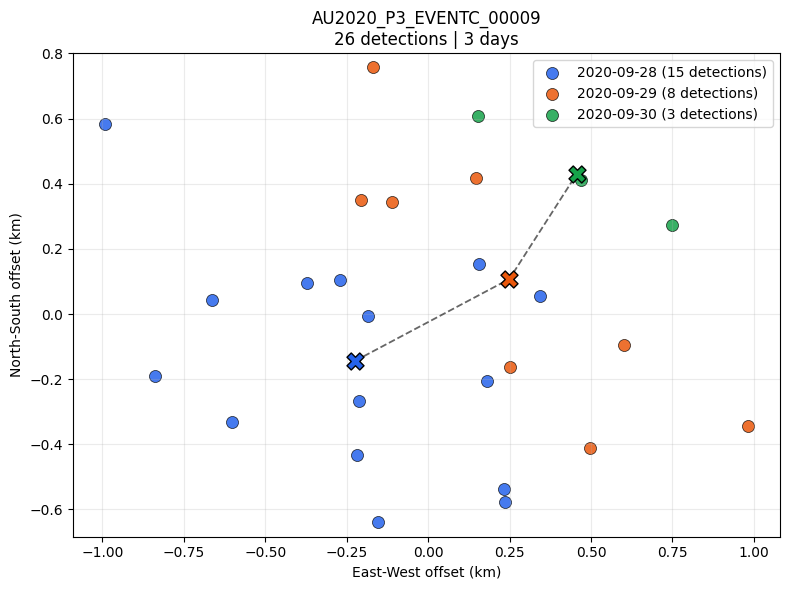

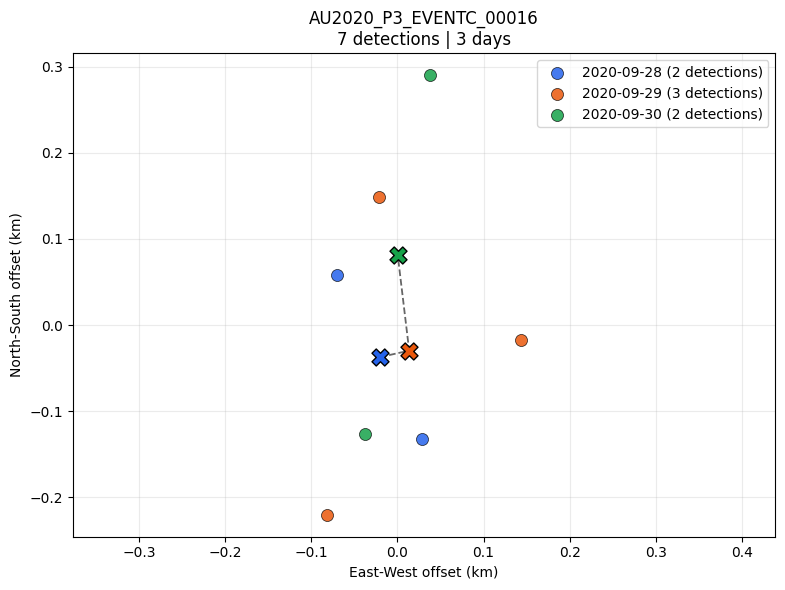

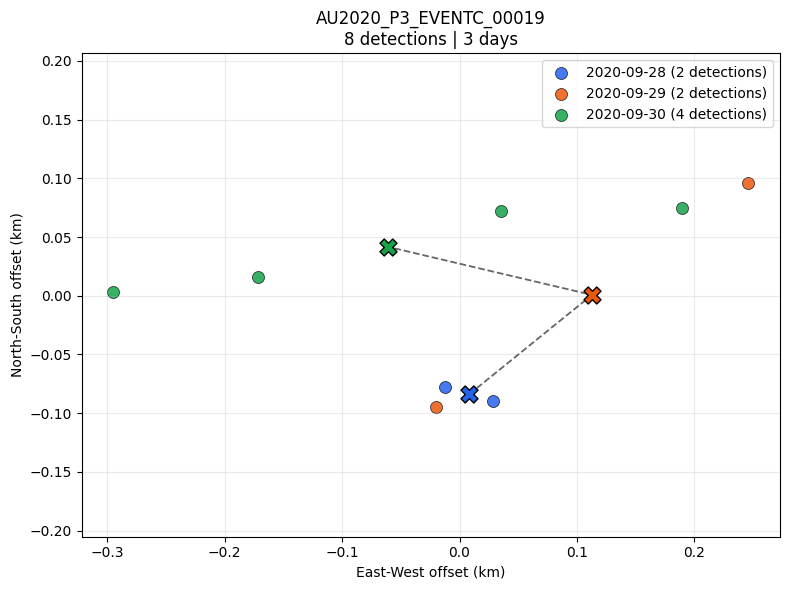

Static geographic review completed!


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Three-day candidate events
review_ids = [
    "AU2020_P3_EVENTC_00009",
    "AU2020_P3_EVENTC_00016",
    "AU2020_P3_EVENTC_00019"
]

colors = {
    "2020-09-28": "#2563EB",
    "2020-09-29": "#EA580C",
    "2020-09-30": "#16A34A"
}

KM_PER_DEGREE = 111.195

for event_id in review_ids:

    group = event_detection_data.loc[
        event_detection_data["candidate_event_id"]
        == event_id
    ].copy()

    assert not group.empty

    # Local projection: approximate km offsets
    # This is for visual diagnosis, not area measurement.
    lat0 = group["latitude"].mean()
    lon0 = group["longitude"].mean()

    group["x_km"] = (
        (group["longitude"] - lon0)
        * KM_PER_DEGREE
        * np.cos(np.radians(lat0))
    )

    group["y_km"] = (
        (group["latitude"] - lat0)
        * KM_PER_DEGREE
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    daily_centers = []

    for day, part in group.groupby("utc_date"):

        day_str = str(day)

        ax.scatter(
            part["x_km"],
            part["y_km"],
            s=75,
            c=colors[day_str],
            edgecolors="black",
            linewidths=0.5,
            alpha=0.85,
            label=f"{day_str} ({len(part)} detections)"
        )

        cx = part["x_km"].mean()
        cy = part["y_km"].mean()

        daily_centers.append((cx, cy))

        ax.scatter(
            cx, cy,
            marker="X",
            s=150,
            c=colors[day_str],
            edgecolors="black",
            linewidths=1.0,
            zorder=5
        )

    # A reference sequence, NOT the real fire movement
    centers = np.array(daily_centers)

    ax.plot(
        centers[:, 0],
        centers[:, 1],
        linestyle="--",
        color="black",
        alpha=0.6,
        linewidth=1.3
    )

    ax.set_title(
        f"{event_id}\n"
        f"{len(group)} detections | "
        f"{group['utc_date'].nunique()} days"
    )

    ax.set_xlabel("East-West offset (km)")
    ax.set_ylabel("North-South offset (km)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.25)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

print("Static geographic review completed!")

## **Event Separation & Neighborhood Audit**

In [36]:
from itertools import combinations
from sklearn.neighbors import BallTree
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088
NEIGHBOR_RADIUS_KM = 1.0

review_ids = [
    "AU2020_P3_EVENTC_00009",
    "AU2020_P3_EVENTC_00016",
    "AU2020_P3_EVENTC_00019"
]

# ==========================================
# 1. Prepare complete detection-level data
# ==========================================

all_points = (
    assignments_3d[
        ["detection_id", "observation_cluster_id"]
    ]
    .merge(
        vegetation_3d[
            [
                "detection_id",
                "latitude",
                "longitude",
                "acquisition_datetime_utc",
                "utc_date"
            ]
        ],
        on="detection_id",
        validate="one_to_one"
    )
    .merge(
        detection_event_relationships[
            ["detection_id", "candidate_event_id"]
        ],
        on="detection_id",
        validate="one_to_one"
    )
    .reset_index(drop=True)
)

assert len(all_points) == 11195
assert all_points["detection_id"].is_unique

# ==========================================
# 2. Compare the three-day tracks directly
# ==========================================

separation_rows = []

for event_a, event_b in combinations(review_ids, 2):

    a = all_points.loc[
        all_points["candidate_event_id"] == event_a
    ]

    b = all_points.loc[
        all_points["candidate_event_id"] == event_b
    ]

    coords_a = np.radians(
        a[["latitude", "longitude"]].to_numpy()
    )
    coords_b = np.radians(
        b[["latitude", "longitude"]].to_numpy()
    )

    distances = (
        haversine_distances(coords_a, coords_b) * R
    )

    center_a = np.radians([[
        a["latitude"].mean(),
        a["longitude"].mean()
    ]])

    center_b = np.radians([[
        b["latitude"].mean(),
        b["longitude"].mean()
    ]])

    center_distance = (
        haversine_distances(center_a, center_b)[0, 0]
        * R
    )

    separation_rows.append({
        "Event_A": event_a.rsplit("_", 1)[-1],
        "Event_B": event_b.rsplit("_", 1)[-1],
        "Closest_Detections_km": distances.min(),
        "Center_Distance_km": center_distance
    })

three_day_separation = pd.DataFrame(separation_rows)

print("===== THREE-DAY EVENT SEPARATION =====")
display(three_day_separation.round(3))

# ==========================================
# 3. Search neighboring detections
# ==========================================

event_labels = (
    all_points["candidate_event_id"]
    .fillna("UNLINKED")
    .to_numpy()
)

cluster_labels = (
    all_points["observation_cluster_id"].to_numpy()
)

detection_ids = all_points["detection_id"].to_numpy()
days = all_points["utc_date"].astype(str).to_numpy()

times = (
    all_points["acquisition_datetime_utc"]
    .astype("int64")
    .to_numpy()
)

coords = np.radians(
    all_points[["latitude", "longitude"]].to_numpy()
)

seed_indices = np.flatnonzero(
    event_labels != "UNLINKED"
)

assert len(seed_indices) == 522

tree = BallTree(coords, metric="haversine")

neighbors, angular_distances = tree.query_radius(
    coords[seed_indices],
    r=NEIGHBOR_RADIUS_KM / R,
    return_distance=True
)

rows = []

for i, indices, distances in zip(
    seed_indices, neighbors, angular_distances
):

    for j, angular_distance in zip(
        indices, distances
    ):

        # Exclude detections in the same candidate event
        if event_labels[i] == event_labels[j]:
            continue

        rows.append({
            "candidate_event_id": event_labels[i],
            "neighbor_cluster_id": cluster_labels[j],
            "neighbor_event_id": event_labels[j],
            "event_detection_id": detection_ids[i],
            "neighbor_detection_id": detection_ids[j],
            "distance_km": float(
                angular_distance * R
            ),
            "same_utc_day": bool(days[i] == days[j]),
            "abs_time_gap_h": float(
                abs(times[j] - times[i]) / 3.6e12
            )
        })

neighbor_details = pd.DataFrame(rows)

# ==========================================
# 4. Aggregate by candidate event and
#    neighboring observation cluster
# ==========================================

if not neighbor_details.empty:

    neighbor_summary = (
        neighbor_details.groupby(
            [
                "candidate_event_id",
                "neighbor_cluster_id",
                "neighbor_event_id"
            ],
            as_index=False
        )
        .agg(
            detection_pairs=("distance_km", "size"),
            closest_distance_km=("distance_km", "min"),
            unique_event_detections=(
                "event_detection_id", "nunique"
            ),
            unique_neighbor_detections=(
                "neighbor_detection_id", "nunique"
            ),
            same_day_pairs=("same_utc_day", "sum"),
            min_abs_time_gap_h=("abs_time_gap_h", "min")
        )
    )

    neighbor_summary["cross_day_pairs"] = (
        neighbor_summary["detection_pairs"]
        - neighbor_summary["same_day_pairs"]
    )

else:
    neighbor_summary = pd.DataFrame(columns=[
        "candidate_event_id",
        "neighbor_cluster_id",
        "neighbor_event_id",
        "detection_pairs",
        "closest_distance_km",
        "unique_event_detections",
        "unique_neighbor_detections",
        "same_day_pairs",
        "min_abs_time_gap_h",
        "cross_day_pairs"
    ])

# ==========================================
# 5. Summarize all 39 candidate events
# ==========================================

summary_rows = []

for event_id in fire_event_candidates[
    "candidate_event_id"
]:

    part = neighbor_summary.loc[
        neighbor_summary["candidate_event_id"]
        == event_id
    ]

    summary_rows.append({
        "candidate_event_id": event_id,
        "neighbor_clusters": (
            part["neighbor_cluster_id"].nunique()
        ),
        "neighbor_candidate_events": (
            part.loc[
                part["neighbor_event_id"] != "UNLINKED",
                "neighbor_event_id"
            ].nunique()
        ),
        "unlinked_neighbor_clusters": (
            part.loc[
                part["neighbor_event_id"] == "UNLINKED",
                "neighbor_cluster_id"
            ].nunique()
        )
    })

event_neighborhood_report = pd.DataFrame(summary_rows)

print("\n===== EVENT NEIGHBORHOOD SUMMARY =====")
print(
    "Events with neighboring candidate events:",
    int(
        event_neighborhood_report[
            "neighbor_candidate_events"
        ].gt(0).sum()
    )
)

print(
    "Events near unlinked observation clusters:",
    int(
        event_neighborhood_report[
            "unlinked_neighbor_clusters"
        ].gt(0).sum()
    )
)

display(
    event_neighborhood_report.sort_values(
        [
            "neighbor_candidate_events",
            "unlinked_neighbor_clusters"
        ],
        ascending=False
    ).head(15)
)

# ==========================================
# 6. Focus on three-day candidate events
# ==========================================

print("\n===== THREE-DAY EVENT NEIGHBORHOODS =====")

display(
    event_neighborhood_report.loc[
        event_neighborhood_report[
            "candidate_event_id"
        ].isin(review_ids)
    ]
)

print("\n===== CLOSEST NEIGHBORS OF THREE-DAY EVENTS =====")

display(
    neighbor_summary.loc[
        neighbor_summary["candidate_event_id"].isin(
            review_ids
        )
    ].sort_values(
        ["candidate_event_id", "closest_distance_km"]
    ).groupby(
        "candidate_event_id", group_keys=False
    ).head(5).round(3)
)

# ==========================================
# 7. Validation
# ==========================================

assert len(event_neighborhood_report) == 39
assert event_neighborhood_report[
    "candidate_event_id"
].is_unique

assert len(three_day_separation) == 3

if not neighbor_summary.empty:
    assert neighbor_summary[
        "closest_distance_km"
    ].le(NEIGHBOR_RADIUS_KM + 1e-9).all()

print("\nEvent neighborhood audit completed!")

===== THREE-DAY EVENT SEPARATION =====


,Event_A,Event_B,Closest_Detections_km,Center_Distance_km
0,00009,00016,1480.048,1481.168
1,00009,00019,1706.074,1707.273
2,00016,00019,286.291,286.569



===== EVENT NEIGHBORHOOD SUMMARY =====
Events with neighboring candidate events: 0
Events near unlinked observation clusters: 24


,candidate_event_id,neighbor_clusters,neighbor_candidate_events,unlinked_neighbor_clusters
33,AU2020_P3_EVENTC_00034,8,0,8
28,AU2020_P3_EVENTC_00029,7,0,7
6,AU2020_P3_EVENTC_00007,4,0,4
20,AU2020_P3_EVENTC_00021,4,0,4
34,AU2020_P3_EVENTC_00035,4,0,4
9,AU2020_P3_EVENTC_00010,3,0,3
16,AU2020_P3_EVENTC_00017,3,0,3
35,AU2020_P3_EVENTC_00036,3,0,3
0,AU2020_P3_EVENTC_00001,2,0,2
3,AU2020_P3_EVENTC_00004,2,0,2



===== THREE-DAY EVENT NEIGHBORHOODS =====


,candidate_event_id,neighbor_clusters,neighbor_candidate_events,unlinked_neighbor_clusters
8,AU2020_P3_EVENTC_00009,0,0,0
15,AU2020_P3_EVENTC_00016,0,0,0
18,AU2020_P3_EVENTC_00019,0,0,0



===== CLOSEST NEIGHBORS OF THREE-DAY EVENTS =====


,candidate_event_id,neighbor_cluster_id,neighbor_event_id,detection_pairs,closest_distance_km,unique_event_detections,unique_neighbor_detections,same_day_pairs,min_abs_time_gap_h,cross_day_pairs



Event neighborhood audit completed!


## **Temporal Neighborhood Audit**

In [37]:
# =========================================
# 1. Review only unlinked neighbor clusters
# =========================================

nd = neighbor_details.loc[
    neighbor_details["neighbor_event_id"] == "UNLINKED"
].copy()

point_lookup = all_points.set_index("detection_id")

nd["event_cluster_id"] = (
    nd["event_detection_id"].map(
        point_lookup["observation_cluster_id"]
    )
)

nd["event_day"] = pd.to_datetime(
    nd["event_detection_id"].map(
        point_lookup["utc_date"]
    ),
    utc=True
)

nd["neighbor_day"] = pd.to_datetime(
    nd["neighbor_detection_id"].map(
        point_lookup["utc_date"]
    ),
    utc=True
)

assert nd[
    ["event_cluster_id", "event_day", "neighbor_day"]
].notna().all().all()

day_difference = (
    nd["neighbor_day"] - nd["event_day"]
).dt.days.abs()

# The original cross-day screen uses:
# adjacent dates, >1 hour, <=24 hours

nd["same_day"] = day_difference.eq(0)

nd["adjacent_eligible"] = (
    day_difference.eq(1)
    & nd["abs_time_gap_h"].gt(1)
    & nd["abs_time_gap_h"].le(24)
)

nd["other_time"] = ~(
    nd["same_day"] | nd["adjacent_eligible"]
)

print("===== NEIGHBOR TEMPORAL SUMMARY =====")
print("Detection-level neighbor pairs:", len(nd))
print("Same-day pairs:", int(nd["same_day"].sum()))
print(
    "Adjacent-day pairs within 1-24h:",
    int(nd["adjacent_eligible"].sum())
)
print(
    "Other temporal relationships:",
    int(nd["other_time"].sum())
)

# =========================================
# 2. Aggregate to cluster-pair level
# =========================================

review = (
    nd.groupby(
        [
            "candidate_event_id",
            "event_cluster_id",
            "neighbor_cluster_id"
        ],
        as_index=False
    )
    .agg(
        detection_pairs=("distance_km", "size"),
        closest_km=("distance_km", "min"),
        unique_event_detections=(
            "event_detection_id", "nunique"
        ),
        unique_neighbor_detections=(
            "neighbor_detection_id", "nunique"
        ),
        same_day_pairs=("same_day", "sum"),
        adjacent_eligible_pairs=(
            "adjacent_eligible", "sum"
        ),
        other_time_pairs=("other_time", "sum")
    )
)

# =========================================
# 3. Match to existing cluster-day links
# =========================================

cluster_days = (
    all_points.groupby("observation_cluster_id")[
        "utc_date"
    ].first()
)

day_e = pd.to_datetime(
    review["event_cluster_id"].map(cluster_days),
    utc=True
)

day_n = pd.to_datetime(
    review["neighbor_cluster_id"].map(cluster_days),
    utc=True
)

event_is_earlier = day_e < day_n

review["cluster_a"] = np.where(
    event_is_earlier,
    review["event_cluster_id"],
    review["neighbor_cluster_id"]
)

review["cluster_b"] = np.where(
    event_is_earlier,
    review["neighbor_cluster_id"],
    review["event_cluster_id"]
)

reference_columns = [
    "cluster_a",
    "cluster_b",
    "link_class",
    "min_coverage_pct",
    "center_distance_km",
    "unique_a",
    "unique_b",
    "between_observation_gap_h"
]

reference_links = links[
    reference_columns
].copy()

assert not reference_links.duplicated(
    ["cluster_a", "cluster_b"]
).any()

review = review.merge(
    reference_links,
    on=["cluster_a", "cluster_b"],
    how="left",
    validate="many_to_one"
)

review["has_screened_link"] = (
    review["link_class"].notna()
)

# =========================================
# 4. Identify why links were not selected
# =========================================

review["review_reason"] = np.select(
    [
        review["has_screened_link"]
        & review["link_class"].ne("mutual_unique"),

        review["has_screened_link"]
        & review["link_class"].eq("mutual_unique"),

        review["same_day_pairs"].gt(0)
        & review["adjacent_eligible_pairs"].eq(0)
    ],
    [
        "ambiguous_cross_day_link",
        "mutual_unique_failed_moderate",
        "same_day_proximity"
    ],
    default="other_spatial_proximity"
)

print("\n===== NEIGHBOR LINK CLASSIFICATION =====")

display(
    review["review_reason"]
    .value_counts()
    .rename_axis("review_reason")
    .reset_index(name="cluster_pair_count")
)

# =========================================
# 5. Analyze potentially relevant
#    cross-day neighbors
# =========================================

crossday_review = review.loc[
    review["adjacent_eligible_pairs"] > 0
].copy()

print("\n===== CROSS-DAY NEIGHBOR REVIEW =====")

print(
    "Event-cluster / neighbor-cluster pairs:",
    len(crossday_review)
)

print(
    "With existing screened cluster links:",
    int(crossday_review["has_screened_link"].sum())
)

display(
    crossday_review[
        [
            "candidate_event_id",
            "event_cluster_id",
            "neighbor_cluster_id",
            "closest_km",
            "adjacent_eligible_pairs",
            "link_class",
            "min_coverage_pct",
            "center_distance_km",
            "unique_a",
            "unique_b",
            "review_reason"
        ]
    ].sort_values(
        [
            "adjacent_eligible_pairs",
            "closest_km"
        ],
        ascending=[False, True]
    ).head(15).round(3)
)

# =========================================
# 6. Overall neighborhood review priority
# =========================================

print("\n===== TOP NEIGHBORS FOR REVIEW =====")

display(
    review.sort_values(
        [
            "adjacent_eligible_pairs",
            "same_day_pairs",
            "closest_km"
        ],
        ascending=[False, False, True]
    )[
        [
            "candidate_event_id",
            "neighbor_cluster_id",
            "detection_pairs",
            "closest_km",
            "same_day_pairs",
            "adjacent_eligible_pairs",
            "other_time_pairs",
            "review_reason"
        ]
    ].head(15).round(3)
)

# =========================================
# 7. Integrity checks
# =========================================

assert len(review) > 0

assert (
    nd[[
        "same_day",
        "adjacent_eligible",
        "other_time"
    ]].sum(axis=1) == 1
).all()

assert review["closest_km"].le(1.0 + 1e-9).all()

assert (
    review["detection_pairs"].sum() == len(nd)
)

assert (
    review[
        ["same_day_pairs",
         "adjacent_eligible_pairs",
         "other_time_pairs"]
    ].sum().sum() == len(nd)
)

print("\nTemporal neighborhood audit passed!")

===== NEIGHBOR TEMPORAL SUMMARY =====
Detection-level neighbor pairs: 1113
Same-day pairs: 320
Adjacent-day pairs within 1-24h: 155
Other temporal relationships: 638

===== NEIGHBOR LINK CLASSIFICATION =====


,review_reason,cluster_pair_count
0,other_spatial_proximity,63
1,same_day_proximity,23
2,ambiguous_cross_day_link,9
3,mutual_unique_failed_moderate,6



===== CROSS-DAY NEIGHBOR REVIEW =====
Event-cluster / neighbor-cluster pairs: 15
With existing screened cluster links: 15


,candidate_event_id,event_cluster_id,neighbor_cluster_id,closest_km,adjacent_eligible_pairs,link_class,min_coverage_pct,center_distance_km,unique_a,unique_b,review_reason
57,AU2020_P3_EVENTC_00029,AU20200929_OCV2_00341,AU20200928_OCV2_00269,0.074,74,split_candidate,61.54,0.542,24.0,7.0,ambiguous_cross_day_link
14,AU2020_P3_EVENTC_00007,AU20200929_OCV2_00140,AU20200930_OCV2_00095,0.410,15,many_to_many,20.69,2.056,6.0,6.0,ambiguous_cross_day_link
30,AU2020_P3_EVENTC_00015,AU20200929_OCV2_00153,AU20200930_OCV2_00166,0.095,13,mutual_unique,43.75,0.807,7.0,4.0,mutual_unique_failed_moderate
13,AU2020_P3_EVENTC_00007,AU20200929_OCV2_00140,AU20200930_OCV2_00094,0.364,13,split_candidate,40.00,0.991,4.0,5.0,ambiguous_cross_day_link
77,AU2020_P3_EVENTC_00034,AU20200929_OCV2_00380,AU20200928_OCV2_00651,0.189,10,many_to_many,60.00,0.414,2.0,6.0,ambiguous_cross_day_link
35,AU2020_P3_EVENTC_00017,AU20200929_OCV2_00320,AU20200930_OCV2_00296,0.203,10,split_candidate,33.33,0.256,5.0,2.0,ambiguous_cross_day_link
22,AU2020_P3_EVENTC_00010,AU20200929_OCV2_00329,AU20200930_OCV2_00305,0.062,4,mutual_unique,40.00,0.274,2.0,2.0,mutual_unique_failed_moderate
38,AU2020_P3_EVENTC_00021,AU20200929_OCV2_00120,AU20200928_OCV2_00250,0.535,4,mutual_unique,16.67,1.621,2.0,3.0,mutual_unique_failed_moderate
36,AU2020_P3_EVENTC_00017,AU20200929_OCV2_00320,AU20200930_OCV2_00299,0.131,2,split_candidate,13.33,1.115,2.0,1.0,ambiguous_cross_day_link
3,AU2020_P3_EVENTC_00001,AU20200929_OCV2_00039,AU20200930_OCV2_00014,0.253,2,merge_candidate,100.00,0.447,2.0,1.0,ambiguous_cross_day_link



===== TOP NEIGHBORS FOR REVIEW =====


,candidate_event_id,neighbor_cluster_id,detection_pairs,closest_km,same_day_pairs,adjacent_eligible_pairs,other_time_pairs,review_reason
57,AU2020_P3_EVENTC_00029,AU20200928_OCV2_00269,129,0.074,0,74,55,ambiguous_cross_day_link
14,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00095,30,0.410,0,15,15,ambiguous_cross_day_link
30,AU2020_P3_EVENTC_00015,AU20200930_OCV2_00166,46,0.095,0,13,33,mutual_unique_failed_moderate
13,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00094,29,0.364,0,13,16,ambiguous_cross_day_link
77,AU2020_P3_EVENTC_00034,AU20200928_OCV2_00651,18,0.189,0,10,8,ambiguous_cross_day_link
35,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00296,24,0.203,0,10,14,ambiguous_cross_day_link
22,AU2020_P3_EVENTC_00010,AU20200930_OCV2_00305,10,0.062,0,4,6,mutual_unique_failed_moderate
38,AU2020_P3_EVENTC_00021,AU20200928_OCV2_00250,9,0.535,0,4,5,mutual_unique_failed_moderate
36,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00299,6,0.131,0,2,4,ambiguous_cross_day_link
3,AU2020_P3_EVENTC_00001,AU20200930_OCV2_00014,2,0.253,0,2,0,ambiguous_cross_day_link



Temporal neighborhood audit passed!


In [38]:
from sklearn.metrics.pairwise import haversine_distances

R = 6371.0088

# ==========================================
# 1. The 15 eligible cross-day neighbor links
# ==========================================

candidates = crossday_review.copy()

assert len(candidates) == 15
assert candidates["has_screened_link"].all()

cluster_day_lookup = (
    all_points.groupby("observation_cluster_id")[
        "utc_date"
    ].first().astype(str).to_dict()
)

event_day_lookup = (
    all_points.dropna(subset=["candidate_event_id"])
    .groupby("candidate_event_id")["utc_date"]
    .agg(lambda values: set(values.astype(str)))
    .to_dict()
)

# Network degree on each day boundary
degree_a = (
    links.groupby(["day_pair", "cluster_a"])[
        "cluster_b"
    ].nunique().to_dict()
)

degree_b = (
    links.groupby(["day_pair", "cluster_b"])[
        "cluster_a"
    ].nunique().to_dict()
)

link_day_lookup = links.set_index(
    ["cluster_a", "cluster_b"]
)["day_pair"].to_dict()

# ==========================================
# 2. Inspect each possible addition
# ==========================================

rows = []

for row in candidates.itertuples(index=False):

    event_id = row.candidate_event_id
    neighbor_id = row.neighbor_cluster_id

    existing_days = event_day_lookup[event_id]
    neighbor_day = cluster_day_lookup[neighbor_id]

    relationship_type = (
        "missing_day_extension"
        if neighbor_day not in existing_days
        else "already_covered_day"
    )

    event_points = all_points.loc[
        all_points["candidate_event_id"] == event_id
    ]

    neighbor_points = all_points.loc[
        all_points["observation_cluster_id"] == neighbor_id
    ]

    # Existing event diameter (detection centers)
    event_coords = np.radians(
        event_points[
            ["latitude", "longitude"]
        ].to_numpy()
    )

    existing_diameter = float(
        haversine_distances(event_coords).max() * R
    )

    # Hypothetical combined diameter
    neighbor_coords = np.radians(
        neighbor_points[
            ["latitude", "longitude"]
        ].to_numpy()
    )

    combined_coords = np.vstack([
        event_coords, neighbor_coords
    ])

    proposed_diameter = float(
        haversine_distances(combined_coords).max() * R
    )

    # Explain why Moderate did not select the link
    failed = []

    if row.link_class != "mutual_unique":
        failed.append("network_ambiguity")

    if row.center_distance_km > 1.0:
        failed.append("center_gt_1km")

    if row.min_coverage_pct < 50:
        failed.append("coverage_lt_50pct")

    if min(row.unique_a, row.unique_b) < 2:
        failed.append("support_lt_2")

    if not (
        0 <= row.between_observation_gap_h <= 24
    ):
        failed.append("gap_outside_0_24h")

    pair_key = (
        row.cluster_a,
        row.cluster_b
    )

    day_pair = link_day_lookup[pair_key]

    rows.append({
        "candidate_event_id": event_id,
        "neighbor_cluster_id": neighbor_id,
        "relationship_type": relationship_type,
        "neighbor_day": neighbor_day,
        "link_class": row.link_class,
        "eligible_detection_pairs": int(
            row.adjacent_eligible_pairs
        ),
        "unique_a": int(row.unique_a),
        "unique_b": int(row.unique_b),
        "min_coverage_pct": row.min_coverage_pct,
        "center_distance_km": row.center_distance_km,
        "boundary_gap_h": row.between_observation_gap_h,
        "out_degree": degree_a[
            (day_pair, row.cluster_a)
        ],
        "in_degree": degree_b[
            (day_pair, row.cluster_b)
        ],
        "existing_diameter_km": existing_diameter,
        "hypothetical_diameter_km": proposed_diameter,
        "diameter_increase_km": (
            proposed_diameter - existing_diameter
        ),
        "exclusion_factors": ", ".join(failed)
    })

extension_audit = pd.DataFrame(rows)

# ==========================================
# 3. Results
# ==========================================

print("===== EXTENSION VS COMPETITION =====")

display(
    extension_audit.groupby(
        ["relationship_type", "link_class"]
    ).agg(
        Cluster_Links=(
            "neighbor_cluster_id", "size"
        ),
        Affected_Events=(
            "candidate_event_id", "nunique"
        ),
        Eligible_Detection_Pairs=(
            "eligible_detection_pairs", "sum"
        )
    )
)

print("\n===== MODERATE EXCLUSION FACTORS =====")

from collections import Counter

factor_counts = Counter(
    factor
    for value in extension_audit["exclusion_factors"]
    for factor in value.split(", ")
    if factor
)

display(
    pd.DataFrame(
        factor_counts.items(),
        columns=["Exclusion_Factor", "Links"]
    ).sort_values("Links", ascending=False)
)

print("\n===== FULL CANDIDATE REVIEW =====")

display(
    extension_audit.sort_values(
        ["eligible_detection_pairs",
         "diameter_increase_km"],
        ascending=[False, True]
    ).round(3)
)

print("\n===== MISSING-DAY EXTENSIONS =====")

display(
    extension_audit.loc[
        extension_audit["relationship_type"]
        == "missing_day_extension"
    ].sort_values(
        "eligible_detection_pairs",
        ascending=False
    ).round(3)
)

# ==========================================
# 4. Integrity checks
# ==========================================

assert len(extension_audit) == 15

assert extension_audit[
    "neighbor_cluster_id"
].notna().all()

assert extension_audit[
    "hypothetical_diameter_km"
].ge(
    extension_audit["existing_diameter_km"] - 1e-8
).all()

assert set(extension_audit["relationship_type"]).issubset({
    "missing_day_extension",
    "already_covered_day"
})

print("\nExtension/competition audit passed!")
print("Original 39 candidate events unchanged.")

===== EXTENSION VS COMPETITION =====


Cluster_Links  Affected_Events  \
relationship_type     link_class                                        
missing_day_extension many_to_many                 3                2   
                      merge_candidate              2                2   
                      mutual_unique                6                6   
                      split_candidate              4                3   

                                       Eligible_Detection_Pairs  
relationship_type     link_class                                 
missing_day_extension many_to_many                           27  
                      merge_candidate                         3  
                      mutual_unique                          26  
                      split_candidate                        99


===== MODERATE EXCLUSION FACTORS =====


,Exclusion_Factor,Links
0,network_ambiguity,9
2,coverage_lt_50pct,9
1,support_lt_2,7
3,center_gt_1km,5



===== FULL CANDIDATE REVIEW =====


,candidate_event_id,neighbor_cluster_id,relationship_type,neighbor_day,link_class,eligible_detection_pairs,unique_a,unique_b,min_coverage_pct,center_distance_km,boundary_gap_h,out_degree,in_degree,existing_diameter_km,hypothetical_diameter_km,diameter_increase_km,exclusion_factors
10,AU2020_P3_EVENTC_00029,AU20200928_OCV2_00269,missing_day_extension,2020-09-28,split_candidate,74,24,7,61.54,0.542,22.867,2,1,0.850,3.667,2.817,network_ambiguity
2,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00095,missing_day_extension,2020-09-30,many_to_many,15,6,6,20.69,2.056,23.683,2,3,1.897,4.626,2.729,"network_ambiguity, center_gt_1km, coverage_lt_..."
5,AU2020_P3_EVENTC_00015,AU20200930_OCV2_00166,missing_day_extension,2020-09-30,mutual_unique,13,7,4,43.75,0.807,22.833,1,1,1.668,1.973,0.305,coverage_lt_50pct
1,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00094,missing_day_extension,2020-09-30,split_candidate,13,4,5,40.00,0.991,23.683,2,1,1.897,2.518,0.621,"network_ambiguity, coverage_lt_50pct"
6,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00296,missing_day_extension,2020-09-30,split_candidate,10,5,2,33.33,0.256,23.683,2,1,3.050,3.050,0.000,"network_ambiguity, coverage_lt_50pct"
13,AU2020_P3_EVENTC_00034,AU20200928_OCV2_00651,missing_day_extension,2020-09-28,many_to_many,10,2,6,60.00,0.414,23.683,3,3,1.340,1.340,0.000,network_ambiguity
3,AU2020_P3_EVENTC_00010,AU20200930_OCV2_00305,missing_day_extension,2020-09-30,mutual_unique,4,2,2,40.00,0.274,23.700,1,1,1.829,1.880,0.052,coverage_lt_50pct
8,AU2020_P3_EVENTC_00021,AU20200928_OCV2_00250,missing_day_extension,2020-09-28,mutual_unique,4,2,3,16.67,1.621,23.683,1,1,1.670,4.437,2.767,"center_gt_1km, coverage_lt_50pct"
7,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00299,missing_day_extension,2020-09-30,split_candidate,2,2,1,13.33,1.115,23.683,2,1,3.050,3.050,0.000,"network_ambiguity, center_gt_1km, coverage_lt_..."
0,AU2020_P3_EVENTC_00001,AU20200930_OCV2_00014,missing_day_extension,2020-09-30,merge_candidate,2,2,1,100.00,0.447,23.683,1,2,0.593,0.647,0.054,"network_ambiguity, support_lt_2"



===== MISSING-DAY EXTENSIONS =====


,candidate_event_id,neighbor_cluster_id,relationship_type,neighbor_day,link_class,eligible_detection_pairs,unique_a,unique_b,min_coverage_pct,center_distance_km,boundary_gap_h,out_degree,in_degree,existing_diameter_km,hypothetical_diameter_km,diameter_increase_km,exclusion_factors
10,AU2020_P3_EVENTC_00029,AU20200928_OCV2_00269,missing_day_extension,2020-09-28,split_candidate,74,24,7,61.54,0.542,22.867,2,1,0.850,3.667,2.817,network_ambiguity
2,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00095,missing_day_extension,2020-09-30,many_to_many,15,6,6,20.69,2.056,23.683,2,3,1.897,4.626,2.729,"network_ambiguity, center_gt_1km, coverage_lt_..."
1,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00094,missing_day_extension,2020-09-30,split_candidate,13,4,5,40.00,0.991,23.683,2,1,1.897,2.518,0.621,"network_ambiguity, coverage_lt_50pct"
5,AU2020_P3_EVENTC_00015,AU20200930_OCV2_00166,missing_day_extension,2020-09-30,mutual_unique,13,7,4,43.75,0.807,22.833,1,1,1.668,1.973,0.305,coverage_lt_50pct
6,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00296,missing_day_extension,2020-09-30,split_candidate,10,5,2,33.33,0.256,23.683,2,1,3.050,3.050,0.000,"network_ambiguity, coverage_lt_50pct"
13,AU2020_P3_EVENTC_00034,AU20200928_OCV2_00651,missing_day_extension,2020-09-28,many_to_many,10,2,6,60.00,0.414,23.683,3,3,1.340,1.340,0.000,network_ambiguity
3,AU2020_P3_EVENTC_00010,AU20200930_OCV2_00305,missing_day_extension,2020-09-30,mutual_unique,4,2,2,40.00,0.274,23.700,1,1,1.829,1.880,0.052,coverage_lt_50pct
8,AU2020_P3_EVENTC_00021,AU20200928_OCV2_00250,missing_day_extension,2020-09-28,mutual_unique,4,2,3,16.67,1.621,23.683,1,1,1.670,4.437,2.767,"center_gt_1km, coverage_lt_50pct"
0,AU2020_P3_EVENTC_00001,AU20200930_OCV2_00014,missing_day_extension,2020-09-30,merge_candidate,2,2,1,100.00,0.447,23.683,1,2,0.593,0.647,0.054,"network_ambiguity, support_lt_2"
9,AU2020_P3_EVENTC_00026,AU20200928_OCV2_00314,missing_day_extension,2020-09-28,mutual_unique,2,2,1,50.00,0.965,23.683,1,1,1.283,1.862,0.579,support_lt_2



Extension/competition audit passed!
Original 39 candidate events unchanged.


##**Scientific Validation Dataset**

In [39]:
# ==========================================
# 1. Existing candidate events
# ==========================================

assert len(fire_event_candidates) == 39
assert len(extension_audit) == 15
assert len(cluster_info) == 1818

events = pd.DataFrame({
    "case_id": (
        "EVENT:" +
        fire_event_candidates["candidate_event_id"]
    ),
    "case_type": "tracked_candidate",
    "candidate_event_id":
        fire_event_candidates["candidate_event_id"],
    "observation_cluster_id": pd.NA,
    "latitude":
        fire_event_candidates["mean_detection_lat"],
    "longitude":
        fire_event_candidates["mean_detection_lon"],
    "start_utc":
        fire_event_candidates["first_observed_utc"],
    "end_utc":
        fire_event_candidates["last_observed_utc"],
    "review_reason":
        "Check thermal source and temporal continuity"
})

# ==========================================
# 2. Excluded potential extensions
# ==========================================

cluster_coordinates = cluster_info.reset_index()

extensions = extension_audit.merge(
    cluster_coordinates[
        [
            "observation_cluster_id",
            "center_lat",
            "center_lon",
            "start_time",
            "end_time"
        ]
    ],
    left_on="neighbor_cluster_id",
    right_on="observation_cluster_id",
    how="left",
    validate="many_to_one"
)

assert extensions["center_lat"].notna().all()

extension_cases = pd.DataFrame({
    "case_id": [
        f"EXTENSION:{i:03d}"
        for i in range(1, len(extensions) + 1)
    ],
    "case_type": "excluded_extension",
    "candidate_event_id":
        extensions["candidate_event_id"],
    "observation_cluster_id":
        extensions["neighbor_cluster_id"],
    "latitude":
        extensions["center_lat"],
    "longitude":
        extensions["center_lon"],
    "start_utc":
        extensions["start_time"],
    "end_utc":
        extensions["end_time"],
    "review_reason":
        extensions["exclusion_factors"]
})

# ==========================================
# 3. Sample unresolved observation clusters
# ==========================================

linked_clusters = set(
    track_memberships["observation_cluster_id"]
)

extension_clusters = set(
    extension_audit["neighbor_cluster_id"]
)

excluded_from_controls = (
    linked_clusters | extension_clusters
)

unresolved = cluster_info.loc[
    ~cluster_info.index.isin(excluded_from_controls)
].reset_index()

unresolved["day"] = (
    unresolved["start_time"]
    .dt.strftime("%Y-%m-%d")
)

# Reproducible diagnostic sample: 10 per day
controls = (
    unresolved.groupby("day", group_keys=False)
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)

control_cases = pd.DataFrame({
    "case_id": (
        "UNRESOLVED:" +
        controls["observation_cluster_id"]
    ),
    "case_type": "unresolved_sample",
    "candidate_event_id": pd.NA,
    "observation_cluster_id":
        controls["observation_cluster_id"],
    "latitude":
        controls["center_lat"],
    "longitude":
        controls["center_lon"],
    "start_utc":
        controls["start_time"],
    "end_utc":
        controls["end_time"],
    "review_reason":
        "No selected track; not a confirmed negative"
})

# ==========================================
# 4. Unified independent-review manifest
# ==========================================

validation_manifest = pd.concat(
    [events, extension_cases, control_cases],
    ignore_index=True
)

# Do not pre-assign scientific conclusions
validation_manifest["reference_source"] = pd.NA
validation_manifest["thermal_source_evidence"] = (
    "not_reviewed"
)
validation_manifest["continuity_evidence"] = (
    "not_reviewed"
)
validation_manifest["review_notes"] = pd.NA

# ==========================================
# 5. Quality checks
# ==========================================

assert len(validation_manifest) == 84

assert validation_manifest["case_id"].is_unique

assert validation_manifest[
    ["latitude", "longitude",
     "start_utc", "end_utc"]
].notna().all().all()

assert validation_manifest["latitude"].between(
    -90, 90
).all()

assert validation_manifest["longitude"].between(
    -180, 180
).all()

assert (
    validation_manifest["start_utc"]
    <= validation_manifest["end_utc"]
).all()

# ==========================================
# 6. Reports
# ==========================================

print("===== SCIENTIFIC VALIDATION MANIFEST =====")

display(
    validation_manifest["case_type"]
    .value_counts()
    .rename_axis("case_type")
    .reset_index(name="cases")
)

print("\n===== EXCLUDED EXTENSIONS FOR REVIEW =====")

display(
    extension_audit[
        [
            "candidate_event_id",
            "neighbor_cluster_id",
            "link_class",
            "eligible_detection_pairs",
            "min_coverage_pct",
            "existing_diameter_km",
            "hypothetical_diameter_km",
            "exclusion_factors"
        ]
    ].sort_values(
        "eligible_detection_pairs",
        ascending=False
    ).head(10).round(3)
)

print("\n===== UNRESOLVED SAMPLE BY DAY =====")

display(
    controls.groupby("day")
    .size()
    .rename("sampled_clusters")
)

print("\nValidation manifest integrity checks passed!")
print("Scientific evidence has NOT yet been reviewed.")

===== SCIENTIFIC VALIDATION MANIFEST =====


,case_type,cases
0,tracked_candidate,39
1,unresolved_sample,30
2,excluded_extension,15



===== EXCLUDED EXTENSIONS FOR REVIEW =====


,candidate_event_id,neighbor_cluster_id,link_class,eligible_detection_pairs,min_coverage_pct,existing_diameter_km,hypothetical_diameter_km,exclusion_factors
10,AU2020_P3_EVENTC_00029,AU20200928_OCV2_00269,split_candidate,74,61.54,0.850,3.667,network_ambiguity
2,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00095,many_to_many,15,20.69,1.897,4.626,"network_ambiguity, center_gt_1km, coverage_lt_..."
1,AU2020_P3_EVENTC_00007,AU20200930_OCV2_00094,split_candidate,13,40.00,1.897,2.518,"network_ambiguity, coverage_lt_50pct"
5,AU2020_P3_EVENTC_00015,AU20200930_OCV2_00166,mutual_unique,13,43.75,1.668,1.973,coverage_lt_50pct
6,AU2020_P3_EVENTC_00017,AU20200930_OCV2_00296,split_candidate,10,33.33,3.050,3.050,"network_ambiguity, coverage_lt_50pct"
13,AU2020_P3_EVENTC_00034,AU20200928_OCV2_00651,many_to_many,10,60.00,1.340,1.340,network_ambiguity
3,AU2020_P3_EVENTC_00010,AU20200930_OCV2_00305,mutual_unique,4,40.00,1.829,1.880,coverage_lt_50pct
8,AU2020_P3_EVENTC_00021,AU20200928_OCV2_00250,mutual_unique,4,16.67,1.670,4.437,"center_gt_1km, coverage_lt_50pct"
0,AU2020_P3_EVENTC_00001,AU20200930_OCV2_00014,merge_candidate,2,100.00,0.593,0.647,"network_ambiguity, support_lt_2"
9,AU2020_P3_EVENTC_00026,AU20200928_OCV2_00314,mutual_unique,2,50.00,1.283,1.862,support_lt_2



===== UNRESOLVED SAMPLE BY DAY =====


,sampled_clusters
day,
2020-09-28,10
2020-09-29,10
2020-09-30,10



Validation manifest integrity checks passed!
Scientific evidence has NOT yet been reviewed.


## **Satellite Reference Discovery**

In [40]:
%pip -q install pystac-client

In [41]:
from pystac_client import Client

# ==========================================
# 1. Select the first five review cases
# ==========================================

case_specs = [
    ("AU2020_P3_EVENTC_00009", None),
    ("AU2020_P3_EVENTC_00016", None),
    ("AU2020_P3_EVENTC_00019", None),
    ("AU2020_P3_EVENTC_00029",
     "AU20200928_OCV2_00269"),
    ("AU2020_P3_EVENTC_00015",
     "AU20200930_OCV2_00166")
]

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

collections = [
    "sentinel-2-l2a",
    "landsat-c2-l2"
]

search_rows = []
scene_rows = []

# ==========================================
# 2. Search for historical imagery
# ==========================================

for event_id, extra_cluster in case_specs:

    mask = (
        all_points["candidate_event_id"] == event_id
    )

    # Include the excluded cluster in extension cases
    if extra_cluster is not None:
        mask = mask | (
            all_points["observation_cluster_id"]
            == extra_cluster
        )

    group = all_points.loc[mask].copy()

    assert not group.empty

    start_day = pd.to_datetime(
        group["acquisition_datetime_utc"].min(),
        utc=True
    ).normalize()

    end_day = pd.to_datetime(
        group["acquisition_datetime_utc"].max(),
        utc=True
    ).normalize()

    # Approximate 3 km geographic padding
    lat0 = group["latitude"].mean()
    pad_lat = 3.0 / 111.195
    pad_lon = 3.0 / (
        111.195 * np.cos(np.radians(lat0))
    )

    bbox = [
        float(group["longitude"].min() - pad_lon),
        float(group["latitude"].min() - pad_lat),
        float(group["longitude"].max() + pad_lon),
        float(group["latitude"].max() + pad_lat)
    ]

    window_start = (
        start_day - pd.Timedelta(days=30)
    ).strftime("%Y-%m-%d")

    window_end = (
        end_day + pd.Timedelta(days=30)
    ).strftime("%Y-%m-%d")

    print(f"Searching: {event_id}")

    try:
        search = catalog.search(
            collections=collections,
            bbox=bbox,
            datetime=f"{window_start}/{window_end}",
            max_items=250
        )

        scenes = list(search.items())

        search_status = "success"

    except Exception as exc:
        scenes = []
        search_status = (
            f"search_error: {type(exc).__name__}"
        )
        print("Search error:", exc)

    search_rows.append({
        "candidate_event_id": event_id,
        "search_status": search_status,
        "scenes_returned": len(scenes),
        "latitude": round(lat0, 5),
        "longitude": round(
            group["longitude"].mean(), 5
        ),
        "start_day": start_day.date(),
        "end_day": end_day.date()
    })

    for item in scenes:

        acquired = pd.Timestamp(
            item.datetime
        ).tz_convert("UTC")

        scene_day = acquired.normalize()

        if scene_day < start_day:
            phase = "before"
            distance_days = (
                start_day - scene_day
            ).days

        elif scene_day > end_day:
            phase = "after"
            distance_days = (
                scene_day - end_day
            ).days

        else:
            phase = "during"
            distance_days = 0

        scene_rows.append({
            "candidate_event_id": event_id,
            "collection": item.collection_id,
            "scene_id": item.id,
            "acquired_utc": acquired,
            "phase": phase,
            "days_from_event": distance_days,
            "scene_cloud_pct": item.properties.get(
                "eo:cloud_cover"
            )
        })

reference_search_report = pd.DataFrame(
    search_rows
)

reference_scenes = pd.DataFrame(scene_rows)

# ==========================================
# 3. Select scenes for visual review
# ==========================================

if not reference_scenes.empty:

    eligible = reference_scenes.loc[
        reference_scenes["phase"].isin(
            ["before", "after"]
        )
    ].copy()

    # Cloud cover is scene-level, not AOI-level
    eligible["cloud_acceptable"] = (
        eligible["scene_cloud_pct"].le(30)
    )

    eligible = eligible.sort_values(
        [
            "candidate_event_id",
            "collection",
            "phase",
            "cloud_acceptable",
            "days_from_event",
            "scene_cloud_pct"
        ],
        ascending=[
            True, True, True, False, True, True
        ]
    )

    reference_scene_shortlist = (
        eligible.groupby(
            ["candidate_event_id", "collection", "phase"],
            as_index=False
        ).head(1).reset_index(drop=True)
    )

else:
    reference_scene_shortlist = pd.DataFrame()

# ==========================================
# 4. Reports
# ==========================================

print("\n===== REFERENCE SEARCH REPORT =====")
display(reference_search_report)

print("\n===== REFERENCE SCENE SHORTLIST =====")

if not reference_scene_shortlist.empty:
    display(
        reference_scene_shortlist[
            [
                "candidate_event_id",
                "collection",
                "phase",
                "acquired_utc",
                "days_from_event",
                "scene_cloud_pct",
                "scene_id"
            ]
        ]
    )
else:
    print("No reference scenes returned.")

print("\nReference scene discovery completed.")
print("Imagery has NOT been independently validated.")


Searching: AU2020_P3_EVENTC_00009
Searching: AU2020_P3_EVENTC_00016
Searching: AU2020_P3_EVENTC_00019
Searching: AU2020_P3_EVENTC_00029
Searching: AU2020_P3_EVENTC_00015

===== REFERENCE SEARCH REPORT =====


,candidate_event_id,search_status,scenes_returned,latitude,longitude,start_day,end_day
0,AU2020_P3_EVENTC_00009,success,21,-13.20341,136.15392,2020-09-28,2020-09-30
1,AU2020_P3_EVENTC_00016,success,20,-20.53869,147.78465,2020-09-28,2020-09-30
2,AU2020_P3_EVENTC_00019,success,20,-22.99737,148.61653,2020-09-28,2020-09-30
3,AU2020_P3_EVENTC_00029,success,32,-25.69892,150.81585,2020-09-28,2020-09-30
4,AU2020_P3_EVENTC_00015,success,21,-11.91565,135.80679,2020-09-28,2020-09-30



===== REFERENCE SCENE SHORTLIST =====


,candidate_event_id,collection,phase,acquired_utc,days_from_event,scene_cloud_pct,scene_id
0,AU2020_P3_EVENTC_00009,landsat-c2-l2,after,2020-10-11 00:22:43.178906+00:00,11,11.000000,LE07_L2SP_102069_20201011_02_T1
1,AU2020_P3_EVENTC_00009,landsat-c2-l2,before,2020-09-25 00:23:44.040360+00:00,3,12.000000,LE07_L2SP_102069_20200925_02_T1
2,AU2020_P3_EVENTC_00009,sentinel-2-l2a,after,2020-10-05 01:17:29.024000+00:00,5,40.004163,S2B_MSIL2A_20201005T011729_R088_T53LPF_2020100...
3,AU2020_P3_EVENTC_00009,sentinel-2-l2a,before,2020-09-25 01:17:29.024000+00:00,3,5.883528,S2B_MSIL2A_20200925T011729_R088_T53LPF_2020092...
4,AU2020_P3_EVENTC_00015,landsat-c2-l2,after,2020-10-02 00:29:04.558053+00:00,2,4.000000,LE07_L2SP_103068_20201002_02_T1
5,AU2020_P3_EVENTC_00015,landsat-c2-l2,before,2020-09-24 01:04:32.721989+00:00,4,12.340000,LC08_L2SP_103068_20200924_02_T1
6,AU2020_P3_EVENTC_00015,sentinel-2-l2a,after,2020-10-10 01:17:31.024000+00:00,10,26.566719,S2A_MSIL2A_20201010T011731_R088_T53LNG_2020101...
7,AU2020_P3_EVENTC_00015,sentinel-2-l2a,before,2020-09-25 01:17:29.024000+00:00,3,4.583890,S2B_MSIL2A_20200925T011729_R088_T53LNG_2020092...
8,AU2020_P3_EVENTC_00016,landsat-c2-l2,after,2020-10-02 23:35:47.163239+00:00,2,25.000000,LE07_L2SP_094074_20201002_02_T1
9,AU2020_P3_EVENTC_00016,landsat-c2-l2,before,2020-09-25 00:11:19.239219+00:00,3,16.780000,LC08_L2SP_094074_20200925_02_T1



Reference scene discovery completed.
Imagery has NOT been independently validated.


Reading before-event imagery...
Reading after-event imagery...

===== IMAGE QUALITY =====
Pre date: 2020-09-27 00:20:59.024000+00:00
Post date: 2020-10-02 00:21:01.024000+00:00
Pre processing baseline: 02.12
Post processing baseline: 02.12
Grid: 112 x 126
Pre clear-land coverage (%): 78.1
Post clear-land coverage (%): 82.96
Common valid coverage (%): 77.11
Pre SCL class-2 pixels (%): 21.82
Post SCL class-2 pixels (%): 17.01

===== NBR / dNBR STATISTICS =====
Median NBR before: -0.1442
Median NBR after: -0.1139
Median dNBR: -0.0308
95th percentile dNBR: 0.0004


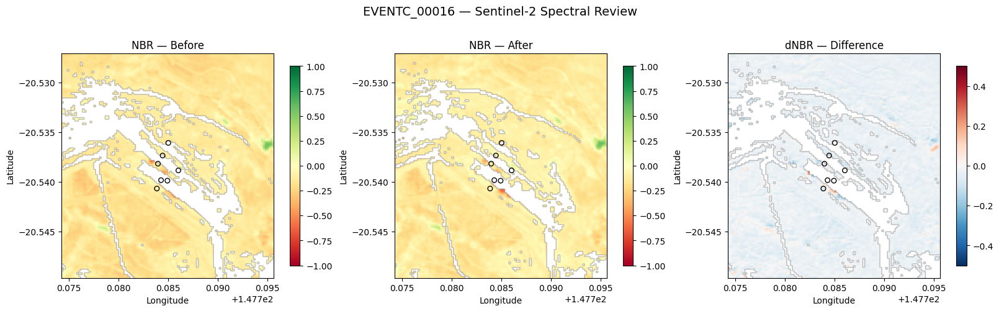


===== REVIEW STATUS =====
Clear-land overlap >= 70%.
No fire validation label assigned.


In [42]:
%pip -q install planetary-computer rasterio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.transform import from_bounds

EVENT_ID = "AU2020_P3_EVENTC_00016"

# ==========================================
# 1. Retrieve the two selected scenes
# ==========================================

selected = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == EVENT_ID)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
].copy()

assert set(selected["phase"]) == {"before", "after"}
assert len(selected) == 2

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

collection = catalog.get_collection("sentinel-2-l2a")

pre_id = selected.loc[
    selected["phase"] == "before", "scene_id"
].iloc[0]

post_id = selected.loc[
    selected["phase"] == "after", "scene_id"
].iloc[0]

pre_item = collection.get_item(pre_id)
post_item = collection.get_item(post_id)

assert pre_item is not None
assert post_item is not None

# ==========================================
# 2. Define a small common geographic grid
# ==========================================

points = event_detection_data.loc[
    event_detection_data["candidate_event_id"] == EVENT_ID
].copy()

assert len(points) == 7

lat0 = points["latitude"].mean()
padding_km = 1.0

lat_pad = padding_km / 111.195
lon_pad = padding_km / (
    111.195 * np.cos(np.radians(lat0))
)

west = points["longitude"].min() - lon_pad
east = points["longitude"].max() + lon_pad
south = points["latitude"].min() - lat_pad
north = points["latitude"].max() + lat_pad

# Common approximate 20 m grid
width = max(
    1, int(np.ceil(
        (east - west) * 111195
        * np.cos(np.radians(lat0)) / 20
    ))
)

height = max(
    1, int(np.ceil(
        (north - south) * 111195 / 20
    ))
)

transform = from_bounds(
    west, south, east, north, width, height
)

# ==========================================
# 3. Read small windows on the same grid
# ==========================================

def read_band(item, band, categorical=False):

    method = (
        Resampling.nearest
        if categorical
        else Resampling.bilinear
    )

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
    ):
        with rasterio.open(item.assets[band].href) as src:

            with WarpedVRT(
                src,
                crs="EPSG:4326",
                transform=transform,
                width=width,
                height=height,
                resampling=method
            ) as vrt:

                data = vrt.read(1, masked=True)

    return data.astype("float32").filled(np.nan)


def calculate_nbr(item):

    nir_dn = read_band(item, "B08")
    swir_dn = read_band(item, "B12")
    scl = read_band(item, "SCL", categorical=True)

    # Older Sentinel-2 products have no
    # BOA additive offset. Newer baselines do.
    baseline = item.properties.get(
        "s2:processing_baseline"
    )

    if baseline is None:
        raise ValueError(
            "Processing baseline missing: "
            "check reflectance calibration first."
        )

    baseline_number = float(
        str(baseline).replace("N", "")
    )

    offset_dn = (
        -1000.0 if baseline_number >= 4.0 else 0.0
    )

    nir = (nir_dn + offset_dn) / 10000.0
    swir = (swir_dn + offset_dn) / 10000.0

    # Core clear-land SCL classes.
    # Class 2 dark pixels are flagged for review.
    clear_land = np.isin(scl, [4, 5, 7])

    valid = (
        clear_land
        & np.isfinite(nir)
        & np.isfinite(swir)
        & (nir_dn > 0)
        & (swir_dn > 0)
        & (np.abs(nir + swir) > 1e-6)
    )

    nbr = np.full(nir.shape, np.nan, dtype="float32")

    nbr[valid] = (
        (nir[valid] - swir[valid])
        / (nir[valid] + swir[valid])
    )

    return nbr, valid, scl, baseline


print("Reading before-event imagery...")
nbr_pre, valid_pre, scl_pre, baseline_pre = (
    calculate_nbr(pre_item)
)

print("Reading after-event imagery...")
nbr_post, valid_post, scl_post, baseline_post = (
    calculate_nbr(post_item)
)

# ==========================================
# 4. Calculate dNBR only on shared valid pixels
# ==========================================

common_valid = (
    valid_pre
    & valid_post
    & np.isfinite(nbr_pre)
    & np.isfinite(nbr_post)
)

dnbr = np.full(
    nbr_pre.shape, np.nan, dtype="float32"
)

dnbr[common_valid] = (
    nbr_pre[common_valid] - nbr_post[common_valid]
)

valid_count = int(common_valid.sum())
total_pixels = int(common_valid.size)

print("\n===== IMAGE QUALITY =====")
print("Pre date:", pre_item.datetime)
print("Post date:", post_item.datetime)
print("Pre processing baseline:", baseline_pre)
print("Post processing baseline:", baseline_post)
print("Grid:", width, "x", height)

print(
    "Pre clear-land coverage (%):",
    round(100 * valid_pre.mean(), 2)
)

print(
    "Post clear-land coverage (%):",
    round(100 * valid_post.mean(), 2)
)

print(
    "Common valid coverage (%):",
    round(100 * common_valid.mean(), 2)
)

print(
    "Pre SCL class-2 pixels (%):",
    round(100 * np.mean(scl_pre == 2), 2)
)

print(
    "Post SCL class-2 pixels (%):",
    round(100 * np.mean(scl_post == 2), 2)
)

# ==========================================
# 5. Preliminary spectral statistics
# ==========================================

print("\n===== NBR / dNBR STATISTICS =====")

if valid_count > 0:

    print(
        "Median NBR before:",
        round(float(np.nanmedian(nbr_pre[common_valid])), 4)
    )

    print(
        "Median NBR after:",
        round(float(np.nanmedian(nbr_post[common_valid])), 4)
    )

    print(
        "Median dNBR:",
        round(float(np.nanmedian(dnbr)), 4)
    )

    print(
        "95th percentile dNBR:",
        round(float(np.nanpercentile(dnbr, 95)), 4)
    )

else:
    print("No shared valid pixels; cannot compute dNBR.")

# ==========================================
# 6. Visualize before, after, and change
# ==========================================

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5),
    constrained_layout=True
)

extent = [west, east, south, north]

images = [
    (nbr_pre, "NBR — Before", "RdYlGn", -1, 1),
    (nbr_post, "NBR — After", "RdYlGn", -1, 1),
    (dnbr, "dNBR — Difference", "RdBu_r", -0.5, 0.5)
]

for ax, (data, title, cmap, vmin, vmax) in zip(
    axes, images
):

    im = ax.imshow(
        np.ma.masked_invalid(data),
        origin="upper",
        extent=extent,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.scatter(
        points["longitude"],
        points["latitude"],
        s=30,
        facecolors="none",
        edgecolors="black",
        linewidths=1
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    fig.colorbar(im, ax=ax, shrink=0.7)

plt.suptitle(
    "EVENTC_00016 — Sentinel-2 Spectral Review",
    fontsize=14
)

plt.show()

print("\n===== REVIEW STATUS =====")

if common_valid.mean() < 0.70:
    print("Warning: limited clear-land overlap.")
else:
    print("Clear-land overlap >= 70%.")

print("No fire validation label assigned.")

In [43]:
from rasterio.transform import rowcol

# EVENTC_00016: re-use previous cell variables
assert len(points) == 7
assert str(baseline_pre) == "02.12"
assert str(baseline_post) == "02.12"

# ==========================================
# 1. Recalculate NBR without the SCL mask
# ==========================================

def raw_nbr(item):
    nir_dn = read_band(item, "B08")
    swir_dn = read_band(item, "B12")

    # Baseline 02.12: reflectance = DN / 10000
    nir = nir_dn / 10000.0
    swir = swir_dn / 10000.0

    denominator = nir + swir

    valid = (
        np.isfinite(nir)
        & np.isfinite(swir)
        & (nir_dn > 0)
        & (swir_dn > 0)
        & (denominator > 0.01)
    )

    result = np.full(nir.shape, np.nan)

    result[valid] = (
        (nir[valid] - swir[valid])
        / denominator[valid]
    )

    return result, valid

raw_pre, valid_spectral_pre = raw_nbr(pre_item)
raw_post, valid_spectral_post = raw_nbr(post_item)

# Original classes versus exploratory inclusion
strict_pre = (
    np.isin(scl_pre, [4, 5, 7])
    & valid_spectral_pre
)
strict_post = (
    np.isin(scl_post, [4, 5, 7])
    & valid_spectral_post
)

exploratory_pre = (
    np.isin(scl_pre, [2, 4, 5, 7])
    & valid_spectral_pre
)
exploratory_post = (
    np.isin(scl_post, [2, 4, 5, 7])
    & valid_spectral_post
)

strict_both = strict_pre & strict_post
exploratory_both = (
    exploratory_pre & exploratory_post
)

change = raw_pre - raw_post

# ==========================================
# 2. Sample SCL at FIRMS detection centers
# ==========================================

rows = []

for p in points.itertuples(index=False):

    r, c = rowcol(
        transform,
        float(p.longitude),
        float(p.latitude)
    )

    assert 0 <= r < height
    assert 0 <= c < width

    rows.append({
        "detection_id": p.detection_id,
        "pre_SCL": int(scl_pre[r, c]),
        "post_SCL": int(scl_post[r, c]),
        "strict_valid": bool(strict_both[r, c]),
        "exploratory_valid": bool(
            exploratory_both[r, c]
        ),
        "exploratory_dNBR": (
            round(float(change[r, c]), 4)
            if exploratory_both[r, c]
            else np.nan
        )
    })

detection_scl_audit = pd.DataFrame(rows)

print("===== FIRMS POINT SCL AUDIT =====")
display(detection_scl_audit)

print("\nStrict valid detection centers:",
      int(detection_scl_audit["strict_valid"].sum()))

print("Exploratory valid detection centers:",
      int(detection_scl_audit["exploratory_valid"].sum()))

# ==========================================
# 3. Analyze all pixels within 250 m of FIRMS
# ==========================================

rr, cc = np.indices((height, width))

grid_lon = (
    transform.c
    + (cc + 0.5) * transform.a
)

grid_lat = (
    transform.f
    + (rr + 0.5) * transform.e
)

near_firms = np.zeros(
    (height, width), dtype=bool
)

for p in points.itertuples(index=False):

    dx = (
        (grid_lon - p.longitude)
        * 111.195
        * np.cos(np.radians(p.latitude))
    )
    dy = (grid_lat - p.latitude) * 111.195

    near_firms |= (
        np.hypot(dx, dy) <= 0.25
    )

def summarize_mask(name, mask):
    eligible = near_firms & mask

    values = change[eligible]
    values = values[np.isfinite(values)]

    return {
        "mask": name,
        "valid_pixels_near_FIRMS": len(values),
        "coverage_near_FIRMS_pct": round(
            100 * eligible.sum() / near_firms.sum(), 2
        ),
        "median_dNBR": (
            round(float(np.median(values)), 4)
            if len(values) else np.nan
        ),
        "p95_dNBR": (
            round(float(np.percentile(values, 95)), 4)
            if len(values) else np.nan
        )
    }

mask_sensitivity = pd.DataFrame([
    summarize_mask("strict", strict_both),
    summarize_mask(
        "class2_included_exploratory",
        exploratory_both
    )
])

print("\n===== 250M MASK SENSITIVITY =====")
print("Pixels within FIRMS neighborhoods:",
      int(near_firms.sum()))

print(
    "Pre Class-2 near FIRMS (%):",
    round(
        100 * np.mean(scl_pre[near_firms] == 2),
        2
    )
)

print(
    "Post Class-2 near FIRMS (%):",
    round(
        100 * np.mean(scl_post[near_firms] == 2),
        2
    )
)

display(mask_sensitivity)

# ==========================================
# 4. Inspect SCL transitions near FIRMS
# ==========================================

print("\n===== SCL TRANSITIONS NEAR FIRMS =====")

transitions = pd.crosstab(
    pd.Series(
        scl_pre[near_firms].astype(int),
        name="Before_SCL"
    ),
    pd.Series(
        scl_post[near_firms].astype(int),
        name="After_SCL"
    )
)

display(transitions)

assert len(detection_scl_audit) == 7
assert strict_both.shape == exploratory_both.shape
assert np.all(~strict_both | exploratory_both)

print("\nMask sensitivity audit completed.")
print("Event remains UNVALIDATED.")

===== FIRMS POINT SCL AUDIT =====


,detection_id,pre_SCL,post_SCL,strict_valid,exploratory_valid,exploratory_dNBR
0,AU2020_SNPP_619857,2,2,False,True,0.0416
1,AU2020_SNPP_621392,2,2,False,True,-0.0229
2,AU2020_JPSS1_608609,7,7,True,True,-0.0190
3,AU2020_JPSS1_610394,2,7,False,True,-0.0371
4,AU2020_JPSS1_610395,7,7,True,True,-0.0717
5,AU2020_JPSS1_611984,2,2,False,True,-0.0307
6,AU2020_JPSS1_611985,2,2,False,True,-0.0915



Strict valid detection centers: 2
Exploratory valid detection centers: 7

===== 250M MASK SENSITIVITY =====
Pixels within FIRMS neighborhoods: 1348
Pre Class-2 near FIRMS (%): 40.36
Post Class-2 near FIRMS (%): 31.16


,mask,valid_pixels_near_FIRMS,coverage_near_FIRMS_pct,median_dNBR,p95_dNBR
0,strict,787,58.38,-0.0301,0.0034
1,class2_included_exploratory,1348,100.00,-0.0276,0.0435



===== SCL TRANSITIONS NEAR FIRMS =====


After_SCL,2,5,7
Before_SCL,,,
2,403,9,132
5,1,284,35
7,16,40,428



Mask sensitivity audit completed.
Event remains UNVALIDATED.


## **Visual Burn Evidence Review**

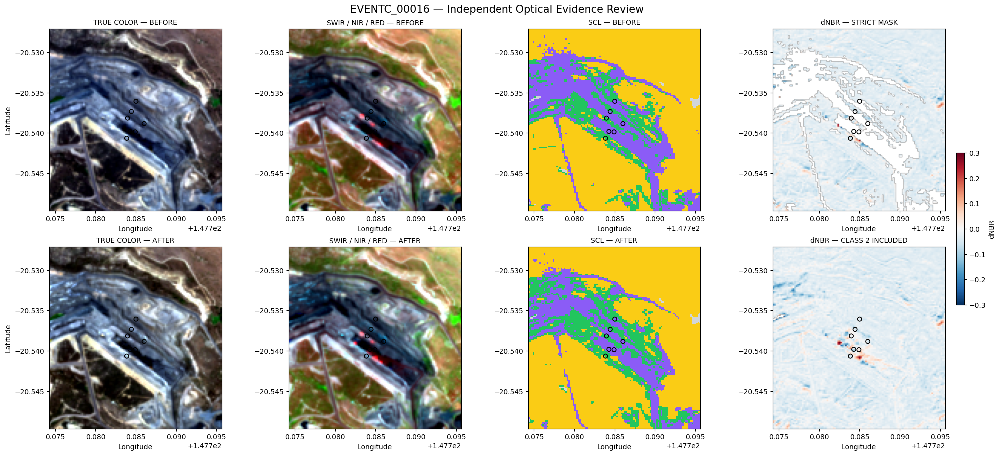

===== VISUAL REVIEW =====
Purple SCL = Class 2 / dark features
Yellow SCL = Class 5 / not vegetated
Green SCL = Class 7 / unclassified
Black circles = FIRMS detection centers
No scientific validation label assigned.


In [44]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Reuse EVENTC_00016 imagery from previous cells
assert len(points) == 7

# ==========================================
# 1. Read RGB and SWIR imagery
# ==========================================

bands = ["B02", "B03", "B04", "B08", "B12"]

pre_bands = {
    b: read_band(pre_item, b) / 10000.0
    for b in bands
}

post_bands = {
    b: read_band(post_item, b) / 10000.0
    for b in bands
}

# ==========================================
# 2. Identical display stretch before/after
# ==========================================

def common_rgb(pre_keys, post_keys):
    pre_channels = []
    post_channels = []

    for key_a, key_b in zip(pre_keys, post_keys):

        a = pre_bands[key_a]
        b = post_bands[key_b]

        values = np.concatenate([
            a[np.isfinite(a)],
            b[np.isfinite(b)]
        ])

        low, high = np.percentile(values, [2, 98])

        if high <= low:
            high = low + 0.001

        pre_channels.append(
            np.clip((a - low) / (high - low), 0, 1)
        )

        post_channels.append(
            np.clip((b - low) / (high - low), 0, 1)
        )

    pre_rgb = np.stack(pre_channels, axis=-1)
    post_rgb = np.stack(post_channels, axis=-1)

    return (
        np.nan_to_num(pre_rgb, nan=0.0),
        np.nan_to_num(post_rgb, nan=0.0)
    )


true_pre, true_post = common_rgb(
    ["B04", "B03", "B02"],
    ["B04", "B03", "B02"]
)

false_pre, false_post = common_rgb(
    ["B12", "B08", "B04"],
    ["B12", "B08", "B04"]
)

# ==========================================
# 3. SCL categories for visual diagnosis
# ==========================================

def scl_categories(scl):
    return np.select(
        [
            scl == 2,
            scl == 5,
            scl == 7
        ],
        [1, 2, 3],
        default=0
    )

scl_cmap = ListedColormap([
    "#d1d5db",  # Other SCL
    "#8b5cf6",  # Class 2
    "#facc15",  # Class 5
    "#22c55e"   # Class 7
])

# ==========================================
# 4. Strict vs exploratory dNBR
# ==========================================

strict_dnbr = np.where(
    strict_both, change, np.nan
)

exploratory_dnbr = np.where(
    exploratory_both, change, np.nan
)

# ==========================================
# 5. Display all views
# ==========================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(20, 9),
    constrained_layout=True
)

extent = [west, east, south, north]

panels = [
    [
        true_pre,
        false_pre,
        scl_categories(scl_pre),
        strict_dnbr
    ],
    [
        true_post,
        false_post,
        scl_categories(scl_post),
        exploratory_dnbr
    ]
]

titles = [
    [
        "TRUE COLOR — BEFORE",
        "SWIR / NIR / RED — BEFORE",
        "SCL — BEFORE",
        "dNBR — STRICT MASK"
    ],
    [
        "TRUE COLOR — AFTER",
        "SWIR / NIR / RED — AFTER",
        "SCL — AFTER",
        "dNBR — CLASS 2 INCLUDED"
    ]
]

for r in range(2):
    for c in range(4):

        ax = axes[r, c]
        data = panels[r][c]

        if c == 2:
            ax.imshow(
                data,
                origin="upper",
                extent=extent,
                cmap=scl_cmap,
                vmin=-0.5,
                vmax=3.5,
                interpolation="nearest"
            )

        elif c == 3:
            im = ax.imshow(
                np.ma.masked_invalid(data),
                origin="upper",
                extent=extent,
                cmap="RdBu_r",
                vmin=-0.3,
                vmax=0.3
            )

        else:
            ax.imshow(
                data,
                origin="upper",
                extent=extent
            )

        # Original FIRMS detections
        ax.scatter(
            points["longitude"],
            points["latitude"],
            s=35,
            facecolors="none",
            edgecolors="black",
            linewidths=1.2
        )

        ax.set_title(titles[r][c], fontsize=10)
        ax.set_xlabel("Longitude")

        if c == 0:
            ax.set_ylabel("Latitude")

fig.colorbar(
    im,
    ax=axes[:, 3],
    fraction=0.035,
    pad=0.03,
    label="dNBR"
)

fig.suptitle(
    "EVENTC_00016 — Independent Optical Evidence Review",
    fontsize=15
)

plt.show()

print("===== VISUAL REVIEW =====")
print("Purple SCL = Class 2 / dark features")
print("Yellow SCL = Class 5 / not vegetated")
print("Green SCL = Class 7 / unclassified")
print("Black circles = FIRMS detection centers")
print("No scientific validation label assigned.")

##**Historical Thermal Recurrence Audit**

In [45]:
# =========================================
# 1. Site and source data
# =========================================

EVENT_ID = "AU2020_P3_EVENTC_00016"

site = reference_search_report.loc[
    reference_search_report["candidate_event_id"] == EVENT_ID
].iloc[0]

lat0 = float(site["latitude"])
lon0 = float(site["longitude"])

required = [
    "detection_id",
    "source_dataset",
    "latitude",
    "longitude",
    "acquisition_datetime_utc",
    "type"
]

optional = ["frp", "daynight"]

def select_columns(df):
    missing = set(required) - set(df.columns)
    assert not missing, f"Missing columns: {missing}"

    return df[
        required + [c for c in optional if c in df.columns]
    ].copy()

all_2020 = pd.concat(
    [
        select_columns(modis_ready),
        select_columns(viirs_unified)
    ],
    ignore_index=True,
    sort=False
)

assert len(all_2020) == 1833048
assert all_2020["detection_id"].is_unique

# =========================================
# 2. Haversine distance from the site
# =========================================

lat = np.radians(
    all_2020["latitude"].to_numpy(dtype=float)
)
lon = np.radians(
    all_2020["longitude"].to_numpy(dtype=float)
)

lat_ref = np.radians(lat0)
lon_ref = np.radians(lon0)

a = (
    np.sin((lat - lat_ref) / 2) ** 2
    + np.cos(lat_ref) * np.cos(lat)
    * np.sin((lon - lon_ref) / 2) ** 2
)

distances = (
    2 * 6371.0088
    * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Preserve a wider 2 km diagnostic neighborhood
site_2020 = all_2020.loc[
    distances <= 2.0
].copy()

site_2020["distance_km"] = distances[
    distances <= 2.0
]

site_2020["acquisition_datetime_utc"] = (
    pd.to_datetime(
        site_2020["acquisition_datetime_utc"],
        utc=True
    )
)

site_2020["month"] = (
    site_2020["acquisition_datetime_utc"]
    .dt.strftime("%Y-%m")
)

site_2020["utc_day"] = (
    site_2020["acquisition_datetime_utc"]
    .dt.date
)

site_2020["type_numeric"] = pd.to_numeric(
    site_2020["type"], errors="coerce"
)

# =========================================
# 3. Distance and monthly activity summary
# =========================================

print("===== SITE RECURRENCE SUMMARY =====")
print("Site:", EVENT_ID)
print("Coordinates:", lat0, lon0)
print("Detections within 2 km:", len(site_2020))

for radius in [0.25, 0.5, 1.0, 2.0]:
    subset = site_2020.loc[
        site_2020["distance_km"] <= radius
    ]

    print(
        f"Within {radius} km:",
        len(subset),
        "detections,",
        subset["utc_day"].nunique(),
        "distinct UTC days"
    )

within_1km = site_2020.loc[
    site_2020["distance_km"] <= 1.0
].copy()

print("\n===== MONTHLY DETECTION HISTORY (1 KM) =====")

monthly_history = (
    within_1km.groupby("month")
    .agg(
        detections=("detection_id", "size"),
        observed_days=("utc_day", "nunique"),
        satellites=("source_dataset", "nunique")
    )
    .reset_index()
)

display(monthly_history)

print("\n===== SENSOR AND TYPE DISTRIBUTION =====")

display(
    pd.crosstab(
        within_1km["source_dataset"],
        within_1km["type_numeric"],
        dropna=False
    )
)

if "daynight" in within_1km.columns:
    print("\n===== DAY / NIGHT =====")
    display(
        within_1km["daynight"].value_counts(
            dropna=False
        )
    )

print("\n===== VALIDATION =====")

assert site_2020["distance_km"].le(2.0 + 1e-9).all()
assert within_1km["distance_km"].le(1.0 + 1e-9).all()

print("Historical site recurrence audit passed!")
print("No original detections or event IDs changed.")

===== SITE RECURRENCE SUMMARY =====
Site: AU2020_P3_EVENTC_00016
Coordinates: -20.53869 147.78465
Detections within 2 km: 225
Within 0.25 km: 120 detections, 83 distinct UTC days
Within 0.5 km: 210 detections, 97 distinct UTC days
Within 1.0 km: 225 detections, 98 distinct UTC days
Within 2.0 km: 225 detections, 98 distinct UTC days

===== MONTHLY DETECTION HISTORY (1 KM) =====


,month,detections,observed_days,satellites
0,2020-01,5,2,3
1,2020-02,8,4,2
2,2020-03,3,3,2
3,2020-04,2,2,1
4,2020-07,1,1,1
5,2020-08,64,24,3
6,2020-09,47,20,3
7,2020-10,63,25,2
8,2020-11,27,12,3
9,2020-12,5,5,2



===== SENSOR AND TYPE DISTRIBUTION =====


type_numeric,0
source_dataset,
MODIS,6
VIIRS_JPSS1,112
VIIRS_SNPP,107



===== DAY / NIGHT =====


,count
daynight,
N,204
D,21



===== VALIDATION =====
Historical site recurrence audit passed!
No original detections or event IDs changed.


In [46]:
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

R = 6371.0088
RADIUS_KM = 1.0

assert len(all_2020) == 1833048
assert len(fire_event_candidates) == 39

# ==========================================
# 1. Build spatial index for 2020 detections
# ==========================================

all_coords = np.radians(
    all_2020[
        ["latitude", "longitude"]
    ].to_numpy(dtype=float)
)

event_coords = np.radians(
    fire_event_candidates[
        ["mean_detection_lat", "mean_detection_lon"]
    ].to_numpy(dtype=float)
)

assert np.isfinite(all_coords).all()
assert np.isfinite(event_coords).all()

tree = BallTree(
    all_coords,
    metric="haversine",
    leaf_size=64
)

indices = tree.query_radius(
    event_coords,
    r=RADIUS_KM / R
)

# ==========================================
# 2. Evaluate recurrence outside pilot dates
# ==========================================

pilot_start = pd.Timestamp(
    "2020-09-28", tz="UTC"
)
pilot_end = pd.Timestamp(
    "2020-10-01", tz="UTC"
)

rows = []

for event_id, matched_indices in zip(
    fire_event_candidates["candidate_event_id"],
    indices
):

    local = all_2020.iloc[matched_indices]

    times = pd.to_datetime(
        local["acquisition_datetime_utc"],
        utc=True
    )

    outside = (
        (times < pilot_start)
        | (times >= pilot_end)
    )

    outside_times = times[outside]

    nighttime_pct = np.nan

    if "daynight" in local.columns and len(local):
        nighttime_pct = (
            100
            * local["daynight"]
            .astype(str).str.upper().eq("N").mean()
        )

    rows.append({
        "candidate_event_id": event_id,
        "annual_detections_1km": len(local),
        "annual_observed_days_1km": (
            times.dt.normalize().nunique()
        ),
        "outside_pilot_detections": int(
            outside.sum()
        ),
        "outside_pilot_days": (
            outside_times.dt.normalize().nunique()
        ),
        "observed_months": (
            times.dt.strftime("%Y-%m").nunique()
        ),
        "nighttime_pct": nighttime_pct,
        "sources_observed": (
            local["source_dataset"].nunique()
        )
    })

annual_event_recurrence = pd.DataFrame(rows)

annual_event_recurrence[
    "outside_pilot_day_rank"
] = (
    annual_event_recurrence["outside_pilot_days"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# ==========================================
# 3. Reports
# ==========================================

print("===== ANNUAL RECURRENCE COMPARISON =====")

display(
    annual_event_recurrence.sort_values(
        [
            "outside_pilot_days",
            "outside_pilot_detections"
        ],
        ascending=False
    ).head(15).round(2)
)

print("\n===== FIVE SCIENTIFIC REVIEW CASES =====")

review_ids = [
    "AU2020_P3_EVENTC_00009",
    "AU2020_P3_EVENTC_00016",
    "AU2020_P3_EVENTC_00019",
    "AU2020_P3_EVENTC_00029",
    "AU2020_P3_EVENTC_00015"
]

display(
    annual_event_recurrence.loc[
        annual_event_recurrence[
            "candidate_event_id"
        ].isin(review_ids)
    ].sort_values(
        "outside_pilot_days",
        ascending=False
    ).round(2)
)

print("\n===== EVENTC_00016 RECURRENCE POSITION =====")

focus = annual_event_recurrence.loc[
    annual_event_recurrence[
        "candidate_event_id"
    ] == "AU2020_P3_EVENTC_00016"
]

display(focus.T)

print("\n===== OVERALL RECURRENCE DISTRIBUTION =====")

display(
    annual_event_recurrence[
        [
            "annual_observed_days_1km",
            "outside_pilot_days",
            "observed_months",
            "nighttime_pct"
        ]
    ].describe().round(2)
)

# ==========================================
# 4. Checks
# ==========================================

assert len(annual_event_recurrence) == 39

assert annual_event_recurrence[
    "candidate_event_id"
].is_unique

assert (
    annual_event_recurrence["outside_pilot_days"]
    <= annual_event_recurrence[
        "annual_observed_days_1km"
    ]
).all()

print("\nAnnual recurrence comparison passed!")
print("No event classifications were changed.")

===== ANNUAL RECURRENCE COMPARISON =====


,candidate_event_id,annual_detections_1km,annual_observed_days_1km,outside_pilot_detections,outside_pilot_days,observed_months,nighttime_pct,sources_observed,outside_pilot_day_rank
18,AU2020_P3_EVENTC_00019,235,113,227,110,6,100.00,2,1
15,AU2020_P3_EVENTC_00016,225,98,218,95,10,90.67,3,2
24,AU2020_P3_EVENTC_00025,31,14,25,12,4,3.23,3,3
30,AU2020_P3_EVENTC_00031,58,13,51,11,4,56.90,3,4
5,AU2020_P3_EVENTC_00006,40,14,35,11,4,0.00,3,4
33,AU2020_P3_EVENTC_00034,52,12,31,9,4,67.31,3,6
9,AU2020_P3_EVENTC_00010,78,11,49,8,3,58.97,3,7
10,AU2020_P3_EVENTC_00011,50,11,42,8,3,54.00,3,7
0,AU2020_P3_EVENTC_00001,38,11,31,8,3,39.47,3,7
35,AU2020_P3_EVENTC_00036,37,11,26,8,2,64.86,3,7



===== FIVE SCIENTIFIC REVIEW CASES =====


,candidate_event_id,annual_detections_1km,annual_observed_days_1km,outside_pilot_detections,outside_pilot_days,observed_months,nighttime_pct,sources_observed,outside_pilot_day_rank
18,AU2020_P3_EVENTC_00019,235,113,227,110,6,100.00,2,1
15,AU2020_P3_EVENTC_00016,225,98,218,95,10,90.67,3,2
28,AU2020_P3_EVENTC_00029,60,8,20,5,2,78.33,3,17
8,AU2020_P3_EVENTC_00009,24,3,0,0,1,0.00,3,34
14,AU2020_P3_EVENTC_00015,20,3,0,0,1,10.00,2,34



===== EVENTC_00016 RECURRENCE POSITION =====


,15
candidate_event_id,AU2020_P3_EVENTC_00016
annual_detections_1km,225
annual_observed_days_1km,98
outside_pilot_detections,218
outside_pilot_days,95
observed_months,10
nighttime_pct,90.666667
sources_observed,3
outside_pilot_day_rank,2



===== OVERALL RECURRENCE DISTRIBUTION =====


,annual_observed_days_1km,outside_pilot_days,observed_months,nighttime_pct
count,39.00,39.00,39.00,39.00
mean,11.92,9.51,2.56,41.79
std,22.38,22.23,1.68,37.10
min,2.00,0.00,1.00,0.00
25%,3.50,1.50,1.00,0.00
50%,7.00,5.00,2.00,43.10
75%,10.50,7.50,3.00,67.52
max,113.00,110.00,10.00,100.00



Annual recurrence comparison passed!
No event classifications were changed.


Reading Sentinel-2 before image...
Reading Sentinel-2 after image...


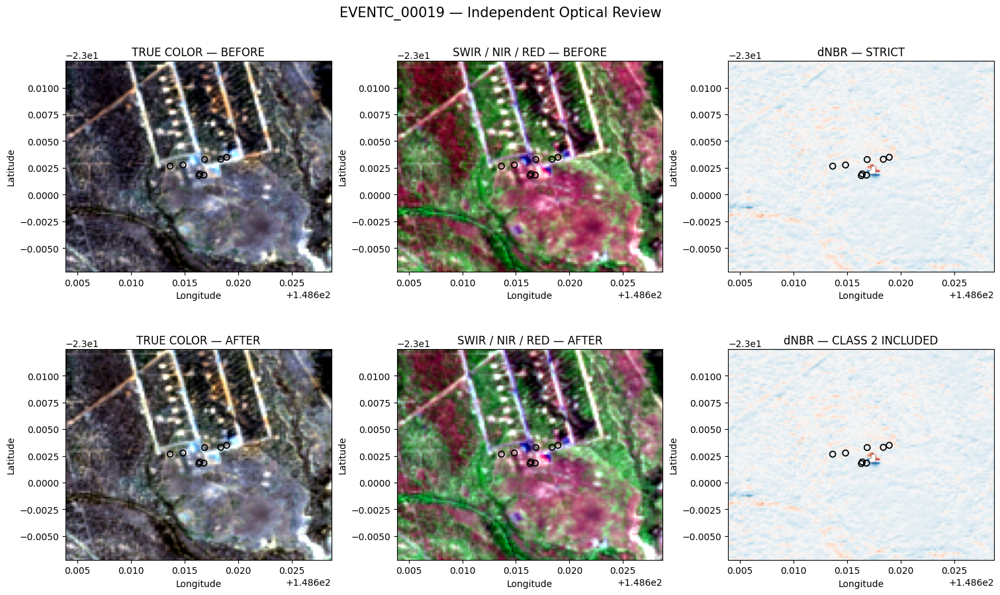


===== EVENTC_00019 IMAGE REVIEW =====
Before: 2020-09-27 00:20:59.024000+00:00
After: 2020-10-02 00:21:01.024000+00:00
Strict valid coverage (%): 99.93
Exploratory valid coverage (%): 99.93
Median exploratory dNBR: -0.0186
Scientific classification: NOT ASSIGNED


In [47]:
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.transform import from_bounds

EVENT_ID = "AU2020_P3_EVENTC_00019"

# 1. Get the selected Sentinel-2 scenes
selection = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == EVENT_ID)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
]

assert set(selection["phase"]) == {"before", "after"}

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

collection = catalog.get_collection("sentinel-2-l2a")

pre_id = selection.loc[
    selection["phase"] == "before", "scene_id"
].iloc[0]

post_id = selection.loc[
    selection["phase"] == "after", "scene_id"
].iloc[0]

pre_scene = collection.get_item(pre_id)
post_scene = collection.get_item(post_id)

# 2. Define common 20 m approximate grid
site_points = event_detection_data.loc[
    event_detection_data["candidate_event_id"] == EVENT_ID
].copy()

assert len(site_points) == 8

lat0 = site_points["latitude"].mean()
pad_lat = 1.0 / 111.195
pad_lon = 1.0 / (111.195 * np.cos(np.radians(lat0)))

west = site_points["longitude"].min() - pad_lon
east = site_points["longitude"].max() + pad_lon
south = site_points["latitude"].min() - pad_lat
north = site_points["latitude"].max() + pad_lat

width = int(np.ceil(
    (east - west) * 111195 * np.cos(np.radians(lat0)) / 20
))
height = int(np.ceil((north - south) * 111195 / 20))

target_transform = from_bounds(
    west, south, east, north, width, height
)

def read_scene_band(item, band):
    categorical = (band == "SCL")

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
    ):
        with rasterio.open(item.assets[band].href) as src:
            with WarpedVRT(
                src,
                crs="EPSG:4326",
                transform=target_transform,
                width=width,
                height=height,
                resampling=(
                    Resampling.nearest
                    if categorical else Resampling.bilinear
                )
            ) as vrt:
                data = vrt.read(1, masked=True)

    return data.astype("float32").filled(np.nan)

def load_scene(item):
    baseline = float(
        str(item.properties["s2:processing_baseline"])
        .replace("N", "")
    )

    # Reflectance offset depends on processing baseline
    offset = -1000.0 if baseline >= 4.0 else 0.0

    result = {}

    for band in ["B02", "B03", "B04", "B08", "B12"]:
        dn = read_scene_band(item, band)
        result[band] = np.where(
            dn > 0,
            (dn + offset) / 10000.0,
            np.nan
        )

    result["SCL"] = read_scene_band(item, "SCL")
    return result

print("Reading Sentinel-2 before image...")
pre = load_scene(pre_scene)

print("Reading Sentinel-2 after image...")
post = load_scene(post_scene)

# 3. NBR / dNBR
def nbr(scene):
    nir = scene["B08"]
    swir = scene["B12"]
    denominator = nir + swir

    return np.where(
        np.isfinite(denominator)
        & (denominator > 0.01),
        (nir - swir) / denominator,
        np.nan
    )

nbr_before = nbr(pre)
nbr_after = nbr(post)

change = nbr_before - nbr_after

strict = (
    np.isin(pre["SCL"], [4, 5, 7])
    & np.isin(post["SCL"], [4, 5, 7])
)

exploratory = (
    np.isin(pre["SCL"], [2, 4, 5, 7])
    & np.isin(post["SCL"], [2, 4, 5, 7])
)

# 4. Shared color stretch
def make_rgb(keys):
    raw_a = np.stack([pre[k] for k in keys], axis=-1)
    raw_b = np.stack([post[k] for k in keys], axis=-1)

    a = raw_a.copy()
    b = raw_b.copy()

    for channel in range(3):
        vals = np.concatenate([
            a[..., channel][np.isfinite(a[..., channel])],
            b[..., channel][np.isfinite(b[..., channel])]
        ])

        lo, hi = np.percentile(vals, [2, 98])
        hi = max(hi, lo + 1e-6)

        a[..., channel] = np.clip(
            (a[..., channel] - lo) / (hi - lo), 0, 1
        )
        b[..., channel] = np.clip(
            (b[..., channel] - lo) / (hi - lo), 0, 1
        )

    return np.nan_to_num(a), np.nan_to_num(b)

true_before, true_after = make_rgb(
    ["B04", "B03", "B02"]
)
false_before, false_after = make_rgb(
    ["B12", "B08", "B04"]
)

# 5. Visualization
fig, axes = plt.subplots(
    2, 3, figsize=(15, 9),
    constrained_layout=True
)

extent = [west, east, south, north]

panels = [
    (true_before, "TRUE COLOR — BEFORE", None),
    (false_before, "SWIR / NIR / RED — BEFORE", None),
    (np.where(strict, change, np.nan), "dNBR — STRICT", "RdBu_r"),
    (true_after, "TRUE COLOR — AFTER", None),
    (false_after, "SWIR / NIR / RED — AFTER", None),
    (np.where(exploratory, change, np.nan),
     "dNBR — CLASS 2 INCLUDED", "RdBu_r")
]

for ax, (data, title, cmap) in zip(axes.flat, panels):

    if cmap is None:
        ax.imshow(data, extent=extent, origin="upper")
    else:
        ax.imshow(
            np.ma.masked_invalid(data),
            extent=extent,
            origin="upper",
            cmap=cmap,
            vmin=-0.3,
            vmax=0.3
        )

    ax.scatter(
        site_points["longitude"],
        site_points["latitude"],
        s=40,
        facecolors="none",
        edgecolors="black",
        linewidths=1.3
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.suptitle(
    "EVENTC_00019 — Independent Optical Review",
    fontsize=15
)

plt.show()

# 6. Summary
print("\n===== EVENTC_00019 IMAGE REVIEW =====")

print("Before:", pre_scene.datetime)
print("After:", post_scene.datetime)

print(
    "Strict valid coverage (%):",
    round(100 * np.mean(strict & np.isfinite(change)), 2)
)

print(
    "Exploratory valid coverage (%):",
    round(100 * np.mean(exploratory & np.isfinite(change)), 2)
)

values = change[exploratory & np.isfinite(change)]

print(
    "Median exploratory dNBR:",
    round(float(np.median(values)), 4)
    if len(values) else "Not available"
)

print("Scientific classification: NOT ASSIGNED")

In [48]:
# ==========================================
# 1. Record reviewed evidence
# ==========================================

reviews = pd.DataFrame([
    {
        "candidate_event_id": "AU2020_P3_EVENTC_00016",
        "land_use_flag": "possible_anthropogenic",
        "visual_observation": "mining_like_terrain",
        "new_burn_evidence": "no_clear_optical_signature",
        "optical_quality_note": (
            "Strict mask excludes 5 of 7 FIRMS centers; "
            "Class-2 sensitivity review completed"
        ),
        "thermal_cause": "unresolved",
        "validation_status": "inconclusive"
    },
    {
        "candidate_event_id": "AU2020_P3_EVENTC_00019",
        "land_use_flag": "possible_anthropogenic",
        "visual_observation": "engineered_landscape_pattern",
        "new_burn_evidence": "no_clear_optical_signature",
        "optical_quality_note": (
            "Strict and exploratory valid coverage "
            "approximately 99.93 percent"
        ),
        "thermal_cause": "unresolved",
        "validation_status": "inconclusive"
    }
])

# ==========================================
# 2. Attach historical recurrence
# ==========================================

historical = annual_event_recurrence[
    [
        "candidate_event_id",
        "outside_pilot_days",
        "annual_observed_days_1km",
        "nighttime_pct"
    ]
]

validation_evidence_log = reviews.merge(
    historical,
    on="candidate_event_id",
    validate="one_to_one"
)

# ==========================================
# 3. Attach exact satellite scene references
# ==========================================

scenes = reference_scene_shortlist.loc[
    (
        reference_scene_shortlist["collection"]
        == "sentinel-2-l2a"
    )
    &
    reference_scene_shortlist[
        "candidate_event_id"
    ].isin(reviews["candidate_event_id"])
]

scene_ids = scenes.pivot(
    index="candidate_event_id",
    columns="phase",
    values="scene_id"
).rename(columns={
    "before": "before_scene_id",
    "after": "after_scene_id"
}).reset_index()

validation_evidence_log = validation_evidence_log.merge(
    scene_ids,
    on="candidate_event_id",
    validate="one_to_one"
)

validation_evidence_log["review_method"] = (
    "manual_optical_plus_historical_recurrence"
)

# ==========================================
# 4. Check scientific integrity
# ==========================================

assert len(validation_evidence_log) == 2
assert validation_evidence_log[
    "candidate_event_id"
].is_unique

assert validation_evidence_log[
    ["before_scene_id", "after_scene_id"]
].notna().all().all()

assert validation_evidence_log[
    "validation_status"
].eq("inconclusive").all()

print("===== VALIDATION EVIDENCE LOG =====")

display(validation_evidence_log.T)

print("\n===== REVIEW STATUS =====")

print("Cases recorded:", len(validation_evidence_log))
print("Confirmed vegetation fires: 0")
print("Confirmed industrial thermal sources: 0")
print("Cases requiring additional evidence: 2")

print("\nEvidence log created successfully.")
print("Original event candidates remain unchanged.")

===== VALIDATION EVIDENCE LOG =====


,0,1
candidate_event_id,AU2020_P3_EVENTC_00016,AU2020_P3_EVENTC_00019
land_use_flag,possible_anthropogenic,possible_anthropogenic
visual_observation,mining_like_terrain,engineered_landscape_pattern
new_burn_evidence,no_clear_optical_signature,no_clear_optical_signature
optical_quality_note,Strict mask excludes 5 of 7 FIRMS centers; Cla...,Strict and exploratory valid coverage approxim...
thermal_cause,unresolved,unresolved
validation_status,inconclusive,inconclusive
outside_pilot_days,95,110
annual_observed_days_1km,98,113
nighttime_pct,90.666667,100.0



===== REVIEW STATUS =====
Cases recorded: 2
Confirmed vegetation fires: 0
Confirmed industrial thermal sources: 0
Cases requiring additional evidence: 2

Evidence log created successfully.
Original event candidates remain unchanged.


Reading before image...
Reading after image...

===== EVENTC_00009 IMAGE QUALITY =====
Before: 2020-09-25 01:17:29.024000+00:00
After: 2020-10-05 01:17:29.024000+00:00
FIRMS detections: 26
Strict valid centers: 7 / 26
Exploratory valid centers: 8 / 26
Strict coverage near FIRMS (%): 25.38
Exploratory coverage near FIRMS (%): 27.84
Before cloud/shadow near FIRMS (%): 27.43
Before Class 2 near FIRMS (%): 7.21
After cloud/shadow near FIRMS (%): 68.12
After Class 2 near FIRMS (%): 1.92

===== EVENTC_00009 SPECTRAL CHANGE =====
Median dNBR: 0.0234
95th percentile: 0.1549


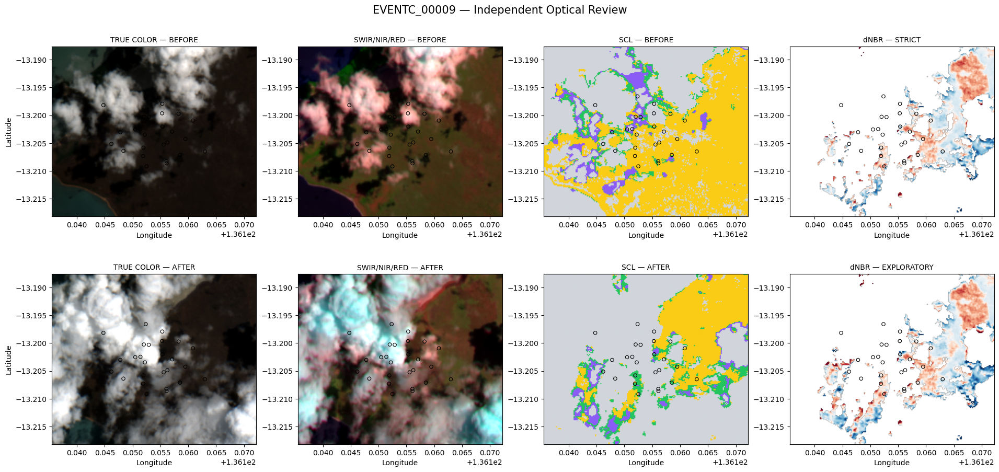


Optical review calculations completed.
Scientific validation label remains UNASSIGNED.


In [49]:
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.transform import from_bounds, rowcol
from matplotlib.colors import ListedColormap

EVENT_ID = "AU2020_P3_EVENTC_00009"

# ==========================================
# 1. Select independent satellite scenes
# ==========================================

selected = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == EVENT_ID)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
].copy()

assert len(selected) == 2
assert set(selected["phase"]) == {"before", "after"}

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

collection = catalog.get_collection("sentinel-2-l2a")

pre_scene = collection.get_item(
    selected.loc[selected["phase"] == "before", "scene_id"].iloc[0]
)

post_scene = collection.get_item(
    selected.loc[selected["phase"] == "after", "scene_id"].iloc[0]
)

# ==========================================
# 2. Common geographic grid
# ==========================================

points_09 = event_detection_data.loc[
    event_detection_data["candidate_event_id"] == EVENT_ID
].copy()

assert len(points_09) == 26

lat0 = points_09["latitude"].mean()
lat_pad = 1 / 111.195
lon_pad = 1 / (111.195 * np.cos(np.radians(lat0)))

west = points_09["longitude"].min() - lon_pad
east = points_09["longitude"].max() + lon_pad
south = points_09["latitude"].min() - lat_pad
north = points_09["latitude"].max() + lat_pad

width = int(np.ceil(
    (east - west) * 111195 * np.cos(np.radians(lat0)) / 20
))
height = int(np.ceil((north - south) * 111195 / 20))

transform = from_bounds(
    west, south, east, north, width, height
)

def read_asset(item, band):
    categorical = band == "SCL"

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
    ):
        with rasterio.open(item.assets[band].href) as src:
            with WarpedVRT(
                src,
                crs="EPSG:4326",
                transform=transform,
                width=width,
                height=height,
                resampling=(
                    Resampling.nearest if categorical
                    else Resampling.bilinear
                )
            ) as vrt:
                data = vrt.read(1, masked=True)

    return data.astype("float32").filled(np.nan)

def load_image(item):
    baseline = float(
        str(item.properties["s2:processing_baseline"])
        .replace("N", "")
    )
    offset = -1000 if baseline >= 4 else 0

    result = {}
    for band in ["B02", "B03", "B04", "B08", "B12"]:
        dn = read_asset(item, band)
        result[band] = np.where(
            dn > 0,
            (dn + offset) / 10000.0,
            np.nan
        )

    result["SCL"] = read_asset(item, "SCL")
    return result

print("Reading before image...")
pre = load_image(pre_scene)

print("Reading after image...")
post = load_image(post_scene)

# ==========================================
# 3. NBR and quality masks
# ==========================================

def calculate_nbr(scene):
    nir = scene["B08"]
    swir = scene["B12"]
    denom = nir + swir

    with np.errstate(divide="ignore", invalid="ignore"):
        result = (nir - swir) / denom

    return np.where(
        np.isfinite(result) & (denom > 0.01),
        result,
        np.nan
    )

nbr_pre = calculate_nbr(pre)
nbr_post = calculate_nbr(post)
dnbr = nbr_pre - nbr_post

strict = (
    np.isin(pre["SCL"], [4, 5, 7])
    & np.isin(post["SCL"], [4, 5, 7])
    & np.isfinite(dnbr)
)

exploratory = (
    np.isin(pre["SCL"], [2, 4, 5, 7])
    & np.isin(post["SCL"], [2, 4, 5, 7])
    & np.isfinite(dnbr)
)

# ==========================================
# 4. Quality specifically near FIRMS
# ==========================================

rr, cc = np.indices((height, width))

grid_lon = transform.c + (cc + 0.5) * transform.a
grid_lat = transform.f + (rr + 0.5) * transform.e

near_firms = np.zeros((height, width), dtype=bool)

for p in points_09.itertuples(index=False):
    dx = (
        (grid_lon - p.longitude)
        * 111.195
        * np.cos(np.radians(p.latitude))
    )
    dy = (grid_lat - p.latitude) * 111.195

    near_firms |= np.hypot(dx, dy) <= 0.25

center_rows = [
    rowcol(transform, p.longitude, p.latitude)
    for p in points_09.itertuples(index=False)
]

strict_centers = sum(
    bool(strict[r, c]) for r, c in center_rows
)
exploratory_centers = sum(
    bool(exploratory[r, c]) for r, c in center_rows
)

def coverage(mask, area):
    return round(
        100 * mask[area].mean(), 2
    )

print("\n===== EVENTC_00009 IMAGE QUALITY =====")
print("Before:", pre_scene.datetime)
print("After:", post_scene.datetime)
print("FIRMS detections:", len(points_09))
print("Strict valid centers:", strict_centers, "/ 26")
print(
    "Exploratory valid centers:",
    exploratory_centers, "/ 26"
)

print(
    "Strict coverage near FIRMS (%):",
    coverage(strict, near_firms)
)
print(
    "Exploratory coverage near FIRMS (%):",
    coverage(exploratory, near_firms)
)

for name, scene in [("Before", pre), ("After", post)]:
    print(
        f"{name} cloud/shadow near FIRMS (%):",
        round(
            100 * np.isin(
                scene["SCL"][near_firms], [3, 8, 9, 10]
            ).mean(), 2
        )
    )
    print(
        f"{name} Class 2 near FIRMS (%):",
        round(
            100 * np.mean(
                scene["SCL"][near_firms] == 2
            ), 2
        )
    )

values = dnbr[exploratory & near_firms]

print("\n===== EVENTC_00009 SPECTRAL CHANGE =====")

if len(values):
    print("Median dNBR:", round(float(np.median(values)), 4))
    print("95th percentile:", round(float(np.percentile(values, 95)), 4))
else:
    print("No valid neighborhood pixels.")

# ==========================================
# 5. Consistent RGB visualization
# ==========================================

def shared_rgb(keys):
    a = np.stack([pre[k] for k in keys], axis=-1)
    b = np.stack([post[k] for k in keys], axis=-1)

    for channel in range(3):
        values = np.concatenate([
            a[..., channel][np.isfinite(a[..., channel])],
            b[..., channel][np.isfinite(b[..., channel])]
        ])

        lo, hi = np.percentile(values, [2, 98])
        hi = max(hi, lo + 1e-6)

        a[..., channel] = np.clip(
            (a[..., channel] - lo) / (hi - lo), 0, 1
        )
        b[..., channel] = np.clip(
            (b[..., channel] - lo) / (hi - lo), 0, 1
        )

    return np.nan_to_num(a), np.nan_to_num(b)

true_pre, true_post = shared_rgb(
    ["B04", "B03", "B02"]
)

false_pre, false_post = shared_rgb(
    ["B12", "B08", "B04"]
)

scl_cmap = ListedColormap([
    "#d1d5db",
    "#8b5cf6",
    "#facc15",
    "#22c55e"
])

def scl_display(data):
    return np.select(
        [data == 2, data == 5, data == 7],
        [1, 2, 3],
        default=0
    )

fig, axes = plt.subplots(
    2, 4, figsize=(19, 9),
    constrained_layout=True
)

panels = [
    [true_pre, false_pre, scl_display(pre["SCL"]),
     np.where(strict, dnbr, np.nan)],
    [true_post, false_post, scl_display(post["SCL"]),
     np.where(exploratory, dnbr, np.nan)]
]

titles = [
    ["TRUE COLOR — BEFORE", "SWIR/NIR/RED — BEFORE",
     "SCL — BEFORE", "dNBR — STRICT"],
    ["TRUE COLOR — AFTER", "SWIR/NIR/RED — AFTER",
     "SCL — AFTER", "dNBR — EXPLORATORY"]
]

extent = [west, east, south, north]

for r in range(2):
    for c in range(4):
        ax = axes[r, c]
        data = panels[r][c]

        if c == 2:
            ax.imshow(
                data, extent=extent, origin="upper",
                cmap=scl_cmap, vmin=-0.5, vmax=3.5
            )
        elif c == 3:
            ax.imshow(
                np.ma.masked_invalid(data),
                extent=extent, origin="upper",
                cmap="RdBu_r", vmin=-0.3, vmax=0.3
            )
        else:
            ax.imshow(data, extent=extent, origin="upper")

        ax.scatter(
            points_09["longitude"],
            points_09["latitude"],
            s=22,
            facecolors="none",
            edgecolors="black",
            linewidths=0.8
        )

        ax.set_title(titles[r][c], fontsize=10)
        ax.set_xlabel("Longitude")
        if c == 0:
            ax.set_ylabel("Latitude")

fig.suptitle(
    "EVENTC_00009 — Independent Optical Review",
    fontsize=15
)

plt.show()

print("\nOptical review calculations completed.")
print("Scientific validation label remains UNASSIGNED.")

===== VALIDATION LOG STATUS =====
    candidate_event_id validation_status
AU2020_P3_EVENTC_00016      inconclusive
AU2020_P3_EVENTC_00019      inconclusive
AU2020_P3_EVENTC_00009      inconclusive

Reading EVENTC_00029 imagery...

===== EVENTC_00029 IMAGE QUALITY =====
Before: 2020-09-24 00:11:09.024000+00:00
After: 2020-10-04 00:11:09.024000+00:00
Existing event detections: 9
Excluded cluster detections: 39
Strict coverage near points (%): 72.44
Exploratory coverage near points (%): 100.0
Before cloud/shadow near points (%): 0.0
After cloud/shadow near points (%): 0.0

===== EVENTC_00029 SPECTRAL CHANGE =====
Median dNBR: 0.0863
95th percentile dNBR: 0.226


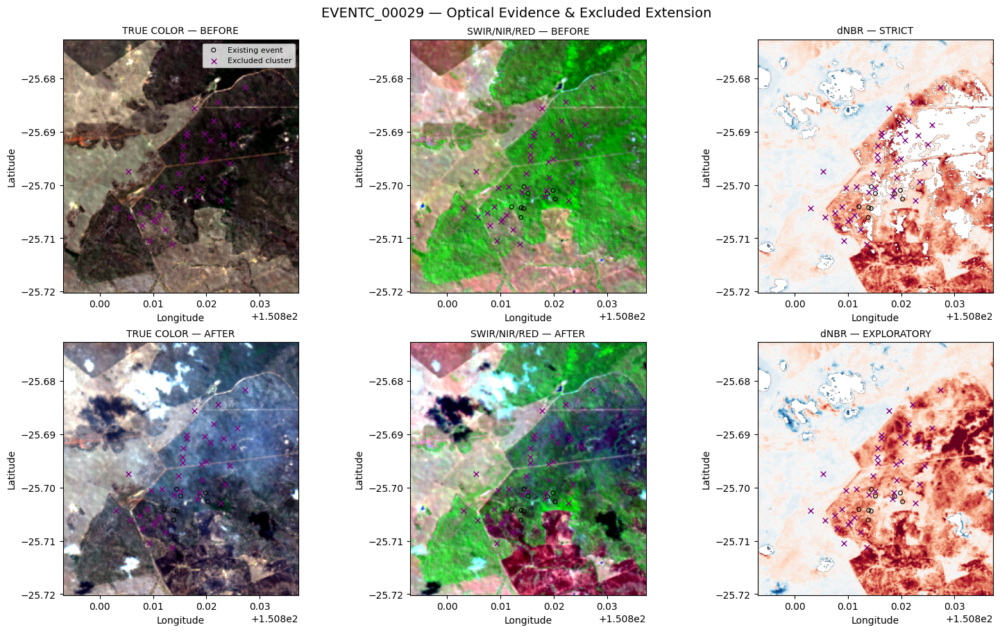


EVENTC_00029 optical review ready.
No event membership or validation label changed.


In [50]:
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.transform import from_bounds
from matplotlib.colors import ListedColormap

# ==========================================
# 1. Record EVENTC_00009 as inconclusive
# ==========================================

case09 = "AU2020_P3_EVENTC_00009"

history09 = annual_event_recurrence.set_index(
    "candidate_event_id"
).loc[case09]

scene09 = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == case09)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
].set_index("phase")

new_review = pd.DataFrame([{
    "candidate_event_id": case09,
    "land_use_flag": "not_determined",
    "visual_observation": "cloud_obscured_landscape",
    "new_burn_evidence": "unassessable_cloud_affected",
    "optical_quality_note": (
        "Only 8/26 FIRMS centers valid under exploratory mask; "
        "27.84% valid coverage near FIRMS"
    ),
    "thermal_cause": "unresolved",
    "validation_status": "inconclusive",
    "outside_pilot_days": int(history09["outside_pilot_days"]),
    "annual_observed_days_1km": int(
        history09["annual_observed_days_1km"]
    ),
    "nighttime_pct": float(history09["nighttime_pct"]),
    "before_scene_id": scene09.loc["before", "scene_id"],
    "after_scene_id": scene09.loc["after", "scene_id"],
    "review_method": "manual_optical_quality_review"
}])

validation_evidence_log = pd.concat(
    [
        validation_evidence_log.loc[
            validation_evidence_log["candidate_event_id"] != case09
        ],
        new_review
    ],
    ignore_index=True
)

assert len(validation_evidence_log) == 3
assert validation_evidence_log["candidate_event_id"].is_unique

print("===== VALIDATION LOG STATUS =====")
print(validation_evidence_log[
    ["candidate_event_id", "validation_status"]
].to_string(index=False))

# ==========================================
# 2. Load EVENTC_00029 and excluded cluster
# ==========================================

EVENT_ID = "AU2020_P3_EVENTC_00029"
EXTRA_CLUSTER = "AU20200928_OCV2_00269"

review_points = all_points.loc[
    (all_points["candidate_event_id"] == EVENT_ID)
    | (all_points["observation_cluster_id"] == EXTRA_CLUSTER)
].copy()

review_points["point_group"] = np.where(
    review_points["observation_cluster_id"] == EXTRA_CLUSTER,
    "excluded_extension",
    "existing_event"
)

assert (review_points["point_group"] == "existing_event").any()
assert (review_points["point_group"] == "excluded_extension").any()

selection = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == EVENT_ID)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
].set_index("phase")

assert {"before", "after"}.issubset(selection.index)

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

collection = catalog.get_collection("sentinel-2-l2a")

before_item = collection.get_item(
    selection.loc["before", "scene_id"]
)
after_item = collection.get_item(
    selection.loc["after", "scene_id"]
)

# ==========================================
# 3. Small, shared geographic grid
# ==========================================

lat0 = review_points["latitude"].mean()

lat_padding = 1.0 / 111.195
lon_padding = 1.0 / (
    111.195 * np.cos(np.radians(lat0))
)

west = review_points["longitude"].min() - lon_padding
east = review_points["longitude"].max() + lon_padding
south = review_points["latitude"].min() - lat_padding
north = review_points["latitude"].max() + lat_padding

width = max(1, int(np.ceil(
    (east - west) * 111195
    * np.cos(np.radians(lat0)) / 20
)))

height = max(1, int(np.ceil(
    (north - south) * 111195 / 20
)))

target_transform = from_bounds(
    west, south, east, north, width, height
)

def read_band_local(item, band):
    method = (
        Resampling.nearest if band == "SCL"
        else Resampling.bilinear
    )

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"
    ):
        with rasterio.open(item.assets[band].href) as src:
            with WarpedVRT(
                src,
                crs="EPSG:4326",
                transform=target_transform,
                width=width,
                height=height,
                resampling=method
            ) as vrt:
                arr = vrt.read(1, masked=True)

    return arr.astype("float32").filled(np.nan)

def load_local(item):
    baseline = float(
        str(item.properties["s2:processing_baseline"])
        .replace("N", "")
    )
    offset = -1000 if baseline >= 4 else 0

    bands = {}

    for name in ["B02", "B03", "B04", "B08", "B12"]:
        dn = read_band_local(item, name)
        bands[name] = np.where(
            dn > 0, (dn + offset) / 10000, np.nan
        )

    bands["SCL"] = read_band_local(item, "SCL")
    return bands

print("\nReading EVENTC_00029 imagery...")
pre29 = load_local(before_item)
post29 = load_local(after_item)

# ==========================================
# 4. Calculate NBR / dNBR and image quality
# ==========================================

def nbr29(scene):
    nir = scene["B08"]
    swir = scene["B12"]
    den = nir + swir

    with np.errstate(invalid="ignore", divide="ignore"):
        val = (nir - swir) / den

    return np.where(
        np.isfinite(val) & (den > 0.01),
        val,
        np.nan
    )

change29 = nbr29(pre29) - nbr29(post29)

strict29 = (
    np.isin(pre29["SCL"], [4, 5, 7])
    & np.isin(post29["SCL"], [4, 5, 7])
    & np.isfinite(change29)
)

explore29 = (
    np.isin(pre29["SCL"], [2, 4, 5, 7])
    & np.isin(post29["SCL"], [2, 4, 5, 7])
    & np.isfinite(change29)
)

rr, cc = np.indices((height, width))

glon = target_transform.c + (cc + 0.5) * target_transform.a
glat = target_transform.f + (rr + 0.5) * target_transform.e

near29 = np.zeros((height, width), dtype=bool)

for p in review_points.itertuples(index=False):
    dx = (glon - p.longitude) * 111.195 * np.cos(
        np.radians(p.latitude)
    )
    dy = (glat - p.latitude) * 111.195
    near29 |= np.hypot(dx, dy) <= 0.25

print("\n===== EVENTC_00029 IMAGE QUALITY =====")
print("Before:", before_item.datetime)
print("After:", after_item.datetime)
print("Existing event detections:",
      int((review_points["point_group"] == "existing_event").sum()))
print("Excluded cluster detections:",
      int((review_points["point_group"] == "excluded_extension").sum()))
print("Strict coverage near points (%):",
      round(100 * strict29[near29].mean(), 2))
print("Exploratory coverage near points (%):",
      round(100 * explore29[near29].mean(), 2))

for name, scene in [("Before", pre29), ("After", post29)]:
    print(
        f"{name} cloud/shadow near points (%):",
        round(
            100 * np.isin(
                scene["SCL"][near29],
                [3, 8, 9, 10]
            ).mean(), 2
        )
    )

vals = change29[explore29 & near29]

print("\n===== EVENTC_00029 SPECTRAL CHANGE =====")
if len(vals):
    print("Median dNBR:", round(float(np.median(vals)), 4))
    print("95th percentile dNBR:",
          round(float(np.percentile(vals, 95)), 4))
else:
    print("No shared valid pixels near review points.")

# ==========================================
# 5. Shared display stretch
# ==========================================

def rgb_pair(keys):
    a = np.stack([pre29[k] for k in keys], axis=-1)
    b = np.stack([post29[k] for k in keys], axis=-1)

    for ch in range(3):
        combined = np.concatenate([
            a[..., ch][np.isfinite(a[..., ch])],
            b[..., ch][np.isfinite(b[..., ch])]
        ])

        low, high = np.percentile(combined, [2, 98])
        high = max(high, low + 1e-6)

        a[..., ch] = np.clip(
            (a[..., ch] - low) / (high - low), 0, 1
        )
        b[..., ch] = np.clip(
            (b[..., ch] - low) / (high - low), 0, 1
        )

    return np.nan_to_num(a), np.nan_to_num(b)

rgb_before, rgb_after = rgb_pair(
    ["B04", "B03", "B02"]
)

swir_before, swir_after = rgb_pair(
    ["B12", "B08", "B04"]
)

# ==========================================
# 6. Visual review
# ==========================================

fig, axes = plt.subplots(
    2, 3, figsize=(15, 9),
    constrained_layout=True
)

panels = [
    (rgb_before, "TRUE COLOR — BEFORE", None),
    (swir_before, "SWIR/NIR/RED — BEFORE", None),
    (np.where(strict29, change29, np.nan),
     "dNBR — STRICT", "RdBu_r"),

    (rgb_after, "TRUE COLOR — AFTER", None),
    (swir_after, "SWIR/NIR/RED — AFTER", None),
    (np.where(explore29, change29, np.nan),
     "dNBR — EXPLORATORY", "RdBu_r")
]

for ax, (data, title, cmap) in zip(axes.flat, panels):
    if cmap is None:
        ax.imshow(data, extent=[west, east, south, north])
    else:
        ax.imshow(
            np.ma.masked_invalid(data),
            extent=[west, east, south, north],
            cmap=cmap,
            vmin=-0.3, vmax=0.3
        )

    existing = review_points.loc[
        review_points["point_group"] == "existing_event"
    ]
    extra = review_points.loc[
        review_points["point_group"] == "excluded_extension"
    ]

    ax.scatter(
        existing["longitude"], existing["latitude"],
        s=18, facecolors="none",
        edgecolors="black", linewidths=0.8,
        label="Existing event"
    )

    ax.scatter(
        extra["longitude"], extra["latitude"],
        marker="x", s=30, c="purple",
        linewidths=1.0, label="Excluded cluster"
    )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    "EVENTC_00029 — Optical Evidence & Excluded Extension",
    fontsize=14
)

plt.show()

print("\nEVENTC_00029 optical review ready.")
print("No event membership or validation label changed.")

##**Separate Burn Evidence Audit**

In [51]:
from rasterio.transform import rowcol

# Reuse the EVENTC_00029 outputs
assert len(review_points) == 48
assert change29.shape == strict29.shape == explore29.shape

RADIUS_KM = 0.25

# ==========================================
# 1. Build separate spatial neighborhoods
# ==========================================

rows_grid, cols_grid = np.indices(change29.shape)

pixel_lon = (
    target_transform.c
    + (cols_grid + 0.5) * target_transform.a
)

pixel_lat = (
    target_transform.f
    + (rows_grid + 0.5) * target_transform.e
)

def neighborhood_for_group(group_name):

    selected_points = review_points.loc[
        review_points["point_group"] == group_name
    ]

    zone = np.zeros(change29.shape, dtype=bool)

    for p in selected_points.itertuples(index=False):

        dx = (
            (pixel_lon - p.longitude)
            * 111.195
            * np.cos(np.radians(p.latitude))
        )

        dy = (
            pixel_lat - p.latitude
        ) * 111.195

        zone |= np.hypot(dx, dy) <= RADIUS_KM

    return zone

event_zone = neighborhood_for_group("existing_event")
extension_zone = neighborhood_for_group(
    "excluded_extension"
)

# Areas that do not overlap
event_only = event_zone & ~extension_zone
extension_only = extension_zone & ~event_zone
overlap_zone = event_zone & extension_zone

all_near = event_zone | extension_zone

print("===== NEIGHBORHOOD OVERLAP =====")
print("Event neighborhood pixels:", int(event_zone.sum()))
print("Extension neighborhood pixels:",
      int(extension_zone.sum()))
print("Shared pixels:", int(overlap_zone.sum()))
print("Total unique neighborhood pixels:",
      int(all_near.sum()))

print(
    "Overlap as % of union:",
    round(100 * overlap_zone.sum() / all_near.sum(), 2)
)

# ==========================================
# 2. Quality and dNBR by separate zone
# ==========================================

zones = {
    "existing_event_only": event_only,
    "excluded_extension_only": extension_only,
    "shared_overlap": overlap_zone,
    "existing_event_all": event_zone,
    "excluded_extension_all": extension_zone
}

def zone_stats(name, zone):

    n = int(zone.sum())

    result = {
        "zone": name,
        "total_pixels": n,
        "strict_coverage_pct": np.nan,
        "exploratory_coverage_pct": np.nan,
        "median_dNBR": np.nan,
        "p95_dNBR": np.nan,
        "pct_dNBR_above_0_10": np.nan
    }

    if n == 0:
        return result

    result["strict_coverage_pct"] = round(
        100 * strict29[zone].mean(), 2
    )

    result["exploratory_coverage_pct"] = round(
        100 * explore29[zone].mean(), 2
    )

    values = change29[
        zone & explore29 & np.isfinite(change29)
    ]

    if len(values):
        result["median_dNBR"] = round(
            float(np.median(values)), 4
        )

        result["p95_dNBR"] = round(
            float(np.percentile(values, 95)), 4
        )

        # Descriptive screening threshold only
        result["pct_dNBR_above_0_10"] = round(
            100 * np.mean(values > 0.10), 2
        )

    return result

separate_burn_report = pd.DataFrame([
    zone_stats(name, zone)
    for name, zone in zones.items()
])

print("\n===== SEPARATE BURN EVIDENCE =====")
display(separate_burn_report)

# ==========================================
# 3. Quality exactly at FIRMS centers
# ==========================================

point_rows = []

for group_name, group in review_points.groupby(
    "point_group"
):

    strict_count = 0
    explore_count = 0

    for p in group.itertuples(index=False):

        r, c = rowcol(
            target_transform,
            float(p.longitude),
            float(p.latitude)
        )

        assert (
            0 <= r < change29.shape[0]
            and 0 <= c < change29.shape[1]
        )

        strict_count += bool(strict29[r, c])
        explore_count += bool(explore29[r, c])

    point_rows.append({
        "group": group_name,
        "detections": len(group),
        "strict_valid_centers": strict_count,
        "exploratory_valid_centers": explore_count
    })

print("\n===== GROUP CENTER QUALITY =====")
display(pd.DataFrame(point_rows))

# ==========================================
# 4. Checks
# ==========================================

assert np.all(
    ~(event_only & extension_only)
)

assert int(
    event_only.sum()
    + extension_only.sum()
    + overlap_zone.sum()
) == int(all_near.sum())

assert separate_burn_report[
    "total_pixels"
].ge(0).all()

print("\nSeparate burn evidence audit passed!")
print("No event classification or membership changed.")

===== NEIGHBORHOOD OVERLAP =====
Event neighborhood pixels: 2285
Extension neighborhood pixels: 11765
Shared pixels: 1849
Total unique neighborhood pixels: 12201
Overlap as % of union: 15.15

===== SEPARATE BURN EVIDENCE =====


,zone,total_pixels,strict_coverage_pct,exploratory_coverage_pct,median_dNBR,p95_dNBR,pct_dNBR_above_0_10
0,existing_event_only,436,72.48,100.0,0.0855,0.1836,39.22
1,excluded_extension_only,9916,73.58,100.0,0.0847,0.2330,42.18
2,shared_overlap,1849,66.36,100.0,0.0929,0.1934,45.11
3,existing_event_all,2285,67.53,100.0,0.0916,0.1895,43.98
4,excluded_extension_all,11765,72.44,100.0,0.0864,0.2271,42.64



===== GROUP CENTER QUALITY =====


,group,detections,strict_valid_centers,exploratory_valid_centers
0,excluded_extension,39,23,39
1,existing_event,9,7,9



Separate burn evidence audit passed!
No event classification or membership changed.


In [52]:

import pandas as pd
import numpy as np

EVENT_ID = "AU2020_P3_EVENTC_00029"
EXTRA_ID = "AU20200928_OCV2_00269"

assert EVENT_ID not in set(
    validation_evidence_log["candidate_event_id"]
)

# 1. Get evidence already calculated
history = annual_event_recurrence.set_index(
    "candidate_event_id"
).loc[EVENT_ID]

scenes = reference_scene_shortlist.loc[
    (reference_scene_shortlist["candidate_event_id"] == EVENT_ID)
    & (reference_scene_shortlist["collection"] == "sentinel-2-l2a")
].set_index("phase")

zones = separate_burn_report.set_index("zone")

existing = zones.loc["existing_event_only"]
excluded = zones.loc["excluded_extension_only"]

# 2. Add fourth scientific review
case_review = pd.DataFrame([{
    "candidate_event_id": EVENT_ID,
    "land_use_flag": "vegetation_visible_context",
    "visual_observation": "spatially_structured_optical_change",
    "new_burn_evidence": "possible_burn_signature_unconfirmed",
    "optical_quality_note": (
        "Strict valid coverage ~72% in separate zones; "
        "exploratory mask includes SCL class 2; "
        "spectral change requires independent confirmation"
    ),
    "thermal_cause": "unresolved",
    "validation_status": "inconclusive",
    "outside_pilot_days": int(history["outside_pilot_days"]),
    "annual_observed_days_1km": int(
        history["annual_observed_days_1km"]
    ),
    "nighttime_pct": float(history["nighttime_pct"]),
    "before_scene_id": scenes.loc["before", "scene_id"],
    "after_scene_id": scenes.loc["after", "scene_id"],
    "review_method": "manual_optical_separate_zone_review"
}])

validation_evidence_log = pd.concat(
    [validation_evidence_log, case_review],
    ignore_index=True
)

# 3. Record the excluded extension independently
link = extension_audit.loc[
    (extension_audit["candidate_event_id"] == EVENT_ID)
    & (extension_audit["neighbor_cluster_id"] == EXTRA_ID)
]

assert len(link) == 1
link = link.iloc[0]

extension_review_log = pd.DataFrame([{
    "candidate_event_id": EVENT_ID,
    "excluded_cluster_id": EXTRA_ID,
    "link_class": link["link_class"],
    "eligible_detection_pairs": int(
        link["eligible_detection_pairs"]
    ),
    "existing_only_median_dNBR": float(
        existing["median_dNBR"]
    ),
    "excluded_only_median_dNBR": float(
        excluded["median_dNBR"]
    ),
    "existing_only_strict_coverage_pct": float(
        existing["strict_coverage_pct"]
    ),
    "excluded_only_strict_coverage_pct": float(
        excluded["strict_coverage_pct"]
    ),
    "overlap_union_pct": round(
        100 * overlap_zone.sum() / all_near.sum(), 2
    ),
    "extension_decision": "unresolved_not_merged",
    "reason": (
        "Optical change in both zones does not "
        "establish a single continuous fire event"
    )
}])

# 4. Integrity checks
assert len(validation_evidence_log) == 4

assert validation_evidence_log[
    "candidate_event_id"
].is_unique

assert validation_evidence_log[
    "validation_status"
].eq("inconclusive").all()

assert len(fire_event_candidates) == 39
assert len(extension_audit) == 15

# 5. Save intermediate scientific evidence
validation_evidence_log.to_csv(
    "validation_evidence_log_pilot_v1.csv",
    index=False
)

extension_review_log.to_csv(
    "extension_review_log_pilot_v1.csv",
    index=False
)

print("===== SCIENTIFIC REVIEW PROGRESS =====")
print("Cases recorded:", len(validation_evidence_log))
print("Total review cases:", len(validation_manifest))
print("Confirmed vegetation fires: 0")
print("Current event candidates:", len(fire_event_candidates))

print("\n===== EVIDENCE LOG =====")
display(
    validation_evidence_log[
        [
            "candidate_event_id",
            "new_burn_evidence",
            "validation_status"
        ]
    ]
)

print("\n===== EXTENSION REVIEW =====")
display(extension_review_log.T)

print("\nScientific evidence checkpoint saved.")
print("No original event memberships changed.")


===== SCIENTIFIC REVIEW PROGRESS =====
Cases recorded: 4
Total review cases: 84
Confirmed vegetation fires: 0
Current event candidates: 39

===== EVIDENCE LOG =====


,candidate_event_id,new_burn_evidence,validation_status
0,AU2020_P3_EVENTC_00016,no_clear_optical_signature,inconclusive
1,AU2020_P3_EVENTC_00019,no_clear_optical_signature,inconclusive
2,AU2020_P3_EVENTC_00009,unassessable_cloud_affected,inconclusive
3,AU2020_P3_EVENTC_00029,possible_burn_signature_unconfirmed,inconclusive



===== EXTENSION REVIEW =====


,0
candidate_event_id,AU2020_P3_EVENTC_00029
excluded_cluster_id,AU20200928_OCV2_00269
link_class,split_candidate
eligible_detection_pairs,74
existing_only_median_dNBR,0.0855
excluded_only_median_dNBR,0.0847
existing_only_strict_coverage_pct,72.48
excluded_only_strict_coverage_pct,73.58
overlap_union_pct,15.15
extension_decision,unresolved_not_merged



Scientific evidence checkpoint saved.
No original event memberships changed.


## **Official Fire Scar Verification**

In [53]:
%pip -q install requests shapely

import requests
import json
import numpy as np
import pandas as pd

from shapely.geometry import shape, Point

# ==========================================
# 1. Official Queensland 2020 fire scars
# ==========================================

SERVICE_URL = (
    "https://spatial-gis.information.qld.gov.au/"
    "arcgis/rest/services/Environment/"
    "FireScarMapping/FeatureServer/34/query"
)

EVENT_ID = "AU2020_P3_EVENTC_00029"
EXTRA_CLUSTER = "AU20200928_OCV2_00269"

review = all_points.loc[
    (all_points["candidate_event_id"] == EVENT_ID)
    | (
        all_points["observation_cluster_id"]
        == EXTRA_CLUSTER
    )
].copy()

review["group"] = np.where(
    review["observation_cluster_id"] == EXTRA_CLUSTER,
    "excluded_extension",
    "existing_event"
)

assert len(review) == 48
assert review["detection_id"].is_unique

# ==========================================
# 2. Small search area around both groups
# ==========================================

lat0 = review["latitude"].mean()

pad_lat = 0.30 / 111.195
pad_lon = 0.30 / (
    111.195 * np.cos(np.radians(lat0))
)

bbox = {
    "xmin": float(review["longitude"].min() - pad_lon),
    "ymin": float(review["latitude"].min() - pad_lat),
    "xmax": float(review["longitude"].max() + pad_lon),
    "ymax": float(review["latitude"].max() + pad_lat),
    "spatialReference": {"wkid": 4326}
}

params = {
    "where": "1=1",
    "geometry": json.dumps(bbox),
    "geometryType": "esriGeometryEnvelope",
    "spatialRel": "esriSpatialRelIntersects",
    "inSR": 4326,
    "outSR": 4326,
    "outFields": (
        "objectid,month,month_desc,"
        "year,fire_id,area_ha"
    ),
    "returnGeometry": "true",
    "f": "geojson"
}

print("Querying Queensland official fire scars...")

response = requests.get(
    SERVICE_URL,
    params=params,
    timeout=90
)

response.raise_for_status()
data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

if "features" not in data:
    raise RuntimeError(
        "Unexpected response from fire scar service"
    )

if data.get("exceededTransferLimit", False):
    raise RuntimeError(
        "Reference response truncated; pagination required"
    )

# ==========================================
# 3. Prepare mapped fire scar geometries
# ==========================================

scars = []

for feature in data["features"]:

    if not feature.get("geometry"):
        continue

    geom = shape(feature["geometry"])

    if geom.is_empty:
        continue

    if not geom.is_valid:
        geom = geom.buffer(0)

    props = feature.get("properties", {})

    scars.append({
        "objectid": props.get("objectid"),
        "fire_id": props.get("fire_id"),
        "month": props.get("month"),
        "area_ha": props.get("area_ha"),
        "geometry": geom
    })

print("\n===== OFFICIAL REFERENCE SEARCH =====")
print("Fire scar polygons intersecting AOI:", len(scars))

# ==========================================
# 4. Match detection centers to polygons
# ==========================================

point_rows = []

for p in review.itertuples(index=False):

    location = Point(
        float(p.longitude),
        float(p.latitude)
    )

    matches = [
        s for s in scars
        if s["geometry"].covers(location)
    ]

    months = {
        s["month"] for s in matches
        if s["month"] is not None
    }

    point_rows.append({
        "detection_id": p.detection_id,
        "group": p.group,
        "matched_2020_scar": len(matches) > 0,
        "matched_sep_oct_scar": bool(
            months.intersection({9, 10})
        ),
        "matched_polygon_count": len(matches)
    })

official_point_matches = pd.DataFrame(point_rows)

print("\n===== OFFICIAL POINT MATCH SUMMARY =====")

display(
    official_point_matches.groupby("group").agg(
        Detections=("detection_id", "size"),
        Matched_2020_Scar=(
            "matched_2020_scar", "sum"
        ),
        Matched_Sep_Oct_Scar=(
            "matched_sep_oct_scar", "sum"
        )
    )
)

# ==========================================
# 5. Compare scar polygons across both groups
# ==========================================

scar_rows = []

for scar in scars:

    geom = scar["geometry"]

    counts = {}

    for name, group in review.groupby("group"):

        counts[name] = sum(
            geom.covers(
                Point(float(p.longitude),
                      float(p.latitude))
            )
            for p in group.itertuples(index=False)
        )

    if sum(counts.values()) == 0:
        continue

    scar_rows.append({
        "official_objectid": scar["objectid"],
        "official_fire_id": scar["fire_id"],
        "first_detected_month": scar["month"],
        "official_polygon_area_ha": scar["area_ha"],
        "existing_event_points": counts.get(
            "existing_event", 0
        ),
        "excluded_extension_points": counts.get(
            "excluded_extension", 0
        ),
        "both_groups_intersect_same_polygon": (
            counts.get("existing_event", 0) > 0
            and counts.get("excluded_extension", 0) > 0
        )
    })

official_scar_matches = pd.DataFrame(
    scar_rows,
    columns=[
        "official_objectid",
        "official_fire_id",
        "first_detected_month",
        "official_polygon_area_ha",
        "existing_event_points",
        "excluded_extension_points",
        "both_groups_intersect_same_polygon"
    ]
)

print("\n===== OFFICIAL FIRE SCAR MATCHES =====")

if len(official_scar_matches):
    display(official_scar_matches)
else:
    print("No detection centers fall inside returned polygons.")

print("\n===== REFERENCE CHECK =====")
print("Detection centers checked:", len(official_point_matches))

print(
    "Both groups intersect at least one same polygon:",
    bool(
        official_scar_matches[
            "both_groups_intersect_same_polygon"
        ].any()
    )
)

assert len(official_point_matches) == 48
assert official_point_matches["detection_id"].is_unique

print("\nOfficial reference lookup completed.")
print("No event memberships or validation labels changed.")

Querying Queensland official fire scars...

===== OFFICIAL REFERENCE SEARCH =====
Fire scar polygons intersecting AOI: 9

===== OFFICIAL POINT MATCH SUMMARY =====


,Detections,Matched_2020_Scar,Matched_Sep_Oct_Scar
group,,,
excluded_extension,39,31,31
existing_event,9,7,7



===== OFFICIAL FIRE SCAR MATCHES =====


,official_objectid,official_fire_id,first_detected_month,official_polygon_area_ha,existing_event_points,excluded_extension_points,both_groups_intersect_same_polygon
0,238799,32861102020,10,1797.5,7,31,True



===== REFERENCE CHECK =====
Detection centers checked: 48
Both groups intersect at least one same polygon: True

Official reference lookup completed.
No event memberships or validation labels changed.


##**Validation Report v1**

In [54]:
EVENT_ID = "AU2020_P3_EVENTC_00029"
EXTRA_ID = "AU20200928_OCV2_00269"

SOURCE_URL = (
    "https://spatial-gis.information.qld.gov.au/"
    "arcgis/rest/services/Environment/"
    "FireScarMapping/FeatureServer/34"
)

# ==========================================
# 1. Validate official reference results
# ==========================================

assert len(official_point_matches) == 48
assert official_point_matches["detection_id"].is_unique

shared = official_scar_matches.loc[
    official_scar_matches[
        "both_groups_intersect_same_polygon"
    ]
].copy()

assert len(shared) == 1

scar = shared.iloc[0]

assert int(scar["existing_event_points"]) == 7
assert int(scar["excluded_extension_points"]) == 31

# ==========================================
# 2. Build official reference evidence
# ==========================================

group_stats = (
    official_point_matches.groupby("group")
    .agg(
        detections=("detection_id", "size"),
        matched_2020=("matched_2020_scar", "sum"),
        matched_sep_oct=(
            "matched_sep_oct_scar", "sum"
        )
    )
    .reset_index()
)

group_stats["matched_pct"] = (
    100
    * group_stats["matched_2020"]
    / group_stats["detections"]
).round(2)

group_stats["candidate_event_id"] = EVENT_ID
group_stats["official_fire_id"] = str(
    scar["official_fire_id"]
)
group_stats["official_objectid"] = str(
    scar["official_objectid"]
)
group_stats["first_detected_month"] = int(
    scar["first_detected_month"]
)
group_stats["reference_source"] = SOURCE_URL

official_reference_evidence = group_stats.copy()

# ==========================================
# 3. Add reference evidence to validation log
# ==========================================

mask = (
    validation_evidence_log["candidate_event_id"]
    == EVENT_ID
)

assert mask.sum() == 1

validation_evidence_log.loc[
    mask, "official_reference_result"
] = "official_burn_scar_overlap_supported"

validation_evidence_log.loc[
    mask, "official_fire_id"
] = str(scar["official_fire_id"])

validation_evidence_log.loc[
    mask, "official_first_detected_month"
] = int(scar["first_detected_month"])

validation_evidence_log.loc[
    mask, "reference_source"
] = SOURCE_URL

# Separate the scientific questions
validation_evidence_log.loc[
    mask, "event_identity_evidence"
] = "shared_scar_not_proof_of_same_fire"

# Do not mark the event as confirmed
validation_evidence_log.loc[
    mask, "validation_status"
] = "inconclusive"

# ==========================================
# 4. Update the extension review separately
# ==========================================

extension_review_log[
    "official_reference_result"
] = "both_groups_overlap_same_2020_scar"

extension_review_log[
    "official_fire_id"
] = str(scar["official_fire_id"])

extension_review_log[
    "extension_decision"
] = "unresolved_not_merged"

# ==========================================
# 5. Build report for all 39 event candidates
# ==========================================

validation_report_v1 = fire_event_candidates[
    [
        "candidate_event_id",
        "detection_count",
        "observed_days",
        "tracking_rule"
    ]
].copy()

review_fields = validation_evidence_log[
    [
        "candidate_event_id",
        "new_burn_evidence",
        "validation_status"
    ]
].rename(columns={
    "validation_status": "scientific_review_status"
})

validation_report_v1 = validation_report_v1.merge(
    review_fields,
    on="candidate_event_id",
    how="left",
    validate="one_to_one"
)

validation_report_v1[
    "scientific_review_status"
] = validation_report_v1[
    "scientific_review_status"
].fillna("not_reviewed")

validation_report_v1["model_version"] = (
    "moderate_v1"
)

validation_report_v1["ground_truth_confirmed"] = False

# ==========================================
# 6. Integrity checks and save
# ==========================================

assert len(validation_report_v1) == 39
assert len(validation_evidence_log) == 4

assert (
    validation_report_v1[
        "scientific_review_status"
    ].value_counts().to_dict()
    == {"not_reviewed": 35, "inconclusive": 4}
)

assert extension_review_log[
    "extension_decision"
].eq("unresolved_not_merged").all()

validation_evidence_log.to_csv(
    "validation_evidence_log_pilot_v2.csv",
    index=False
)

official_reference_evidence.to_csv(
    "official_fire_scar_evidence_pilot_v1.csv",
    index=False
)

extension_review_log.to_csv(
    "extension_review_log_pilot_v2.csv",
    index=False
)

validation_report_v1.to_csv(
    "validation_report_pilot_v1.csv",
    index=False
)

print("===== OFFICIAL REFERENCE EVIDENCE =====")
display(
    official_reference_evidence[
        [
            "group",
            "detections",
            "matched_2020",
            "matched_pct",
            "official_fire_id",
            "first_detected_month"
        ]
    ]
)

print("\n===== VALIDATION REPORT V1 =====")
display(
    validation_report_v1[
        "scientific_review_status"
    ].value_counts()
)

print("\n===== SCIENTIFIC CHECKPOINT =====")
print("Candidate events:", len(validation_report_v1))
print("Reviewed cases:", len(validation_evidence_log))
print("Official shared scar:", scar["official_fire_id"])
print("Confirmed fire identities: 0")
print("Extension status: unresolved_not_merged")
print("Original memberships unchanged.")
print("\nValidation report v1 saved!")

===== OFFICIAL REFERENCE EVIDENCE =====


,group,detections,matched_2020,matched_pct,official_fire_id,first_detected_month
0,excluded_extension,39,31,79.49,32861102020,10
1,existing_event,9,7,77.78,32861102020,10



===== VALIDATION REPORT V1 =====


,count
scientific_review_status,
not_reviewed,35
inconclusive,4



===== SCIENTIFIC CHECKPOINT =====
Candidate events: 39
Reviewed cases: 4
Official shared scar: 32861102020
Confirmed fire identities: 0
Extension status: unresolved_not_merged
Original memberships unchanged.

Validation report v1 saved!


# **Scalable Pipeline Engineering**

## **Validate full-year input**

In [58]:
all_2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1833048 entries, 0 to 1833047
Data columns (total 8 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   detection_id              object             
 1   source_dataset            object             
 2   latitude                  float64            
 3   longitude                 float64            
 4   acquisition_datetime_utc  datetime64[ns, UTC]
 5   type                      int64              
 6   frp                       float64            
 7   daynight                  object             
dtypes: datetime64[ns, UTC](1), float64(3), int64(1), object(3)
memory usage: 111.9+ MB


In [56]:
# ==========================================
# 1. Validate full-year input
# ==========================================

required = [
    "detection_id",
    "source_dataset",
    "latitude",
    "longitude",
    "acquisition_datetime_utc",
    "type"
]

missing = set(required) - set(all_2020.columns)
assert not missing, f"Missing columns: {missing}"

assert len(all_2020) == 1833048

timestamps = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True,
    errors="coerce"
)

latitude = pd.to_numeric(
    all_2020["latitude"], errors="coerce"
)

longitude = pd.to_numeric(
    all_2020["longitude"], errors="coerce"
)

types = pd.to_numeric(
    all_2020["type"], errors="coerce"
)

# ==========================================
# 2. Data quality report
# ==========================================

year_start = pd.Timestamp("2020-01-01", tz="UTC")
year_end = pd.Timestamp("2021-01-01", tz="UTC")

quality = {
    "total_detections": len(all_2020),
    "unique_detection_ids":
        all_2020["detection_id"].nunique(),
    "duplicate_detection_ids":
        int(all_2020["detection_id"].duplicated().sum()),
    "missing_timestamps":
        int(timestamps.isna().sum()),
    "outside_2020":
        int(((timestamps < year_start)
             | (timestamps >= year_end)).sum()),
    "invalid_coordinates":
        int((~latitude.between(-90, 90)
             | ~longitude.between(-180, 180)).sum()),
    "missing_type":
        int(types.isna().sum())
}

print("===== FULL-YEAR DATA QUALITY =====")
display(
    pd.DataFrame(
        quality.items(),
        columns=["Metric", "Value"]
    )
)

# ==========================================
# 3. Source breakdown
# ==========================================

print("\n===== SATELLITE SOURCE COUNTS =====")

display(
    all_2020["source_dataset"]
    .value_counts()
    .rename_axis("source_dataset")
    .reset_index(name="detections")
)

print("\n===== SOURCE TYPE DISTRIBUTION =====")

source_types = pd.crosstab(
    all_2020["source_dataset"],
    types,
    dropna=False
)

display(source_types)

# ==========================================
# 4. Monthly detection workload
# ==========================================

months = timestamps.dt.strftime("%Y-%m")

monthly_workload = pd.crosstab(
    months,
    all_2020["source_dataset"]
)

monthly_workload["TOTAL"] = (
    monthly_workload.sum(axis=1)
)

print("\n===== MONTHLY WORKLOAD =====")
display(monthly_workload)

# ==========================================
# 5. Daily and rolling 7-day workload
# ==========================================

calendar_days = pd.date_range(
    "2020-01-01",
    "2020-12-31",
    freq="D",
    tz="UTC"
)

daily_workload = (
    timestamps.dt.floor("D")
    .value_counts()
    .reindex(calendar_days, fill_value=0)
    .sort_index()
)

weekly_totals = daily_workload.rolling(
    window=7,
    min_periods=7
).sum()

busiest_day = daily_workload.idxmax()
busiest_week_end = weekly_totals.idxmax()
busiest_week_start = (
    busiest_week_end - pd.Timedelta(days=6)
)

print("\n===== PROCESSING WORKLOAD =====")

print(
    "Average daily detections:",
    round(daily_workload.mean(), 1)
)

print(
    "Maximum daily detections:",
    int(daily_workload.max())
)

print(
    "Busiest UTC day:",
    busiest_day.strftime("%Y-%m-%d")
)

print(
    "Maximum 7-day detections:",
    int(weekly_totals.max())
)

print(
    "Busiest 7-day window:",
    busiest_week_start.strftime("%Y-%m-%d"),
    "to",
    busiest_week_end.strftime("%Y-%m-%d")
)

print("\n===== TOP 10 BUSIEST DAYS =====")

display(
    daily_workload.nlargest(10)
    .rename("detections")
    .reset_index(name="utc_date")
)

# ==========================================
# 6. Source geometry readiness
# ==========================================

print("\n===== SPATIAL MATCHING READINESS =====")

for name, df in [
    ("MODIS", modis_ready),
    ("VIIRS", viirs_unified)
]:
    print(
        name,
        "| scan:", "scan" in df.columns,
        "| track:", "track" in df.columns,
        "| UTC:", "acquisition_datetime_utc" in df.columns
    )

# ==========================================
# 7. Blocking integrity checks
# ==========================================

blocking_issues = {
    key: quality[key]
    for key in [
        "duplicate_detection_ids",
        "missing_timestamps",
        "outside_2020",
        "invalid_coordinates"
    ]
}

if any(blocking_issues.values()):
    print("\nWARNING: Resolve blocking data issues.")
    print(blocking_issues)
else:
    print("\nFull-year structural checks passed!")

print("No source detections were modified.")
print("No fire-event assignments were generated.")

===== FULL-YEAR DATA QUALITY =====


,Metric,Value
0,total_detections,1833048
1,unique_detection_ids,1833048
2,duplicate_detection_ids,0
3,missing_timestamps,0
4,outside_2020,0
5,invalid_coordinates,0
6,missing_type,0



===== SATELLITE SOURCE COUNTS =====


,source_dataset,detections
0,VIIRS_SNPP,847691
1,VIIRS_JPSS1,829833
2,MODIS,155524



===== SOURCE TYPE DISTRIBUTION =====


type,0,2,3
source_dataset,,,
MODIS,153717,1675,132
VIIRS_JPSS1,813874,14441,1518
VIIRS_SNPP,831814,14596,1281



===== MONTHLY WORKLOAD =====


source_dataset,MODIS,VIIRS_JPSS1,VIIRS_SNPP,TOTAL
acquisition_datetime_utc,,,,
2020-01,36994,191225,199080,427299
2020-02,6826,33947,34521,75294
2020-03,4046,23138,24275,51459
2020-04,7718,42366,41455,91539
2020-05,15859,77767,79270,172896
2020-06,13112,65958,65083,144153
2020-07,16993,84007,84978,185978
2020-08,6215,50061,50636,106912
2020-09,8035,43880,44557,96472



===== PROCESSING WORKLOAD =====
Average daily detections: 5008.3
Maximum daily detections: 81889
Busiest UTC day: 2020-01-04
Maximum 7-day detections: 255261
Busiest 7-day window: 2020-01-01 to 2020-01-07

===== TOP 10 BUSIEST DAYS =====


,index,utc_date
0,2020-01-04 00:00:00+00:00,81889
1,2020-01-02 00:00:00+00:00,47423
2,2020-01-01 00:00:00+00:00,46514
3,2020-01-03 00:00:00+00:00,36042
4,2020-01-13 00:00:00+00:00,22491
5,2020-02-01 00:00:00+00:00,20476
6,2020-01-31 00:00:00+00:00,18782
7,2020-01-07 00:00:00+00:00,17978
8,2020-01-12 00:00:00+00:00,17238
9,2020-01-14 00:00:00+00:00,16399



===== SPATIAL MATCHING READINESS =====
MODIS | scan: True | track: True | UTC: True
VIIRS | scan: True | track: True | UTC: True

Full-year structural checks passed!
No source detections were modified.
No fire-event assignments were generated.


## **Spatial-Temporal Density Stress Test**

In [59]:
# ==========================================
# 1. Settings
# ==========================================

TEST_DAYS = ["2020-09-29", "2020-01-04"]

GRID_DEGREES = 0.1
TIME_BIN_HOURS = 2

assert len(all_2020) == 1833048

timestamps = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

types = pd.to_numeric(
    all_2020["type"],
    errors="coerce"
)

summary_rows = []
daily_diagnostics = {}

# ==========================================
# 2. Audit each test day
# ==========================================

for day_str in TEST_DAYS:

    start = pd.Timestamp(day_str, tz="UTC")
    end = start + pd.Timedelta(days=1)

    mask = (
        (timestamps >= start)
        & (timestamps < end)
    )

    day = all_2020.loc[
        mask,
        [
            "detection_id",
            "latitude",
            "longitude",
            "source_dataset"
        ]
    ].copy()

    day["type_numeric"] = types.loc[mask].to_numpy()

    # Clustering pilot used type=0
    vegetation = day.loc[
        day["type_numeric"] == 0
    ].copy()

    times = timestamps.loc[mask]
    vegetation_times = times.loc[
        vegetation.index
    ]

    # Spatial diagnostic bins
    vegetation["lat_tile"] = np.floor(
        (vegetation["latitude"] + 90)
        / GRID_DEGREES
    ).astype("int32")

    vegetation["lon_tile"] = np.floor(
        (vegetation["longitude"] + 180)
        / GRID_DEGREES
    ).astype("int32")

    # 2-hour UTC bins: 0..11
    vegetation["time_bin"] = (
        vegetation_times.dt.hour
        // TIME_BIN_HOURS
    ).astype("int8").to_numpy()

    # --------------------------------------
    # Spatial workload
    # --------------------------------------

    spatial_sizes = (
        vegetation.groupby(
            ["lat_tile", "lon_tile"]
        )
        .size()
        .rename("detections")
        .reset_index()
    )

    # --------------------------------------
    # Spatial + temporal workload
    # --------------------------------------

    spacetime_sizes = (
        vegetation.groupby(
            ["lat_tile", "lon_tile", "time_bin"]
        )
        .size()
        .rename("detections")
        .reset_index()
    )

    max_spatial = int(
        spatial_sizes["detections"].max()
    )

    max_spacetime = int(
        spacetime_sizes["detections"].max()
    )

    # Memory for ONE NxN float64 matrix.
    # Does not include intermediate arrays.
    matrix_mib = (
        8 * max_spacetime**2 / (1024**2)
    )

    summary_rows.append({
        "Day": day_str,
        "All_Detections": len(day),
        "Type0_Detections": len(vegetation),
        "Spatial_Tiles": len(spatial_sizes),
        "SpaceTime_Bins": len(spacetime_sizes),
        "Max_Spatial_Tile": max_spatial,
        "Max_2h_SpaceTime_Bin": max_spacetime,
        "P95_2h_Bin": round(
            spacetime_sizes["detections"].quantile(
                0.95
            ), 1
        ),
        "Bins_Over_500": int(
            (
                spacetime_sizes["detections"] > 500
            ).sum()
        ),
        "Bins_Over_1000": int(
            (
                spacetime_sizes["detections"] > 1000
            ).sum()
        ),
        "Single_Matrix_MiB": round(
            matrix_mib, 2
        )
    })

    daily_diagnostics[day_str] = {
        "spatial": spatial_sizes,
        "spacetime": spacetime_sizes,
        "type0": vegetation
    }

    print(f"Analyzed {day_str}")

# ==========================================
# 3. Main comparison
# ==========================================

density_stress_report = pd.DataFrame(
    summary_rows
)

print("\n===== DENSITY STRESS COMPARISON =====")

display(density_stress_report)

# ==========================================
# 4. Busiest spatial tiles in January
# ==========================================

jan_spatial = daily_diagnostics[
    "2020-01-04"
]["spatial"].copy()

jan_spatial["lat_tile_south"] = (
    jan_spatial["lat_tile"] * GRID_DEGREES - 90
)

jan_spatial["lon_tile_west"] = (
    jan_spatial["lon_tile"] * GRID_DEGREES - 180
)

print("\n===== JANUARY BUSIEST SPATIAL TILES =====")

display(
    jan_spatial.sort_values(
        "detections",
        ascending=False
    )[
        [
            "lat_tile_south",
            "lon_tile_west",
            "detections"
        ]
    ].head(10).round(3)
)

# ==========================================
# 5. Busiest spatial-temporal bins
# ==========================================

jan_st = daily_diagnostics[
    "2020-01-04"
]["spacetime"].copy()

jan_st["UTC_Start_Hour"] = (
    jan_st["time_bin"] * TIME_BIN_HOURS
)

jan_st["lat_tile_south"] = (
    jan_st["lat_tile"] * GRID_DEGREES - 90
)

jan_st["lon_tile_west"] = (
    jan_st["lon_tile"] * GRID_DEGREES - 180
)

print("\n===== JANUARY BUSIEST 2H BINS =====")

display(
    jan_st.sort_values(
        "detections",
        ascending=False
    )[
        [
            "lat_tile_south",
            "lon_tile_west",
            "UTC_Start_Hour",
            "detections"
        ]
    ].head(10).round(3)
)

# ==========================================
# 6. Integrity checks
# ==========================================

sep = density_stress_report.loc[
    density_stress_report["Day"] == "2020-09-29"
].iloc[0]

jan = density_stress_report.loc[
    density_stress_report["Day"] == "2020-01-04"
].iloc[0]

assert sep["All_Detections"] == 3840
assert sep["Type0_Detections"] == 3751

assert jan["All_Detections"] == 81889

for day_str in TEST_DAYS:

    output = daily_diagnostics[day_str]

    assert (
        output["spacetime"]["detections"].sum()
        == len(output["type0"])
    )

    assert (
        output["spatial"]["detections"].sum()
        == len(output["type0"])
    )

print("\nDensity stress audit passed!")
print("No clustering or event assignments generated.")

Analyzed 2020-09-29
Analyzed 2020-01-04

===== DENSITY STRESS COMPARISON =====


,Day,All_Detections,Type0_Detections,Spatial_Tiles,SpaceTime_Bins,Max_Spatial_Tile,Max_2h_SpaceTime_Bin,P95_2h_Bin,Bins_Over_500,Bins_Over_1000,Single_Matrix_MiB
0,2020-09-29,3840,3751,338,589,233,171,26.0,0,0,0.22
1,2020-01-04,81889,81615,858,1970,1235,813,206.6,25,0,5.04



===== JANUARY BUSIEST SPATIAL TILES =====


,lat_tile_south,lon_tile_west,detections
89,-37.4,149.1,1235
66,-37.5,149.3,1075
152,-37.1,147.4,1016
31,-37.7,149.1,990
192,-36.8,147.9,961
408,-34.8,150.4,938
67,-37.5,149.4,900
358,-35.5,148.0,865
112,-37.3,149.3,757
93,-37.4,149.5,749



===== JANUARY BUSIEST 2H BINS =====


,lat_tile_south,lon_tile_west,UTC_Start_Hour,detections
228,-37.4,149.1,14,813
990,-34.8,150.4,14,803
471,-36.8,147.9,4,731
171,-37.5,149.3,14,702
884,-35.5,148.0,4,702
348,-37.2,149.3,14,697
998,-34.7,150.3,14,690
78,-37.7,149.1,14,678
379,-37.1,147.4,4,676
249,-37.4,149.8,14,618



Density stress audit passed!
No clustering or event assignments generated.


## **Boundary-Safe Candidate Graph Test**

In [60]:
import time

from sklearn.neighbors import BallTree

# ==========================================
# 1. Configuration
# ==========================================

TEST_DAYS = ["2020-09-29", "2020-01-04"]

EARTH_RADIUS_KM = 6371.0088
SEARCH_RADIUS_KM = 5.0
MAX_TIME_GAP_MIN = 120.0

TIME_BIN_MIN = 120
QUERY_BATCH_SIZE = 256

all_times = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

all_types = pd.to_numeric(
    all_2020["type"],
    errors="coerce"
)

# ==========================================
# 2. Memory-bounded candidate search
# ==========================================

def audit_day_candidates(day_string):

    start = pd.Timestamp(day_string, tz="UTC")
    end = start + pd.Timedelta(days=1)

    selection = (
        (all_times >= start)
        & (all_times < end)
        & all_types.eq(0)
    )

    df = all_2020.loc[
        selection,
        [
            "detection_id",
            "latitude",
            "longitude",
            "acquisition_datetime_utc"
        ]
    ].reset_index(drop=True)

    assert df["detection_id"].is_unique

    n = len(df)

    if n == 0:
        raise ValueError(f"No type-0 detections: {day_string}")

    coords = np.radians(
        df[["latitude", "longitude"]].to_numpy(
            dtype=np.float64
        )
    )

    minute_of_day = (
        pd.to_datetime(
            df["acquisition_datetime_utc"],
            utc=True
        ) - start
    ).dt.total_seconds().to_numpy() / 60.0

    time_bins = (
        minute_of_day // TIME_BIN_MIN
    ).astype(np.int8)

    assert np.all((time_bins >= 0) & (time_bins <= 11))

    degree = np.zeros(n, dtype=np.int64)

    total_candidate_pairs = 0
    bin_rows = []

    started = time.perf_counter()

    # ======================================
    # 3. Process every 2-hour core bin
    # ======================================

    for b in range(12):

        core_indices = np.flatnonzero(
            time_bins == b
        )

        if len(core_indices) == 0:
            continue

        # Includes previous/current/next bin.
        # Any pair <= 120 min apart must
        # fall within this temporal neighborhood.
        pool_indices = np.flatnonzero(
            np.abs(time_bins.astype(int) - b) <= 1
        )

        tree = BallTree(
            coords[pool_indices],
            metric="haversine",
            leaf_size=64
        )

        bin_candidate_pairs = 0

        # ==================================
        # 4. Query in small memory-safe batches
        # ==================================

        for offset in range(
            0, len(core_indices), QUERY_BATCH_SIZE
        ):

            batch_indices = core_indices[
                offset:offset + QUERY_BATCH_SIZE
            ]

            neighbors = tree.query_radius(
                coords[batch_indices],
                r=SEARCH_RADIUS_KM / EARTH_RADIUS_KM,
                return_distance=False
            )

            for i, local_neighbors in zip(
                batch_indices, neighbors
            ):

                j = pool_indices[local_neighbors]

                # Every unordered pair is counted
                # exactly once: i < j.
                j = j[j > i]

                if len(j) == 0:
                    continue

                # Exact time-gap filter.
                gaps = np.abs(
                    minute_of_day[j] - minute_of_day[i]
                )

                j = j[
                    gaps <= MAX_TIME_GAP_MIN + 1e-9
                ]

                pair_count = len(j)

                if pair_count == 0:
                    continue

                bin_candidate_pairs += pair_count

                # Count degrees without storing edges
                degree[i] += pair_count
                np.add.at(degree, j, 1)

        total_candidate_pairs += bin_candidate_pairs

        bin_rows.append({
            "day": day_string,
            "utc_start_hour": b * 2,
            "core_detections": len(core_indices),
            "core_plus_halo_detections": len(pool_indices),
            "unique_candidate_pairs": bin_candidate_pairs
        })

        if b in [3, 7, 11]:
            print(
                day_string,
                "| completed bin:",
                b + 1,
                "/ 12"
            )

    runtime_seconds = (
        time.perf_counter() - started
    )

    # ======================================
    # 5. Verify candidate graph accounting
    # ======================================

    assert degree.sum() == (
        2 * total_candidate_pairs
    )

    assert total_candidate_pairs <= (
        n * (n - 1) // 2
    )

    result = {
        "day": day_string,
        "type0_detections": n,
        "unique_candidate_pairs": total_candidate_pairs,
        "detections_with_neighbors": int(
            np.count_nonzero(degree)
        ),
        "isolated_detections": int(
            np.count_nonzero(degree == 0)
        ),
        "mean_candidate_degree": round(
            float(degree.mean()), 2
        ),
        "p95_candidate_degree": round(
            float(np.percentile(degree, 95)), 2
        ),
        "max_candidate_degree": int(degree.max()),
        "max_temporal_halo_size": max(
            row["core_plus_halo_detections"]
            for row in bin_rows
        ),
        "runtime_seconds": round(
            runtime_seconds, 2
        )
    }

    return result, pd.DataFrame(bin_rows)

# ==========================================
# 6. Run both test days
# ==========================================

daily_results = []
all_bin_results = []

for test_day in TEST_DAYS:

    print("\nProcessing:", test_day)

    report, bins = audit_day_candidates(
        test_day
    )

    daily_results.append(report)
    all_bin_results.append(bins)

candidate_stress_report = pd.DataFrame(
    daily_results
)

candidate_bin_report = pd.concat(
    all_bin_results,
    ignore_index=True
)

# ==========================================
# 7. Display engineering diagnostics
# ==========================================

print("\n===== CANDIDATE GRAPH STRESS REPORT =====")

display(candidate_stress_report)

print("\n===== HEAVIEST TEMPORAL BINS =====")

display(
    candidate_bin_report.sort_values(
        "unique_candidate_pairs",
        ascending=False
    ).head(10)
)

print("\n===== CANDIDATE GRAPH INTEGRITY =====")

assert (
    candidate_bin_report.groupby("day")[
        "unique_candidate_pairs"
    ].sum().sort_index().to_numpy()
    ==
    candidate_stress_report.sort_values("day")[
        "unique_candidate_pairs"
    ].to_numpy()
).all()

assert (
    candidate_stress_report.set_index("day").loc[
        "2020-09-29", "type0_detections"
    ] == 3751
)

assert (
    candidate_stress_report.set_index("day").loc[
        "2020-01-04", "type0_detections"
    ] == 81615
)

print("Candidate accounting checks passed.")
print("Spatial tile boundaries: NOT USED.")
print("Adjacent temporal bins: INCLUDED.")
print("Cross-UTC-day links: NOT YET PROCESSED.")
print("Complete-linkage clusters: NOT YET GENERATED.")
print("Original detections and events unchanged.")


Processing: 2020-09-29
2020-09-29 | completed bin: 4 / 12
2020-09-29 | completed bin: 8 / 12
2020-09-29 | completed bin: 12 / 12

Processing: 2020-01-04
2020-01-04 | completed bin: 4 / 12
2020-01-04 | completed bin: 8 / 12

===== CANDIDATE GRAPH STRESS REPORT =====


,day,type0_detections,unique_candidate_pairs,detections_with_neighbors,isolated_detections,mean_candidate_degree,p95_candidate_degree,max_candidate_degree,max_temporal_halo_size,runtime_seconds
0,2020-09-29,3751,72242,3624,127,38.52,138.5,183,2353,0.13
1,2020-01-04,81615,12224904,81468,147,299.57,669.0,985,46350,7.81



===== HEAVIEST TEMPORAL BINS =====


,day,utc_start_hour,core_detections,core_plus_halo_detections,unique_candidate_pairs
10,2020-01-04,4,36390,46350,5444910
14,2020-01-04,14,33119,35243,5421187
9,2020-01-04,2,9693,46101,1058713
13,2020-01-04,12,1081,34204,281588
2,2020-09-29,4,1837,2269,34100
15,2020-01-04,16,1043,34162,16663
1,2020-09-29,2,426,2353,15051
6,2020-09-29,16,509,1322,14883
5,2020-09-29,14,813,1389,7805
11,2020-01-04,6,267,36657,1828



===== CANDIDATE GRAPH INTEGRITY =====
Candidate accounting checks passed.
Spatial tile boundaries: NOT USED.
Adjacent temporal bins: INCLUDED.
Cross-UTC-day links: NOT YET PROCESSED.
Complete-linkage clusters: NOT YET GENERATED.
Original detections and events unchanged.


## **Connected Components Stress Test**

In [61]:
import time

from sklearn.neighbors import BallTree
from numba import njit

EARTH_RADIUS_KM = 6371.0088
RADIUS_KM = 5.0
MAX_GAP_MIN = 120.0
BIN_MIN = 120
BATCH_SIZE = 256

TEST_DAYS = ["2020-09-29", "2020-01-04"]

# ==========================================
# 1. Compiled Union-Find
# ==========================================

@njit
def union_batch(parent, rank, src, dst):
    for k in range(len(src)):
        a = src[k]
        b = dst[k]

        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]

        while parent[b] != b:
            parent[b] = parent[parent[b]]
            b = parent[b]

        if a == b:
            continue

        if rank[a] < rank[b]:
            parent[a] = b
        elif rank[a] > rank[b]:
            parent[b] = a
        else:
            parent[b] = a
            rank[a] += 1

@njit
def compressed_roots(parent):
    roots = np.empty(len(parent), dtype=np.int32)

    for i in range(len(parent)):
        r = i

        while parent[r] != r:
            parent[r] = parent[parent[r]]
            r = parent[r]

        roots[i] = r

    return roots

# ==========================================
# 2. Daily streaming component builder
# ==========================================

times_all = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

types_all = pd.to_numeric(
    all_2020["type"], errors="coerce"
)

def build_day_components(day_string):

    start = pd.Timestamp(day_string, tz="UTC")
    end = start + pd.Timedelta(days=1)

    mask = (
        (times_all >= start)
        & (times_all < end)
        & types_all.eq(0)
    )

    df = all_2020.loc[
        mask,
        [
            "detection_id",
            "latitude",
            "longitude",
            "acquisition_datetime_utc"
        ]
    ].reset_index(drop=True)

    n = len(df)

    assert n > 0
    assert df["detection_id"].is_unique

    coords = np.radians(
        df[["latitude", "longitude"]]
        .to_numpy(dtype=np.float64)
    )

    minute = (
        pd.to_datetime(
            df["acquisition_datetime_utc"],
            utc=True
        ) - start
    ).dt.total_seconds().to_numpy() / 60

    bins = (minute // BIN_MIN).astype(np.int8)

    index_by_bin = [
        np.flatnonzero(bins == b).astype(np.int32)
        for b in range(12)
    ]

    parent = np.arange(n, dtype=np.int32)
    rank = np.zeros(n, dtype=np.int8)

    total_pairs = 0
    max_batch_edges = 0

    started = time.perf_counter()

    for b in range(12):

        core = index_by_bin[b]

        if len(core) == 0:
            continue

        neighbor_bins = [
            index_by_bin[k]
            for k in range(max(0, b-1), min(12, b+2))
        ]

        pool = np.concatenate(neighbor_bins)

        tree = BallTree(
            coords[pool],
            metric="haversine",
            leaf_size=64
        )

        for offset in range(0, len(core), BATCH_SIZE):

            batch = core[offset:offset+BATCH_SIZE]

            neighbors = tree.query_radius(
                coords[batch],
                r=RADIUS_KM / EARTH_RADIUS_KM,
                return_distance=False
            )

            src_parts = []
            dst_parts = []

            for i, local_neighbors in zip(batch, neighbors):

                js = pool[local_neighbors]

                # Count each unordered pair only once
                js = js[js > i]

                if len(js) == 0:
                    continue

                dt = np.abs(minute[js] - minute[i])

                js = js[dt <= MAX_GAP_MIN + 1e-9]

                if len(js) == 0:
                    continue

                src_parts.append(
                    np.full(len(js), i, dtype=np.int32)
                )
                dst_parts.append(
                    js.astype(np.int32, copy=False)
                )

            if not src_parts:
                continue

            src = np.concatenate(src_parts)
            dst = np.concatenate(dst_parts)

            total_pairs += len(src)

            max_batch_edges = max(
                max_batch_edges, len(src)
            )

            # Edges are immediately absorbed into
            # Union-Find; no full edge table retained.
            union_batch(parent, rank, src, dst)

        print(
            f"{day_string} | bin {b+1}/12 completed",
            flush=True
        )

    roots = compressed_roots(parent)

    component_sizes = np.bincount(
        roots, minlength=n
    )

    nonempty_sizes = component_sizes[
        component_sizes > 0
    ]

    largest = int(nonempty_sizes.max())

    result = {
        "day": day_string,
        "type0_detections": n,
        "candidate_pairs": total_pairs,
        "connected_components": len(nonempty_sizes),
        "singleton_components": int(
            (nonempty_sizes == 1).sum()
        ),
        "components_over_100": int(
            (nonempty_sizes > 100).sum()
        ),
        "components_over_500": int(
            (nonempty_sizes > 500).sum()
        ),
        "largest_component": largest,
        "p95_component_size": round(
            float(np.percentile(nonempty_sizes, 95)), 2
        ),
        "largest_dense_matrix_GiB": round(
            8 * largest**2 / 1024**3, 3
        ),
        "max_batch_edges_in_memory": max_batch_edges,
        "runtime_seconds": round(
            time.perf_counter() - started, 2
        )
    }

    diagnostic_assignments = pd.DataFrame({
        "detection_id": df["detection_id"],
        "component_root": roots
    })

    return (
        result,
        diagnostic_assignments,
        np.sort(nonempty_sizes)[::-1][:10]
    )

# ==========================================
# 3. Run both days
# ==========================================

component_reports = []
top_component_rows = []
component_assignments = {}

for day in TEST_DAYS:

    print("\nProcessing connected components:", day)

    result, assigned, top_sizes = build_day_components(day)

    component_reports.append(result)
    component_assignments[day] = assigned

    for rank_number, size in enumerate(top_sizes, start=1):
        top_component_rows.append({
            "day": day,
            "rank": rank_number,
            "component_size": int(size)
        })

connected_component_stress_report = pd.DataFrame(
    component_reports
)

print("\n===== CONNECTED COMPONENT STRESS REPORT =====")
display(connected_component_stress_report)

print("\n===== LARGEST GRAPH COMPONENTS =====")
display(pd.DataFrame(top_component_rows))

# ==========================================
# 4. Pilot consistency — September 29
# ==========================================

sep_assignments = component_assignments["2020-09-29"]

assert {
    "detection_id", "observation_cluster_id"
}.issubset(assignments_3d.columns)

old = assignments_3d.loc[
    assignments_3d["detection_id"].isin(
        sep_assignments["detection_id"]
    ),
    ["detection_id", "observation_cluster_id"]
].copy()

assert old["detection_id"].is_unique

comparison = old.merge(
    sep_assignments,
    on="detection_id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert comparison["_merge"].eq("both").all(), (
    "Pilot/new detection ID sets differ"
)

comparison = comparison.drop(columns="_merge")

pilot_to_components = comparison.groupby(
    "observation_cluster_id"
)["component_root"].nunique()

components_to_pilot = comparison.groupby(
    "component_root"
)["observation_cluster_id"].nunique()

pilot_cluster_count = len(pilot_to_components)

split_pilot_clusters = int(
    (pilot_to_components > 1).sum()
)

print("\n===== PILOT CONSISTENCY CHECK =====")
print("Pilot detections compared:", len(comparison))
print("Original pilot clusters:", pilot_cluster_count)
print("Pilot clusters spanning graph components:",
      split_pilot_clusters)
print("Largest number of pilot clusters inside one graph component:",
      int(components_to_pilot.max()))

if split_pilot_clusters == 0:
    print(
        "Necessary connectivity check: PASSED. "
        "Full clustering equivalence is NOT established."
    )
else:
    print(
        "WARNING: Some pilot clusters are disconnected "
        "under the new candidate-pair rules."
    )

# ==========================================
# 5. Verify previous pair totals
# ==========================================

expected_pairs = {
    "2020-09-29": 72242,
    "2020-01-04": 12224904
}

for row in component_reports:
    assert row["candidate_pairs"] == expected_pairs[row["day"]]

print("\n===== ENGINEERING CHECKPOINT =====")
print("Candidate pair counts reproduced.")
print("No full edge table was stored.")
print("Connected components are NOT fire events.")
print("Complete-linkage clustering not yet applied.")
print("Original detection and event tables unchanged.")


Processing connected components: 2020-09-29
2020-09-29 | bin 1/12 completed
2020-09-29 | bin 2/12 completed
2020-09-29 | bin 3/12 completed
2020-09-29 | bin 4/12 completed
2020-09-29 | bin 7/12 completed
2020-09-29 | bin 8/12 completed
2020-09-29 | bin 9/12 completed
2020-09-29 | bin 12/12 completed

Processing connected components: 2020-01-04
2020-01-04 | bin 1/12 completed
2020-01-04 | bin 2/12 completed
2020-01-04 | bin 3/12 completed
2020-01-04 | bin 4/12 completed
2020-01-04 | bin 6/12 completed
2020-01-04 | bin 7/12 completed
2020-01-04 | bin 8/12 completed
2020-01-04 | bin 9/12 completed

===== CONNECTED COMPONENT STRESS REPORT =====


,day,type0_detections,candidate_pairs,connected_components,singleton_components,components_over_100,components_over_500,largest_component,p95_component_size,largest_dense_matrix_GiB,max_batch_edges_in_memory,runtime_seconds
0,2020-09-29,3751,72242,401,127,4,0,316,34.0,0.001,13141,3.33
1,2020-01-04,81615,12224904,603,147,58,21,18726,296.9,2.613,120140,6.66



===== LARGEST GRAPH COMPONENTS =====


,day,rank,component_size
0,2020-09-29,1,316
1,2020-09-29,2,259
2,2020-09-29,3,192
3,2020-09-29,4,112
4,2020-09-29,5,95
5,2020-09-29,6,94
6,2020-09-29,7,94
7,2020-09-29,8,73
8,2020-09-29,9,67
9,2020-09-29,10,58



===== PILOT CONSISTENCY CHECK =====
Pilot detections compared: 3751
Original pilot clusters: 606
Pilot clusters spanning graph components: 0
Largest number of pilot clusters inside one graph component: 21
Necessary connectivity check: PASSED. Full clustering equivalence is NOT established.

===== ENGINEERING CHECKPOINT =====
Candidate pair counts reproduced.
No full edge table was stored.
Connected components are NOT fire events.
Complete-linkage clustering not yet applied.
Original detection and event tables unchanged.


## **Pilot Pair Reconciliation**

In [62]:
from sklearn.neighbors import BallTree
from sklearn.metrics.pairwise import haversine_distances

# ==========================================
# 1. Rebuild September 29 pilot membership
# ==========================================

DAY = "2020-09-29"
R = 6371.0088
MAX_KM = 5.0
MAX_MINUTES = 120.0

start = pd.Timestamp(DAY, tz="UTC")
end = start + pd.Timedelta(days=1)

all_timestamps = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

all_type = pd.to_numeric(
    all_2020["type"],
    errors="coerce"
)

mask = (
    (all_timestamps >= start)
    & (all_timestamps < end)
    & all_type.eq(0)
)

raw = all_2020.loc[
    mask,
    [
        "detection_id",
        "latitude",
        "longitude",
        "acquisition_datetime_utc"
    ]
].copy()

old_assignments = assignments_3d[
    ["detection_id", "observation_cluster_id"]
].copy()

pilot = raw.merge(
    old_assignments,
    on="detection_id",
    how="left",
    validate="one_to_one"
).reset_index(drop=True)

assert len(pilot) == 3751
assert pilot["observation_cluster_id"].notna().all()
assert pilot["observation_cluster_id"].nunique() == 606

# ==========================================
# 2. Count all candidate pairs and internal
#    pairs separately
# ==========================================

coordinates = np.radians(
    pilot[["latitude", "longitude"]]
    .to_numpy(dtype=np.float64)
)

minutes = (
    pd.to_datetime(
        pilot["acquisition_datetime_utc"],
        utc=True
    ) - start
).dt.total_seconds().to_numpy() / 60.0

cluster_labels = (
    pilot["observation_cluster_id"].to_numpy()
)

tree = BallTree(
    coordinates,
    metric="haversine",
    leaf_size=64
)

neighbors = tree.query_radius(
    coordinates,
    r=MAX_KM / R
)

all_candidate_pairs = 0
within_pilot_clusters = 0

for i, js in enumerate(neighbors):

    js = js[js > i]

    if len(js) == 0:
        continue

    gaps = np.abs(minutes[js] - minutes[i])

    js = js[gaps <= MAX_MINUTES + 1e-9]

    all_candidate_pairs += len(js)

    within_pilot_clusters += int(
        np.count_nonzero(
            cluster_labels[js] == cluster_labels[i]
        )
    )

cross_pilot_clusters = (
    all_candidate_pairs - within_pilot_clusters
)

# ==========================================
# 3. Compare with original internal edge log
# ==========================================

cluster_sizes = (
    pilot.groupby("observation_cluster_id")
    .size()
)

expected_internal_pairs = int(
    (
        cluster_sizes
        * (cluster_sizes - 1)
        // 2
    ).sum()
)

original_logged_internal = 15013

# ==========================================
# 4. Audit actual old cluster constraints
# ==========================================

geometry_rows = []

for cluster_id, group in pilot.groupby(
    "observation_cluster_id"
):

    local_coords = np.radians(
        group[["latitude", "longitude"]]
        .to_numpy(dtype=np.float64)
    )

    diameter = float(
        haversine_distances(
            local_coords
        ).max() * R
    )

    local_times = pd.to_datetime(
        group["acquisition_datetime_utc"],
        utc=True
    )

    duration = (
        local_times.max()
        - local_times.min()
    ).total_seconds() / 60.0

    geometry_rows.append({
        "observation_cluster_id": cluster_id,
        "detections": len(group),
        "diameter_km": diameter,
        "duration_minutes": duration,
        "spatial_limit_passed": (
            diameter <= MAX_KM + 1e-6
        ),
        "temporal_limit_passed": (
            duration <= MAX_MINUTES + 1e-6
        )
    })

pilot_geometry_audit = pd.DataFrame(
    geometry_rows
)

# ==========================================
# 5. Report
# ==========================================

pilot_pair_reconciliation = pd.DataFrame([
    {
        "metric": "All new candidate pairs",
        "value": all_candidate_pairs
    },
    {
        "metric": "Pairs within old clusters",
        "value": within_pilot_clusters
    },
    {
        "metric": "Pairs between old clusters",
        "value": cross_pilot_clusters
    },
    {
        "metric": "All possible internal pairs",
        "value": expected_internal_pairs
    },
    {
        "metric": "Original logged internal edges",
        "value": original_logged_internal
    }
])

print("===== PILOT PAIR RECONCILIATION =====")
display(pilot_pair_reconciliation)

print("\n===== PILOT GEOMETRY AUDIT =====")

print(
    "Maximum cluster diameter (km):",
    round(
        pilot_geometry_audit["diameter_km"].max(),
        4
    )
)

print(
    "Maximum cluster duration (minutes):",
    round(
        pilot_geometry_audit[
            "duration_minutes"
        ].max(), 4
    )
)

print(
    "Clusters violating spatial limit:",
    int(
        (~pilot_geometry_audit[
            "spatial_limit_passed"
        ]).sum()
    )
)

print(
    "Clusters violating temporal limit:",
    int(
        (~pilot_geometry_audit[
            "temporal_limit_passed"
        ]).sum()
    )
)

# ==========================================
# 6. Integrity
# ==========================================

assert all_candidate_pairs == 72242

print("\n===== RECONCILIATION RESULT =====")

if within_pilot_clusters == original_logged_internal:
    print(
        "Old internal edges exactly match "
        "the new within-cluster candidate pairs."
    )
else:
    print(
        "The old internal-edge count differs. "
        "Original edge-filter definitions need review."
    )

if within_pilot_clusters == expected_internal_pairs:
    print(
        "Every pair inside the original clusters "
        "meets the current candidate limits."
    )
else:
    print(
        "Some within-cluster pairs do not meet "
        "the current candidate limits."
    )

print("\nOriginal pilot clusters:", len(cluster_sizes))
print("No clustering labels were modified.")
print("Final production pipeline NOT started.")

===== PILOT PAIR RECONCILIATION =====


,metric,value
0,All new candidate pairs,72242
1,Pairs within old clusters,35800
2,Pairs between old clusters,36442
3,All possible internal pairs,35800
4,Original logged internal edges,15013



===== PILOT GEOMETRY AUDIT =====
Maximum cluster diameter (km): 4.9747
Maximum cluster duration (minutes): 101.0
Clusters violating spatial limit: 0
Clusters violating temporal limit: 0

===== RECONCILIATION RESULT =====
The old internal-edge count differs. Original edge-filter definitions need review.
Every pair inside the original clusters meets the current candidate limits.

Original pilot clusters: 606
No clustering labels were modified.
Final production pipeline NOT started.


## **Exact Pilot Clustering Benchmark**

In [63]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import haversine_distances
from sklearn.metrics import adjusted_rand_score

# ==========================================
# 1. Reference configuration
# ==========================================

TEST_DAY = "2020-09-29"

EARTH_RADIUS_KM = 6371.0088
MAX_DIAMETER_KM = 5.0
MAX_DURATION_MIN = 120.0

# Dense matrices are permitted ONLY for
# small benchmark components.
MAX_BENCHMARK_COMPONENT = 500

start = pd.Timestamp(TEST_DAY, tz="UTC")
end = start + pd.Timedelta(days=1)

time_values = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

type_values = pd.to_numeric(
    all_2020["type"],
    errors="coerce"
)

mask = (
    time_values.ge(start)
    & time_values.lt(end)
    & type_values.eq(0)
)

daily = all_2020.loc[
    mask,
    [
        "detection_id",
        "latitude",
        "longitude",
        "acquisition_datetime_utc"
    ]
].copy()

components = component_assignments[TEST_DAY][
    ["detection_id", "component_root"]
].copy()

baseline = assignments_3d[
    ["detection_id", "observation_cluster_id"]
].copy()

work = (
    daily
    .merge(
        components,
        on="detection_id",
        validate="one_to_one"
    )
    .merge(
        baseline,
        on="detection_id",
        validate="one_to_one"
    )
    .sort_values(
        ["component_root", "acquisition_datetime_utc",
         "detection_id"]
    )
    .reset_index(drop=True)
)

assert len(work) == 3751
assert work["observation_cluster_id"].nunique() == 606

work["utc_minute"] = (
    pd.to_datetime(
        work["acquisition_datetime_utc"],
        utc=True
    ) - start
).dt.total_seconds() / 60.0

# ==========================================
# 2. Benchmark complete-linkage by component
# ==========================================

results = []

for component_id, group in work.groupby(
    "component_root", sort=True
):

    n = len(group)

    if n > MAX_BENCHMARK_COMPONENT:
        raise MemoryError(
            f"Component {component_id} has {n} points. "
            "Dense benchmark not permitted."
        )

    if n == 1:
        cluster_labels = np.ones(1, dtype=int)

    else:
        coords = np.radians(
            group[["latitude", "longitude"]]
            .to_numpy(dtype=float)
        )

        times = group["utc_minute"].to_numpy()

        distances = (
            haversine_distances(coords)
            * EARTH_RADIUS_KM
        )

        time_gaps = np.abs(
            times[:, None] - times[None, :]
        )

        combined_distance = np.maximum(
            distances / MAX_DIAMETER_KM,
            time_gaps / MAX_DURATION_MIN
        )

        np.fill_diagonal(combined_distance, 0.0)

        condensed = squareform(
            combined_distance,
            checks=False
        )

        hierarchy = linkage(
            condensed,
            method="complete"
        )

        cluster_labels = fcluster(
            hierarchy,
            t=1.0 + 1e-10,
            criterion="distance"
        )

    part = pd.DataFrame({
        "detection_id": group["detection_id"].to_numpy(),
        "benchmark_cluster": [
            f"BENCH_{component_id}_{label}"
            for label in cluster_labels
        ]
    })

    results.append(part)

benchmark_assignments = pd.concat(
    results,
    ignore_index=True
)

# ==========================================
# 3. Exact assignment comparison
# ==========================================

comparison = work.merge(
    benchmark_assignments,
    on="detection_id",
    validate="one_to_one"
)

ari = adjusted_rand_score(
    comparison["observation_cluster_id"],
    comparison["benchmark_cluster"]
)

old_to_new = comparison.groupby(
    "observation_cluster_id"
)["benchmark_cluster"].nunique()

new_to_old = comparison.groupby(
    "benchmark_cluster"
)["observation_cluster_id"].nunique()

old_sets = {
    frozenset(g["detection_id"])
    for _, g in comparison.groupby(
        "observation_cluster_id"
    )
}

new_sets = {
    frozenset(g["detection_id"])
    for _, g in comparison.groupby(
        "benchmark_cluster"
    )
}

exact_matches = len(old_sets.intersection(new_sets))

# ==========================================
# 4. Verify new cluster geometry
# ==========================================

geometry_rows = []

for cluster_id, group in comparison.groupby(
    "benchmark_cluster"
):

    coords = np.radians(
        group[["latitude", "longitude"]]
        .to_numpy(float)
    )

    diameter = (
        float(haversine_distances(coords).max())
        * EARTH_RADIUS_KM
    )

    minutes = group["utc_minute"].to_numpy()

    duration = float(minutes.max() - minutes.min())

    geometry_rows.append({
        "benchmark_cluster": cluster_id,
        "size": len(group),
        "diameter_km": diameter,
        "duration_min": duration
    })

benchmark_geometry = pd.DataFrame(geometry_rows)

spatial_violations = int(
    (
        benchmark_geometry["diameter_km"]
        > MAX_DIAMETER_KM + 1e-6
    ).sum()
)

temporal_violations = int(
    (
        benchmark_geometry["duration_min"]
        > MAX_DURATION_MIN + 1e-6
    ).sum()
)

# ==========================================
# 5. Final benchmark report
# ==========================================

pilot_equivalence_report = pd.DataFrame([
    {
        "metric": "Detections compared",
        "value": len(comparison)
    },
    {
        "metric": "Original pilot clusters",
        "value": len(old_sets)
    },
    {
        "metric": "Benchmark complete-linkage clusters",
        "value": len(new_sets)
    },
    {
        "metric": "Exactly matching clusters",
        "value": exact_matches
    },
    {
        "metric": "Original clusters split",
        "value": int((old_to_new > 1).sum())
    },
    {
        "metric": "Benchmark clusters mixing old labels",
        "value": int((new_to_old > 1).sum())
    },
    {
        "metric": "Adjusted Rand Index",
        "value": round(float(ari), 6)
    }
])

print("===== PILOT COMPLETE-LINKAGE EQUIVALENCE =====")
display(pilot_equivalence_report)

print("\n===== BENCHMARK GEOMETRY =====")

print(
    "Maximum diameter (km):",
    round(benchmark_geometry["diameter_km"].max(), 4)
)

print(
    "Maximum duration (min):",
    round(benchmark_geometry["duration_min"].max(), 4)
)

print("Spatial violations:", spatial_violations)
print("Temporal violations:", temporal_violations)

assert len(comparison) == 3751
assert benchmark_assignments["detection_id"].is_unique
assert spatial_violations == 0
assert temporal_violations == 0

print("\n===== BENCHMARK DECISION =====")

if exact_matches == len(old_sets) == len(new_sets):
    print("Exact pilot partition equivalence: PASSED")
else:
    print("Exact pilot partition equivalence: NOT ESTABLISHED")
    print("Benchmark definitions or merge order may differ.")

print("\nNo original clusters or events modified.")
print("January large components were NOT processed.")
print("Final pipeline NOT started.")

===== PILOT COMPLETE-LINKAGE EQUIVALENCE =====


,metric,value
0,Detections compared,3751.000000
1,Original pilot clusters,606.000000
2,Benchmark complete-linkage clusters,503.000000
3,Exactly matching clusters,403.000000
4,Original clusters split,16.000000
5,Benchmark clusters mixing old labels,92.000000
6,Adjusted Rand Index,0.869701



===== BENCHMARK GEOMETRY =====
Maximum diameter (km): 4.967
Maximum duration (min): 101.0
Spatial violations: 0
Temporal violations: 0

===== BENCHMARK DECISION =====
Exact pilot partition equivalence: NOT ESTABLISHED
Benchmark definitions or merge order may differ.

No original clusters or events modified.
January large components were NOT processed.
Final pipeline NOT started.


## **Scalable Constrained Clustering v2**

In [64]:
import time
import numpy as np
import pandas as pd

from sklearn.neighbors import BallTree
from sklearn.metrics import adjusted_rand_score

R_KM = 6371.0088
MAX_KM = 5.0
MAX_MINUTES = 120.0
BATCH_SIZE = 256

TEST_DAYS = ["2020-09-29", "2020-01-04"]

all_times_v2 = pd.to_datetime(
    all_2020["acquisition_datetime_utc"],
    utc=True
)

all_types_v2 = pd.to_numeric(
    all_2020["type"],
    errors="coerce"
)

# ==========================================
# 1. Vectorized Haversine distance
# ==========================================

def distances_to_members(point, members, coords):

    lat1, lon1 = coords[point]

    lat2 = coords[members, 0]
    lon2 = coords[members, 1]

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        2.0 * R_KM
        * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    )

# ==========================================
# 2. Exact geometric audit in small blocks
# ==========================================

def maximum_group_diameter(members, coords):

    members = np.asarray(members, dtype=np.int32)

    if len(members) < 2:
        return 0.0

    subset = coords[members]
    maximum = 0.0

    for start_idx in range(0, len(subset), 128):

        block = subset[start_idx:start_idx + 128]

        lat1 = block[:, 0, None]
        lon1 = block[:, 1, None]

        lat2 = subset[None, :, 0]
        lon2 = subset[None, :, 1]

        a = (
            np.sin((lat2 - lat1) / 2) ** 2
            + np.cos(lat1) * np.cos(lat2)
            * np.sin((lon2 - lon1) / 2) ** 2
        )

        distances = (
            2 * R_KM
            * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        maximum = max(
            maximum, float(np.max(distances))
        )

    return maximum

# ==========================================
# 3. Bounded-memory daily clustering
# ==========================================

def run_streaming_v2(day_string):

    started = time.perf_counter()

    day_start = pd.Timestamp(day_string, tz="UTC")
    day_end = day_start + pd.Timedelta(days=1)

    mask = (
        (all_times_v2 >= day_start)
        & (all_times_v2 < day_end)
        & all_types_v2.eq(0)
    )

    df = (
        all_2020.loc[
            mask,
            [
                "detection_id",
                "latitude",
                "longitude",
                "acquisition_datetime_utc"
            ]
        ]
        .sort_values(
            ["acquisition_datetime_utc", "detection_id"],
            kind="mergesort"
        )
        .reset_index(drop=True)
    )

    n = len(df)
    assert n > 0
    assert df["detection_id"].is_unique

    coords = np.radians(
        df[["latitude", "longitude"]].to_numpy(float)
    )

    minutes = (
        pd.to_datetime(
            df["acquisition_datetime_utc"],
            utc=True
        ) - day_start
    ).dt.total_seconds().to_numpy() / 60.0

    tree = BallTree(
        coords, metric="haversine", leaf_size=64
    )

    cluster_of = np.full(n, -1, dtype=np.int32)

    # Each cluster stores its member indices.
    cluster_members = []
    cluster_max_score = []

    max_neighbor_count = 0
    candidate_groups_checked = 0

    for batch_start in range(0, n, BATCH_SIZE):

        batch_end = min(batch_start + BATCH_SIZE, n)

        neighbors_batch = tree.query_radius(
            coords[batch_start:batch_end],
            r=MAX_KM / R_KM,
            return_distance=False
        )

        for offset, neighbors in enumerate(neighbors_batch):

            i = batch_start + offset

            max_neighbor_count = max(
                max_neighbor_count, len(neighbors)
            )

            # Only already-processed detections.
            previous = neighbors[neighbors < i]

            if len(previous):
                gaps = minutes[i] - minutes[previous]

                previous = previous[
                    gaps <= MAX_MINUTES + 1e-9
                ]

            candidate_clusters = np.unique(
                cluster_of[previous]
            ) if len(previous) else np.empty(
                0, dtype=np.int32
            )

            candidate_clusters = candidate_clusters[
                candidate_clusters >= 0
            ]

            best_cluster = None
            best_key = None
            best_new_score = None

            for cid in candidate_clusters:

                cid = int(cid)
                members = cluster_members[cid]

                candidate_groups_checked += 1

                # Times are processed chronologically,
                # so members[0] is the earliest.
                span = minutes[i] - minutes[members[0]]

                if span > MAX_MINUTES + 1e-9:
                    continue

                distances = distances_to_members(
                    i, members, coords
                )

                max_distance = float(
                    distances.max()
                )

                if max_distance > MAX_KM + 1e-8:
                    continue

                new_pair_score = max(
                    max_distance / MAX_KM,
                    span / MAX_MINUTES
                )

                resulting_score = max(
                    cluster_max_score[cid],
                    new_pair_score
                )

                score_increase = (
                    resulting_score
                    - cluster_max_score[cid]
                )

                # Deterministic, documented choice.
                key = (
                    round(score_increase, 12),
                    round(resulting_score, 12),
                    -len(members),
                    cid
                )

                if best_key is None or key < best_key:
                    best_key = key
                    best_cluster = cid
                    best_new_score = resulting_score

            if best_cluster is None:

                new_cid = len(cluster_members)

                cluster_members.append([i])
                cluster_max_score.append(0.0)
                cluster_of[i] = new_cid

            else:

                cluster_members[best_cluster].append(i)

                cluster_max_score[best_cluster] = (
                    best_new_score
                )

                cluster_of[i] = best_cluster

        print(
            day_string,
            "| processed",
            batch_end,
            "/",
            n,
            end="\r"
        )

    print()

    assert np.all(cluster_of >= 0)

    # ======================================
    # 4. Independently verify hard limits
    # ======================================

    geometry_rows = []

    for cid, members in enumerate(cluster_members):

        diameter = maximum_group_diameter(
            members, coords
        )

        duration = float(
            minutes[members[-1]]
            - minutes[members[0]]
        )

        geometry_rows.append({
            "cluster_id": cid,
            "detections": len(members),
            "diameter_km": diameter,
            "duration_minutes": duration
        })

    geometry = pd.DataFrame(geometry_rows)

    spatial_violations = int(
        (geometry["diameter_km"] > MAX_KM + 1e-6).sum()
    )

    temporal_violations = int(
        (
            geometry["duration_minutes"]
            > MAX_MINUTES + 1e-6
        ).sum()
    )

    assert spatial_violations == 0
    assert temporal_violations == 0

    assert int(geometry["detections"].sum()) == n

    result = {
        "day": day_string,
        "detections": n,
        "clusters": len(cluster_members),
        "singletons": int(
            (geometry["detections"] == 1).sum()
        ),
        "largest_cluster": int(
            geometry["detections"].max()
        ),
        "p95_cluster_size": round(
            float(geometry["detections"].quantile(0.95)),
            2
        ),
        "max_diameter_km": round(
            float(geometry["diameter_km"].max()), 4
        ),
        "max_duration_min": round(
            float(geometry["duration_minutes"].max()), 2
        ),
        "spatial_violations": spatial_violations,
        "temporal_violations": temporal_violations,
        "max_neighbors_returned": max_neighbor_count,
        "candidate_groups_checked": candidate_groups_checked,
        "runtime_seconds": round(
            time.perf_counter() - started, 2
        )
    }

    assignments = pd.DataFrame({
        "detection_id": df["detection_id"],
        "streaming_cluster_id": [
            f"SV2_{day_string.replace('-', '')}_{int(cid):06d}"
            for cid in cluster_of
        ]
    })

    return result, assignments, geometry

# ==========================================
# 5. Execute September and January
# ==========================================

streaming_v2_reports = []
streaming_v2_assignments = {}
streaming_v2_geometry = {}

for day in TEST_DAYS:

    print("\nRunning constrained streaming:", day)

    report, assigned, geometry = run_streaming_v2(day)

    streaming_v2_reports.append(report)
    streaming_v2_assignments[day] = assigned
    streaming_v2_geometry[day] = geometry

streaming_v2_stress_report = pd.DataFrame(
    streaming_v2_reports
)

print("\n===== STREAMING V2 STRESS REPORT =====")
display(streaming_v2_stress_report)

# ==========================================
# 6. Compare with the original pilot
# ==========================================

original = assignments_3d[
    ["detection_id", "observation_cluster_id"]
].copy()

new_sep = streaming_v2_assignments["2020-09-29"]

comparison_v2 = original.merge(
    new_sep,
    on="detection_id",
    how="inner",
    validate="one_to_one"
)

assert len(comparison_v2) == 3751

original_sets = {
    frozenset(group["detection_id"])
    for _, group in comparison_v2.groupby(
        "observation_cluster_id"
    )
}

new_sets = {
    frozenset(group["detection_id"])
    for _, group in comparison_v2.groupby(
        "streaming_cluster_id"
    )
}

exact_matches = len(
    original_sets.intersection(new_sets)
)

ari = adjusted_rand_score(
    comparison_v2["observation_cluster_id"],
    comparison_v2["streaming_cluster_id"]
)

pilot_v2_comparison = pd.DataFrame([
    {
        "metric": "Detections compared",
        "value": len(comparison_v2)
    },
    {
        "metric": "Original pilot clusters",
        "value": len(original_sets)
    },
    {
        "metric": "Streaming v2 clusters",
        "value": len(new_sets)
    },
    {
        "metric": "Exactly matching clusters",
        "value": exact_matches
    },
    {
        "metric": "Adjusted Rand Index",
        "value": round(float(ari), 6)
    }
])

print("\n===== STREAMING V2 PILOT COMPARISON =====")
display(pilot_v2_comparison)

# ==========================================
# 7. Integrity and preservation
# ==========================================

assert (
    streaming_v2_stress_report.set_index("day").loc[
        "2020-09-29", "detections"
    ] == 3751
)

assert (
    streaming_v2_stress_report.set_index("day").loc[
        "2020-01-04", "detections"
    ] == 81615
)

assert (
    streaming_v2_stress_report[
        ["spatial_violations", "temporal_violations"]
    ].to_numpy() == 0
).all()

assert len(fire_event_candidates) == 39

print("\n===== ENGINEERING DECISION CHECK =====")
print("All type-0 detections assigned exactly once.")
print("Spatial and temporal limits verified.")
print("No dense full-day distance matrix created.")
print("Streaming v2 is NOT exact complete-linkage.")
print("Event identities have NOT been generated.")
print("Original pilot and validation records unchanged.")
print("Final production notebook NOT started.")


Running constrained streaming: 2020-09-29
2020-09-29 | processed 3751 / 3751

Running constrained streaming: 2020-01-04
2020-01-04 | processed 81615 / 81615

===== STREAMING V2 STRESS REPORT =====


,day,detections,clusters,singletons,largest_cluster,p95_cluster_size,max_diameter_km,max_duration_min,spatial_violations,temporal_violations,max_neighbors_returned,candidate_groups_checked,runtime_seconds
0,2020-09-29,3751,505,146,97,30.0,4.9986,103.0,0,0,368,5910,1.07
1,2020-01-04,81615,2263,299,227,120.9,5.0000,114.0,0,0,1181,423754,31.00



===== STREAMING V2 PILOT COMPARISON =====


,metric,value
0,Detections compared,3751.000000
1,Original pilot clusters,606.000000
2,Streaming v2 clusters,505.000000
3,Exactly matching clusters,340.000000
4,Adjusted Rand Index,0.734873



===== ENGINEERING DECISION CHECK =====
All type-0 detections assigned exactly once.
Spatial and temporal limits verified.
No dense full-day distance matrix created.
Streaming v2 is NOT exact complete-linkage.
Event identities have NOT been generated.
Original pilot and validation records unchanged.
Final production notebook NOT started.


In [65]:

import numpy as np
import pandas as pd

from sklearn.neighbors import BallTree
from sklearn.metrics import adjusted_rand_score

DAYS = ["2020-09-28", "2020-09-29", "2020-09-30"]
R_KM = 6371.0088

# ==========================================
# 1. Complete V2 clustering for 3 pilot days
# ==========================================

for day in DAYS:
    if day not in streaming_v2_assignments:
        print("Running Streaming V2:", day)
        report, assigned, geometry = run_streaming_v2(day)
        streaming_v2_assignments[day] = assigned
        streaming_v2_geometry[day] = geometry

v2_assign = pd.concat(
    [streaming_v2_assignments[d] for d in DAYS],
    ignore_index=True
)

assert v2_assign["detection_id"].is_unique

start = pd.Timestamp("2020-09-28", tz="UTC")
end = pd.Timestamp("2020-10-01", tz="UTC")

mask = (
    all_times_v2.ge(start)
    & all_times_v2.lt(end)
    & all_types_v2.eq(0)
)

pilot_data = all_2020.loc[
    mask,
    [
        "detection_id",
        "latitude",
        "longitude",
        "acquisition_datetime_utc"
    ]
].copy()

v2_pilot_3d = pilot_data.merge(
    v2_assign,
    on="detection_id",
    how="left",
    validate="one_to_one"
)

assert len(v2_pilot_3d) == 11195
assert v2_pilot_3d["streaming_cluster_id"].notna().all()

v2_pilot_3d["day"] = pd.to_datetime(
    v2_pilot_3d["acquisition_datetime_utc"],
    utc=True
).dt.strftime("%Y-%m-%d")

# ==========================================
# 2. Compare original and new clusters
# ==========================================

compare = v2_pilot_3d.merge(
    assignments_3d[
        ["detection_id", "observation_cluster_id"]
    ],
    on="detection_id",
    validate="one_to_one"
)

comparison_rows = []

for day, part in compare.groupby("day"):

    old_sets = {
        frozenset(g["detection_id"])
        for _, g in part.groupby(
            "observation_cluster_id"
        )
    }

    new_sets = {
        frozenset(g["detection_id"])
        for _, g in part.groupby(
            "streaming_cluster_id"
        )
    }

    comparison_rows.append({
        "day": day,
        "detections": len(part),
        "old_clusters": len(old_sets),
        "v2_clusters": len(new_sets),
        "exact_matches": len(old_sets & new_sets),
        "ARI": round(
            adjusted_rand_score(
                part["observation_cluster_id"],
                part["streaming_cluster_id"]
            ), 6
        )
    })

v2_three_day_comparison = pd.DataFrame(comparison_rows)

print("===== THREE-DAY V2 CLUSTER COMPARISON =====")
display(v2_three_day_comparison)

print(
    "Total original clusters:",
    compare["observation_cluster_id"].nunique()
)

print(
    "Total V2 clusters:",
    compare["streaming_cluster_id"].nunique()
)

# ==========================================
# 3. Cross-day candidate screening
#    Radius <= 1 km, gap > 1 and <= 24 hours
# ==========================================

link_rows = []

cluster_metadata = v2_pilot_3d.groupby(
    "streaming_cluster_id"
).agg(
    size=("detection_id", "size"),
    latitude=("latitude", "mean"),
    longitude=("longitude", "mean")
)

for day_a, day_b in zip(DAYS[:-1], DAYS[1:]):

    a = v2_pilot_3d.loc[
        v2_pilot_3d["day"] == day_a
    ].reset_index(drop=True)

    b = v2_pilot_3d.loc[
        v2_pilot_3d["day"] == day_b
    ].reset_index(drop=True)

    coords_a = np.radians(
        a[["latitude", "longitude"]].to_numpy(float)
    )

    coords_b = np.radians(
        b[["latitude", "longitude"]].to_numpy(float)
    )

    times_a = pd.to_datetime(
        a["acquisition_datetime_utc"], utc=True
    ).astype("int64").to_numpy()

    times_b = pd.to_datetime(
        b["acquisition_datetime_utc"], utc=True
    ).astype("int64").to_numpy()

    tree = BallTree(coords_b, metric="haversine")

    neighbors = tree.query_radius(
        coords_a,
        r=1.0 / R_KM
    )

    links = {}
    total_pairs = 0

    for i, near in enumerate(neighbors):

        if len(near) == 0:
            continue

        gaps_min = (
            times_b[near] - times_a[i]
        ) / (60 * 1e9)

        valid = near[
            (gaps_min > 1)
            & (gaps_min <= 1440)
        ]

        for j in valid:

            cluster_a = a.iloc[i]["streaming_cluster_id"]
            cluster_b = b.iloc[j]["streaming_cluster_id"]

            key = (cluster_a, cluster_b)

            if key not in links:
                links[key] = {
                    "pairs": 0,
                    "a_points": set(),
                    "b_points": set()
                }

            links[key]["pairs"] += 1
            links[key]["a_points"].add(
                a.iloc[i]["detection_id"]
            )
            links[key]["b_points"].add(
                b.iloc[j]["detection_id"]
            )

            total_pairs += 1

    # Mutual uniqueness is measured among the
    # candidate links from THIS screening only.
    degree_a = {}
    degree_b = {}

    for ca, cb in links:
        degree_a[ca] = degree_a.get(ca, 0) + 1
        degree_b[cb] = degree_b.get(cb, 0) + 1

    for (ca, cb), info in links.items():

        meta_a = cluster_metadata.loc[ca]
        meta_b = cluster_metadata.loc[cb]

        lat1, lon1 = np.radians(
            [meta_a["latitude"], meta_a["longitude"]]
        )

        lat2, lon2 = np.radians(
            [meta_b["latitude"], meta_b["longitude"]]
        )

        hav_a = (
            np.sin((lat2-lat1)/2)**2
            + np.cos(lat1)*np.cos(lat2)
            * np.sin((lon2-lon1)/2)**2
        )

        center_km = (
            2 * R_KM
            * np.arcsin(np.sqrt(np.clip(hav_a, 0, 1)))
        )

        support_a = len(info["a_points"])
        support_b = len(info["b_points"])

        coverage_a = support_a / int(meta_a["size"])
        coverage_b = support_b / int(meta_b["size"])

        mutual_unique = (
            degree_a[ca] == 1
            and degree_b[cb] == 1
        )

        link_rows.append({
            "from_day": day_a,
            "to_day": day_b,
            "cluster_a": ca,
            "cluster_b": cb,
            "supporting_pairs": info["pairs"],
            "support_a": support_a,
            "support_b": support_b,
            "coverage_a": round(coverage_a, 4),
            "coverage_b": round(coverage_b, 4),
            "center_distance_km": round(
                float(center_km), 4
            ),
            "mutual_unique_screened": mutual_unique,
            "passes_preliminary_moderate_screen": (
                mutual_unique
                and support_a >= 2
                and support_b >= 2
                and coverage_a >= 0.5
                and coverage_b >= 0.5
                and center_km <= 1.0
            )
        })

    print(
        f"{day_a} -> {day_b}:",
        total_pairs, "detection pairs;",
        len(links), "cluster links"
    )

v2_crossday_links = pd.DataFrame(link_rows)

# ==========================================
# 4. Summarize screened cross-day links
# ==========================================

print("\n===== V2 CROSS-DAY SCREENING =====")

if len(v2_crossday_links):

    display(
        v2_crossday_links.groupby(
            ["from_day", "to_day"]
        ).agg(
            candidate_cluster_links=(
                "cluster_a", "size"
            ),
            detection_pairs=(
                "supporting_pairs", "sum"
            ),
            mutual_unique_links=(
                "mutual_unique_screened", "sum"
            ),
            preliminary_moderate_links=(
                "passes_preliminary_moderate_screen",
                "sum"
            )
        ).reset_index()
    )

    print("\n===== TOP SUPPORTED LINKS =====")

    display(
        v2_crossday_links.sort_values(
            "supporting_pairs",
            ascending=False
        ).head(10)
    )

else:
    print("No cross-day screening links found.")

# ==========================================
# 5. Save research checkpoint
# ==========================================

v2_pilot_3d.to_csv(
    "v2_pilot_3day_assignments.csv",
    index=False
)

v2_crossday_links.to_csv(
    "v2_pilot_crossday_screening.csv",
    index=False
)

assert len(v2_pilot_3d) == 11195
assert v2_pilot_3d["detection_id"].is_unique

assert (
    v2_three_day_comparison["detections"].sum()
    == 11195
)

print("\n===== V2 PILOT CHECKPOINT =====")
print("All 11,195 type-0 detections preserved.")
print("Cross-day candidates screened.")
print("Screening links are NOT final event tracks.")
print("Original 39 event candidates unchanged.")
print("Final Production Notebook NOT started.")


Running Streaming V2: 2020-09-28
2020-09-28 | processed 3883 / 3883
Running Streaming V2: 2020-09-30
2020-09-30 | processed 3561 / 3561
===== THREE-DAY V2 CLUSTER COMPARISON =====


,day,detections,old_clusters,v2_clusters,exact_matches,ARI
0,2020-09-28,3883,678,551,393,0.673526
1,2020-09-29,3751,606,505,340,0.734873
2,2020-09-30,3561,534,429,287,0.699320


Total original clusters: 1818
Total V2 clusters: 1485
2020-09-28 -> 2020-09-29: 5267 detection pairs; 312 cluster links
2020-09-29 -> 2020-09-30: 8738 detection pairs; 395 cluster links

===== V2 CROSS-DAY SCREENING =====


,from_day,to_day,candidate_cluster_links,detection_pairs,mutual_unique_links,preliminary_moderate_links
0,2020-09-28,2020-09-29,312,5267,59,16
1,2020-09-29,2020-09-30,395,8738,44,14



===== TOP SUPPORTED LINKS =====


,from_day,to_day,cluster_a,cluster_b,supporting_pairs,support_a,support_b,coverage_a,coverage_b,center_distance_km,mutual_unique_screened,passes_preliminary_moderate_screen
535,2020-09-29,2020-09-30,SV2_20200929_000406,SV2_20200930_000039,330,30,57,1.0000,0.9828,0.7312,False,False
65,2020-09-28,2020-09-29,SV2_20200928_000387,SV2_20200929_000083,288,43,39,0.8600,0.9286,0.1502,False,False
559,2020-09-29,2020-09-30,SV2_20200929_000408,SV2_20200930_000040,279,38,34,0.9500,0.9714,0.4849,False,False
67,2020-09-28,2020-09-29,SV2_20200928_000389,SV2_20200929_000065,229,32,21,0.9412,1.0000,0.6388,False,False
565,2020-09-29,2020-09-30,SV2_20200929_000409,SV2_20200930_000041,213,24,35,0.5106,0.4321,3.0569,False,False
69,2020-09-28,2020-09-29,SV2_20200928_000537,SV2_20200929_000227,207,25,35,0.8333,0.9459,0.3104,False,False
380,2020-09-29,2020-09-30,SV2_20200929_000384,SV2_20200930_000123,197,19,30,0.9500,0.9375,0.4835,False,False
564,2020-09-29,2020-09-30,SV2_20200929_000409,SV2_20200930_000036,175,41,28,0.8723,0.6512,1.0219,False,False
607,2020-09-29,2020-09-30,SV2_20200929_000427,SV2_20200930_000070,173,37,21,0.8409,1.0000,0.7931,False,False
510,2020-09-29,2020-09-30,SV2_20200929_000397,SV2_20200930_000048,162,17,35,0.7727,0.7609,1.6473,False,False



===== V2 PILOT CHECKPOINT =====
All 11,195 type-0 detections preserved.
Cross-day candidates screened.
Screening links are NOT final event tracks.
Original 39 event candidates unchanged.
Final Production Notebook NOT started.


In [66]:
# ==========================================
# 1. Existing V2 data — no reprocessing
# ==========================================

assert len(v2_pilot_3d) == 11195
assert v2_pilot_3d["detection_id"].is_unique
assert v2_pilot_3d["streaming_cluster_id"].nunique() == 1485
assert len(v2_crossday_links) == 707

V2_VERSION = "constrained_streaming_v2"

# ==========================================
# 2. Exact observation-time metadata
# ==========================================

observations = v2_pilot_3d.copy()

observations["utc_time"] = pd.to_datetime(
    observations["acquisition_datetime_utc"],
    utc=True
)

cluster_time = observations.groupby(
    "streaming_cluster_id"
).agg(
    start_utc=("utc_time", "min"),
    end_utc=("utc_time", "max"),
    detection_count=("detection_id", "size")
)

links_v2_audit = v2_crossday_links.copy()

links_v2_audit = links_v2_audit.join(
    cluster_time[
        ["start_utc", "end_utc"]
    ].rename(columns={
        "start_utc": "a_start_utc",
        "end_utc": "a_end_utc"
    }),
    on="cluster_a"
)

links_v2_audit = links_v2_audit.join(
    cluster_time[
        ["start_utc", "end_utc"]
    ].rename(columns={
        "start_utc": "b_start_utc",
        "end_utc": "b_end_utc"
    }),
    on="cluster_b"
)

assert links_v2_audit[
    ["a_end_utc", "b_start_utc"]
].notna().all().all()

# Gap between last observation in cluster A
# and first observation in cluster B.
links_v2_audit["observation_gap_hours"] = (
    links_v2_audit["b_start_utc"]
    - links_v2_audit["a_end_utc"]
).dt.total_seconds() / 3600.0

# ==========================================
# 3. Verify link uniqueness and eligibility
# ==========================================

outgoing_degree = links_v2_audit.groupby(
    "cluster_a"
).size()

incoming_degree = links_v2_audit.groupby(
    "cluster_b"
).size()

links_v2_audit["mutual_unique_verified"] = (
    links_v2_audit["cluster_a"].map(outgoing_degree).eq(1)
    & links_v2_audit["cluster_b"].map(incoming_degree).eq(1)
)

assert (
    links_v2_audit["mutual_unique_verified"]
    == links_v2_audit["mutual_unique_screened"]
).all()

links_v2_audit["eligible_v2"] = (
    links_v2_audit["mutual_unique_verified"]
    & links_v2_audit["support_a"].ge(2)
    & links_v2_audit["support_b"].ge(2)
    & links_v2_audit["coverage_a"].ge(0.5)
    & links_v2_audit["coverage_b"].ge(0.5)
    & links_v2_audit["center_distance_km"].le(1.0)
    & links_v2_audit["observation_gap_hours"].ge(0)
    & links_v2_audit["observation_gap_hours"].le(24)
)

selected_links = links_v2_audit.loc[
    links_v2_audit["eligible_v2"]
].copy()

print("===== V2 TRACKING LINK AUDIT =====")

print("All screened cluster links:", len(links_v2_audit))
print(
    "Mutual-unique links:",
    int(links_v2_audit["mutual_unique_verified"].sum())
)
print(
    "Preliminary moderate links:",
    int(
        links_v2_audit[
            "passes_preliminary_moderate_screen"
        ].sum()
    )
)
print("Final eligible V2 links:", len(selected_links))

# ==========================================
# 4. Build paths from selected links
# ==========================================

edges = list(zip(
    selected_links["cluster_a"],
    selected_links["cluster_b"]
))

outgoing = {}
incoming = {}

for a, b in edges:
    assert a not in outgoing, "Unexpected split"
    assert b not in incoming, "Unexpected merge"

    outgoing[a] = b
    incoming[b] = a

# A valid track starts without an incoming link.
start_nodes = sorted(
    set(outgoing) - set(incoming)
)

paths = []
visited_edges = set()

for start_node in start_nodes:

    path = [start_node]
    seen_nodes = {start_node}

    current = start_node

    while current in outgoing:

        nxt = outgoing[current]

        assert nxt not in seen_nodes, "Cycle detected"

        visited_edges.add((current, nxt))
        seen_nodes.add(nxt)

        path.append(nxt)
        current = nxt

    assert len(path) >= 2
    paths.append(path)

assert len(visited_edges) == len(edges)

# ==========================================
# 5. Create new candidate event identities
# ==========================================

cluster_to_event = {}
track_rows = []

for number, path in enumerate(paths, start=1):

    event_id = (
        f"AU2020_P3_SV2_EVENTC_{number:05d}"
    )

    for cluster_id in path:

        assert cluster_id not in cluster_to_event
        cluster_to_event[cluster_id] = event_id

    members = observations.loc[
        observations["streaming_cluster_id"].isin(path)
    ]

    first = members["utc_time"].min()
    last = members["utc_time"].max()

    track_rows.append({
        "candidate_event_id": event_id,
        "algorithm_version": V2_VERSION,
        "observation_clusters": len(path),
        "detection_count": len(members),
        "observed_days": members[
            "utc_time"
        ].dt.floor("D").nunique(),
        "first_observation_utc": first,
        "last_observation_utc": last,
        "observation_span_hours": round(
            (last - first).total_seconds() / 3600,
            2
        ),
        "mean_detection_lat": members["latitude"].mean(),
        "mean_detection_lon": members["longitude"].mean(),
        "validation_status": "candidate_unvalidated"
    })

v2_event_candidates = pd.DataFrame(
    track_rows,
    columns=[
        "candidate_event_id",
        "algorithm_version",
        "observation_clusters",
        "detection_count",
        "observed_days",
        "first_observation_utc",
        "last_observation_utc",
        "observation_span_hours",
        "mean_detection_lat",
        "mean_detection_lon",
        "validation_status"
    ]
)

# ==========================================
# 6. Full detection relationship coverage
# ==========================================

mapped_type0 = observations[
    ["detection_id", "streaming_cluster_id"]
].copy()

mapped_type0["candidate_event_id"] = (
    mapped_type0["streaming_cluster_id"]
    .map(cluster_to_event)
)

v2_detection_relationships = (
    pilot_3d[["detection_id"]]
    .merge(
        mapped_type0,
        on="detection_id",
        how="left",
        validate="one_to_one"
    )
)

v2_detection_relationships["relationship_status"] = (
    np.select(
        [
            v2_detection_relationships[
                "streaming_cluster_id"
            ].isna(),

            v2_detection_relationships[
                "candidate_event_id"
            ].notna()
        ],
        [
            "outside_type0_tracking_scope",
            "candidate_linked_unvalidated"
        ],
        default="unresolved_no_selected_link"
    )
)

v2_detection_relationships[
    "algorithm_version"
] = V2_VERSION

# ==========================================
# 7. Integrity checks
# ==========================================

assert len(v2_detection_relationships) == 11497
assert v2_detection_relationships[
    "detection_id"
].is_unique

assert (
    v2_detection_relationships[
        "relationship_status"
    ].eq("outside_type0_tracking_scope").sum()
    == 302
)

linked_count = int(
    v2_detection_relationships[
        "candidate_event_id"
    ].notna().sum()
)

assert linked_count == int(
    v2_event_candidates["detection_count"].sum()
)

assert (
    v2_event_candidates[
        "validation_status"
    ].eq("candidate_unvalidated")
).all()

assert len(fire_event_candidates) == 39

# ==========================================
# 8. Save research outputs
# ==========================================

links_v2_audit.to_csv(
    "v2_tracking_link_audit.csv",
    index=False
)

v2_event_candidates.to_csv(
    "v2_event_candidates_pilot.csv",
    index=False
)

v2_detection_relationships.to_csv(
    "v2_detection_relationships_pilot.csv",
    index=False
)

# ==========================================
# 9. Report
# ==========================================

print("\n===== V2 TRACK SUMMARY =====")
print("Eligible tracking links:", len(selected_links))
print("Candidate event tracks:", len(v2_event_candidates))
print("Linked detections:", linked_count)

print("\n===== V2 TRACK TYPES =====")

if len(v2_event_candidates):
    display(
        v2_event_candidates[
            "observed_days"
        ].value_counts().sort_index()
    )

    print("\n===== TOP V2 CANDIDATES =====")
    display(
        v2_event_candidates.sort_values(
            "detection_count",
            ascending=False
        ).head(10)
    )

print("\n===== DETECTION RELATIONSHIP COVERAGE =====")

display(
    v2_detection_relationships[
        "relationship_status"
    ].value_counts()
)

print("\n===== VERSION COMPARISON =====")

display(pd.DataFrame([
    {
        "version": "moderate_v1",
        "candidate_tracks": 39,
        "linked_detections": 522
    },
    {
        "version": V2_VERSION,
        "candidate_tracks": len(v2_event_candidates),
        "linked_detections": linked_count
    }
]))

print("\n===== TRACKING CHECKPOINT =====")
print("Original 39 candidates preserved.")
print("Original validation evidence preserved.")
print("No confirmed fire identities assigned.")
print("V2 is a separate experimental model version.")
print("Final Production Notebook NOT started.")

===== V2 TRACKING LINK AUDIT =====
All screened cluster links: 707
Mutual-unique links: 103
Preliminary moderate links: 30
Final eligible V2 links: 30

===== V2 TRACK SUMMARY =====
Eligible tracking links: 30
Candidate event tracks: 26
Linked detections: 375

===== V2 TRACK TYPES =====


,count
observed_days,
2,22
3,4



===== TOP V2 CANDIDATES =====


,candidate_event_id,algorithm_version,observation_clusters,detection_count,observed_days,first_observation_utc,last_observation_utc,observation_span_hours,mean_detection_lat,mean_detection_lon,validation_status
14,AU2020_P3_SV2_EVENTC_00015,constrained_streaming_v2,3,44,3,2020-09-28 14:53:00+00:00,2020-09-30 15:04:00+00:00,48.18,-24.686031,151.754822,candidate_unvalidated
1,AU2020_P3_SV2_EVENTC_00002,constrained_streaming_v2,3,30,3,2020-09-28 03:43:00+00:00,2020-09-30 04:45:00+00:00,49.03,-13.205579,136.154410,candidate_unvalidated
12,AU2020_P3_SV2_EVENTC_00013,constrained_streaming_v2,2,30,2,2020-09-28 14:53:00+00:00,2020-09-29 15:23:00+00:00,24.50,-25.203018,150.673194,candidate_unvalidated
0,AU2020_P3_SV2_EVENTC_00001,constrained_streaming_v2,2,27,2,2020-09-28 03:42:00+00:00,2020-09-29 05:04:00+00:00,25.37,-15.501487,136.153177,candidate_unvalidated
5,AU2020_P3_SV2_EVENTC_00006,constrained_streaming_v2,2,23,2,2020-09-28 14:02:00+00:00,2020-09-29 15:23:00+00:00,25.35,-25.532749,150.801265,candidate_unvalidated
21,AU2020_P3_SV2_EVENTC_00022,constrained_streaming_v2,2,19,2,2020-09-29 14:34:00+00:00,2020-09-30 15:56:00+00:00,25.37,-24.532922,151.900554,candidate_unvalidated
15,AU2020_P3_SV2_EVENTC_00016,constrained_streaming_v2,2,18,2,2020-09-28 15:39:00+00:00,2020-09-29 05:05:00+00:00,13.43,-11.916511,135.808269,candidate_unvalidated
8,AU2020_P3_SV2_EVENTC_00009,constrained_streaming_v2,2,17,2,2020-09-28 14:04:00+00:00,2020-09-29 04:58:00+00:00,14.90,-32.468188,147.482935,candidate_unvalidated
23,AU2020_P3_SV2_EVENTC_00024,constrained_streaming_v2,2,16,2,2020-09-29 14:35:00+00:00,2020-09-30 15:05:00+00:00,24.50,-26.955782,151.482689,candidate_unvalidated
16,AU2020_P3_SV2_EVENTC_00017,constrained_streaming_v2,2,15,2,2020-09-29 03:40:00+00:00,2020-09-30 04:23:00+00:00,24.72,-12.842041,143.279236,candidate_unvalidated



===== DETECTION RELATIONSHIP COVERAGE =====


,count
relationship_status,
unresolved_no_selected_link,10820
candidate_linked_unvalidated,375
outside_type0_tracking_scope,302



===== VERSION COMPARISON =====


,version,candidate_tracks,linked_detections
0,moderate_v1,39,522
1,constrained_streaming_v2,26,375



===== TRACKING CHECKPOINT =====
Original 39 candidates preserved.
Original validation evidence preserved.
No confirmed fire identities assigned.
V2 is a separate experimental model version.
Final Production Notebook NOT started.


## **Chunk Boundary Integrity Test**

In [67]:
from sklearn.neighbors import BallTree

R_KM = 6371.0088
DAYS = ["2020-09-28", "2020-09-29", "2020-09-30"]

# ==========================================
# 1. Source data and previous reference
# ==========================================

base = v2_pilot_3d.copy()
base["utc_time"] = pd.to_datetime(
    base["acquisition_datetime_utc"], utc=True
)

assert len(base) == 11195
assert base["detection_id"].is_unique

by_day = {
    d: base.loc[base["day"] == d].reset_index(drop=True)
    for d in DAYS
}

metadata = base.groupby("streaming_cluster_id").agg(
    size=("detection_id", "size"),
    lat=("latitude", "mean"),
    lon=("longitude", "mean"),
    first=("utc_time", "min"),
    last=("utc_time", "max")
)

# ==========================================
# 2. Recompute detection pairs from raw points
# ==========================================

def screen_day_pair(day_a, day_b):

    a = by_day[day_a]
    b = by_day[day_b]

    coords_a = np.radians(
        a[["latitude", "longitude"]].to_numpy(float)
    )
    coords_b = np.radians(
        b[["latitude", "longitude"]].to_numpy(float)
    )

    ta = a["utc_time"].astype("int64").to_numpy()
    tb = b["utc_time"].astype("int64").to_numpy()

    ids_a = a["detection_id"].to_numpy()
    ids_b = b["detection_id"].to_numpy()

    ca = a["streaming_cluster_id"].to_numpy()
    cb = b["streaming_cluster_id"].to_numpy()

    tree = BallTree(coords_b, metric="haversine")

    neighbors = tree.query_radius(
        coords_a, r=1.0 / R_KM
    )

    parts = []

    for i, near in enumerate(neighbors):

        if len(near) == 0:
            continue

        gap = (tb[near] - ta[i]) / (60 * 1e9)

        js = near[(gap > 1) & (gap <= 1440)]

        if len(js) == 0:
            continue

        parts.append(pd.DataFrame({
            "from_day": day_a,
            "to_day": day_b,
            "detection_a": ids_a[i],
            "detection_b": ids_b[js],
            "cluster_a": ca[i],
            "cluster_b": cb[js]
        }))

    assert parts, f"No matching pairs: {day_a}, {day_b}"

    return pd.concat(parts, ignore_index=True)

# ==========================================
# 3. Reconstruct link screening
# ==========================================

def reconstruct_links(pairs):

    keys = [
        "from_day", "to_day", "cluster_a", "cluster_b"
    ]

    assert not pairs.duplicated(
        ["from_day", "to_day", "detection_a", "detection_b"]
    ).any()

    links = (
        pairs.groupby(keys)
        .agg(
            supporting_pairs=("detection_a", "size"),
            support_a=("detection_a", "nunique"),
            support_b=("detection_b", "nunique")
        )
        .reset_index()
    )

    links["coverage_a"] = (
        links["support_a"]
        / links["cluster_a"].map(metadata["size"])
    ).round(4)

    links["coverage_b"] = (
        links["support_b"]
        / links["cluster_b"].map(metadata["size"])
    ).round(4)

    lat1 = np.radians(
        links["cluster_a"].map(metadata["lat"]).to_numpy()
    )
    lon1 = np.radians(
        links["cluster_a"].map(metadata["lon"]).to_numpy()
    )
    lat2 = np.radians(
        links["cluster_b"].map(metadata["lat"]).to_numpy()
    )
    lon2 = np.radians(
        links["cluster_b"].map(metadata["lon"]).to_numpy()
    )

    h = (
        np.sin((lat2 - lat1) / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin((lon2 - lon1) / 2)**2
    )

    links["center_distance_km"] = np.round(
        2 * R_KM * np.arcsin(np.sqrt(np.clip(h, 0, 1))),
        4
    )

    gap_hours = (
        links["cluster_b"].map(metadata["first"])
        - links["cluster_a"].map(metadata["last"])
    ).dt.total_seconds() / 3600

    degree_a = links.groupby("cluster_a").size()
    degree_b = links.groupby("cluster_b").size()

    links["eligible"] = (
        links["cluster_a"].map(degree_a).eq(1)
        & links["cluster_b"].map(degree_b).eq(1)
        & links["support_a"].ge(2)
        & links["support_b"].ge(2)
        & links["coverage_a"].ge(0.5)
        & links["coverage_b"].ge(0.5)
        & links["center_distance_km"].le(1.0)
        & gap_hours.ge(0)
        & gap_hours.le(24)
    )

    return links

# ==========================================
# 4. Compare actual track membership
# ==========================================

cluster_detections = (
    base.groupby("streaming_cluster_id")["detection_id"]
    .agg(list).to_dict()
)

old_linked = v2_detection_relationships.dropna(
    subset=["candidate_event_id"]
)

original_track_signatures = {
    frozenset(g["detection_id"])
    for _, g in old_linked.groupby("candidate_event_id")
}

def track_signatures(links):

    selected = links.loc[links["eligible"]]

    outgoing = dict(zip(
        selected["cluster_a"], selected["cluster_b"]
    ))

    incoming = set(selected["cluster_b"])
    assert len(outgoing) == len(selected)
    assert len(incoming) == len(selected)

    starts = sorted(set(outgoing) - incoming)
    signatures = set()

    for start in starts:

        path = [start]
        seen = {start}

        while path[-1] in outgoing:

            nxt = outgoing[path[-1]]

            assert nxt not in seen
            seen.add(nxt)
            path.append(nxt)

        signatures.add(frozenset(
            det
            for cluster_id in path
            for det in cluster_detections[cluster_id]
        ))

    return signatures

# ==========================================
# 5. Different chunking strategies
# ==========================================

scenarios = {
    "single_3day_chunk": [
        DAYS
    ],
    "split_after_sep28": [
        DAYS[:1], DAYS[1:]
    ],
    "split_after_sep29": [
        DAYS[:2], DAYS[2:]
    ],
    "one_day_per_chunk": [
        [DAYS[0]], [DAYS[1]], [DAYS[2]]
    ]
}

reference_keys = [
    "from_day", "to_day", "cluster_a", "cluster_b"
]

reference_metrics = [
    "supporting_pairs", "support_a", "support_b"
]

old_links = v2_crossday_links[
    reference_keys + reference_metrics
].sort_values(reference_keys).reset_index(drop=True)

old_selected_edges = set(
    zip(
        links_v2_audit.loc[
            links_v2_audit["eligible_v2"], "cluster_a"
        ],
        links_v2_audit.loc[
            links_v2_audit["eligible_v2"], "cluster_b"
        ]
    )
)

results = []

for name, chunks in scenarios.items():

    assert [
        d for chunk in chunks for d in chunk
    ] == DAYS

    pieces = []

    # Inside each chunk
    for chunk in chunks:
        for a, b in zip(chunk[:-1], chunk[1:]):
            pieces.append(screen_day_pair(a, b))

    # Explicitly process boundaries between chunks
    boundary_day_pairs = []

    for prev_chunk, next_chunk in zip(
        chunks[:-1], chunks[1:]
    ):
        a = prev_chunk[-1]
        b = next_chunk[0]

        boundary_day_pairs.append((a, b))
        pieces.append(screen_day_pair(a, b))

    pairs = pd.concat(pieces, ignore_index=True)
    links = reconstruct_links(pairs)

    # Exact pair/link accounting
    assert len(pairs) == 14005
    assert len(links) == 707

    new_links = links[
        reference_keys + reference_metrics
    ].sort_values(reference_keys).reset_index(drop=True)

    pd.testing.assert_frame_equal(
        old_links, new_links, check_dtype=False
    )

    selected_edges = set(zip(
        links.loc[links["eligible"], "cluster_a"],
        links.loc[links["eligible"], "cluster_b"]
    ))

    assert selected_edges == old_selected_edges

    signatures = track_signatures(links)

    # Actual detection membership, not just counts
    assert signatures == original_track_signatures

    boundary_pairs = sum(
        int(
            (
                (pairs["from_day"] == a)
                & (pairs["to_day"] == b)
            ).sum()
        )
        for a, b in boundary_day_pairs
    )

    results.append({
        "scenario": name,
        "chunks": len(chunks),
        "boundary_detection_pairs_recovered": boundary_pairs,
        "total_detection_pairs": len(pairs),
        "candidate_cluster_links": len(links),
        "eligible_links": len(selected_edges),
        "candidate_tracks": len(signatures),
        "linked_detections": sum(
            len(s) for s in signatures
        ),
        "exact_track_membership_match": True
    })

# ==========================================
# 6. Report
# ==========================================

chunk_boundary_report = pd.DataFrame(results)

print("===== CHUNK BOUNDARY INTEGRITY =====")
display(chunk_boundary_report)

assert chunk_boundary_report[
    "exact_track_membership_match"
].all()

assert chunk_boundary_report[
    "eligible_links"
].eq(30).all()

assert chunk_boundary_report[
    "candidate_tracks"
].eq(26).all()

assert chunk_boundary_report[
    "linked_detections"
].eq(375).all()

print("\n===== BOUNDARY INTEGRITY DECISION =====")
print("All four chunking scenarios agree.")
print("Cross-chunk detection pairs recovered.")
print("Candidate links and track memberships preserved.")
print("Pilot-only boundary orchestration validated.")
print("No original records changed.")
print("Final production notebook NOT started.")

===== CHUNK BOUNDARY INTEGRITY =====


,scenario,chunks,boundary_detection_pairs_recovered,total_detection_pairs,candidate_cluster_links,eligible_links,candidate_tracks,linked_detections,exact_track_membership_match
0,single_3day_chunk,1,0,14005,707,30,26,375,True
1,split_after_sep28,2,5267,14005,707,30,26,375,True
2,split_after_sep29,2,8738,14005,707,30,26,375,True
3,one_day_per_chunk,3,14005,14005,707,30,26,375,True



===== BOUNDARY INTEGRITY DECISION =====
All four chunking scenarios agree.
Cross-chunk detection pairs recovered.
Candidate links and track memberships preserved.
Pilot-only boundary orchestration validated.
No original records changed.
Final production notebook NOT started.


**`Finish............`**